# Machine Learning Assignment

### Problem statement: 11 
### Part 1: Logistic Regression and Decision Tree               
### Part 2: K-Nearest Neighbors (K-NN), Naive Bayesian, Random Forest, and Adaboost

Group No.|	Name	                    |Email_id	                              |Contribution   
259      |   D.KEERTHY                  |  2023ac05938@wilp.bits-pilani.ac.in     |   100%  
259      |   VANSHIKA ARORA             |  2023ac05846@wilp.bits-pilani.ac.in     |   100%  
259      |   RISHI VERMA                |  2023ac05603@wilp.bits-pilani.ac.in     |   100%  
259      |   VIJAYA KUMAR K.V.          |  2023ad05084@wilp.bits-pilani.ac.in     |   100%  
259      |   PRADEEP KUMAR              |  2023ac05698@wilp.bits-pilani.ac.in     |   100%  
**Dataset: Customer_Financial_Info.csv**

# 2. Data Acquisition 

### 2.1 Package Imports

In [1]:
# installing Zipcodes library .
!pip install zipcodes 
# installing mlxtend
!pip3 install mlxtend

In [2]:
### IMPORT:
import scipy.stats as stats 
import pandas as pd
import numpy as np
import zipcodes as zcode # to get zipcodes

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings

import statsmodels.api as sm
#--Sklearn library--
# Sklearn package's randomized data splitting function
from sklearn.model_selection import train_test_split 

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn import metrics
#AUC ROC curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve

from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay #to plot confusion matric
#from sklearn.metrics import plot_confusion_matrix

from sklearn.linear_model import LogisticRegression #to build the model
from sklearn.tree import DecisionTreeClassifier#to build the model

pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth',400)
pd.set_option('display.float_format', lambda x: '%.5f' % x) 
# To supress numerical display in scientific notations
warnings.filterwarnings('ignore') # To supress warnings
 # set the background for the graphs
plt.style.use('ggplot')

### 2.2 Reading data from Customer_Financial_Info Datasets

In [3]:
#Reading the csv file used Customer_Financial_Info.csv
data_path='Customer_Financial_Info.csv'
df=pd.read_csv(data_path)
df_loan=df.copy()
print(f'There are {df_loan.shape[0]} rows and {df_loan.shape[1]} columns') # fstring 

There are 5000 rows and 14 columns


### 2.3 Confirm the imports

Lets now check whether all the records are imported into the data frames by checking the numner of rows and columns.

In [4]:
df_loan.head(2)

,Customer_ID,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard
0,1,25,1,49,91107,4,1.60000,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.50000,1,0,0,1,0,0,0


### 2.4 Quick Look at columns 

In [5]:
#get the size of dataframe
print ("Rows     : " , df_loan.shape[0])  #get number of rows/observations
print ("Columns  : " , df_loan.shape[1]) #get number of columns
print ("*"*150,"\n","Features : \n\n", df_loan.columns.tolist()) #get name of columns/features
print ("*"*150,"\nMissing values :\n\n", df_loan.isnull().sum().sort_values(ascending=False))
print( "*"*150,"\nPercent of missing :\n\n", round(df_loan.isna().sum() / df_loan.isna().count() * 100, 2)) # looking at columns with most Missing Values
print ("*"*150,"\nUnique values :  \n\n", df_loan.nunique())  #  count of unique values

Rows     :  5000
Columns  :  14
****************************************************************************************************************************************************** 
 Features : 

 ['Customer_ID', 'Age', 'Years_Experience', 'Annual_Income', 'ZIP_Code', 'Family_size', 'Avg_Spending', 'Education_Level', 'Mortgage', 'Has_Consumer_Loan', 'Has_Securities_Account', 'Has_CD_Account', 'Uses_Online_Banking', 'Has_CreditCard']
****************************************************************************************************************************************************** 
Missing values :

 Customer_ID               0
Age                       0
Years_Experience          0
Annual_Income             0
ZIP_Code                  0
Family_size               0
Avg_Spending              0
Education_Level           0
Mortgage                  0
Has_Consumer_Loan         0
Has_Securities_Account    0
Has_CD_Account            0
Uses_Online_Banking       0
Has_CreditCard            

In [6]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             5000 non-null   int64  
 1   Age                     5000 non-null   int64  
 2   Years_Experience        5000 non-null   int64  
 3   Annual_Income           5000 non-null   int64  
 4   ZIP_Code                5000 non-null   int64  
 5   Family_size             5000 non-null   int64  
 6   Avg_Spending            5000 non-null   float64
 7   Education_Level         5000 non-null   int64  
 8   Mortgage                5000 non-null   int64  
 9   Has_Consumer_Loan       5000 non-null   int64  
 10  Has_Securities_Account  5000 non-null   int64  
 11  Has_CD_Account          5000 non-null   int64  
 12  Uses_Online_Banking     5000 non-null   int64  
 13  Has_CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 5

**There are no missing values in the dataset. All the columns are numerical here. Has_Consumer_Loan is target variable. Zip_Code,Family_size,Education_Level,Has_Securities_Account Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard are all categorical variables.**

In [7]:
df_loan.sample(10)

,Customer_ID,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard
1026,1027,28,4,43,95616,3,0.10000,2,0,0,0,0,1,0
788,789,58,34,10,92521,4,0.70000,1,0,0,0,0,0,0
4113,4114,28,2,41,93118,3,1.10000,2,161,0,0,0,1,0
3697,3698,39,13,59,95616,3,0.50000,3,0,0,0,0,0,0
1437,1438,28,3,123,92007,1,0.80000,1,146,0,0,0,0,0
2431,2432,56,31,54,91380,4,2.10000,1,0,0,0,0,1,0
800,801,31,7,173,91040,1,6.00000,1,0,0,0,0,1,0
1778,1779,27,3,32,94710,3,1.00000,2,0,0,0,0,0,0
1857,1858,37,13,105,94066,1,0.80000,2,0,0,0,0,0,1
1662,1663,63,38,84,94607,4,0.10000,2,0,0,0,0,0,0


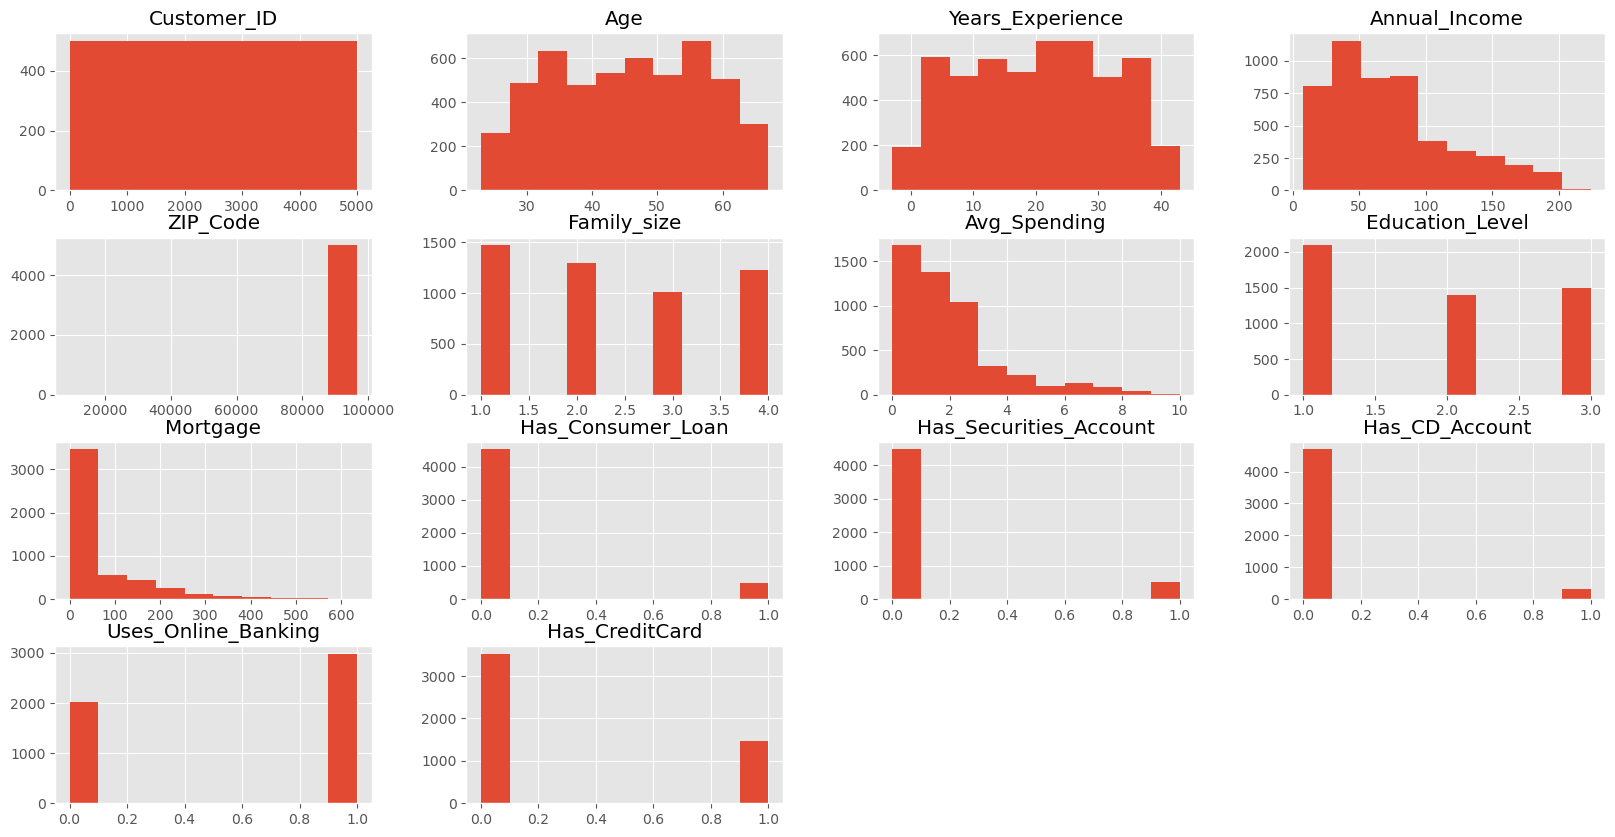

In [8]:
plt.rcParams["figure.figsize"] = (20,10)
df_loan.hist();

In [9]:
#Customer_ID column is not needed and can be dropped.
df_loan.drop(['Customer_ID'],axis=1,inplace=True) 

**Customer_ID is not needed for feature selection hence dropped.**

# 3. Data Pre-processing and cleaning                

1) Processing Zipcode:  
    Zipcode is a categorical feature and can be a good predictor of target variable.   We can analyse if there is any pattern on location for customers who had borrowed loaned during previous campaign.  Trying to see if we can reduce the category

In [10]:
df_loan.rename(columns={"ZIP Code":"ZIP_Code","Personal Loan":"Has_Consumer_Loan","Securities Account":"Has_Securities_Account","CD Account":'Has_CD_Account'},inplace=True)

In [11]:
df_loan.ZIP_Code.nunique()

467

In [12]:
# get unique zipcodes
list_zipcode=df_loan.ZIP_Code.unique()

In [13]:
#here i am creating a dictionary of county by using library zipcode and matching method.
dict_zip={}
for zipcode in list_zipcode:
    my_city_county = zcode.matching(zipcode.astype('str'))
    if len(my_city_county)==1: # if  zipcode is present then get county else, assign zipcode to county
        county=my_city_county[0].get('county')
    else:
        county=zipcode
    
    dict_zip.update({zipcode:county})

In [14]:
dict_zip

{91107: 'Los Angeles County',
 90089: 'Los Angeles County',
 94720: 'Alameda County',
 94112: 'San Francisco County',
 91330: 'Los Angeles County',
 92121: 'San Diego County',
 91711: 'Los Angeles County',
 93943: 'Monterey County',
 93023: 'Ventura County',
 94710: 'Alameda County',
 90277: 'Los Angeles County',
 93106: 'Santa Barbara County',
 94920: 'Marin County',
 91741: 'Los Angeles County',
 95054: 'Santa Clara County',
 95010: 'Santa Cruz County',
 94305: 'Santa Clara County',
 91604: 'Los Angeles County',
 94015: 'San Mateo County',
 90095: 'Los Angeles County',
 91320: 'Ventura County',
 95521: 'Humboldt County',
 95064: 'Santa Cruz County',
 90064: 'Los Angeles County',
 94539: 'Alameda County',
 94104: 'San Francisco County',
 94117: 'San Francisco County',
 94801: 'Contra Costa County',
 94035: 'Santa Clara County',
 92647: 'Orange County',
 95814: 'Sacramento County',
 94114: 'San Francisco County',
 94115: 'San Francisco County',
 92672: 'Orange County',
 94122: 'San Fra

We got almost all county expect for 96651,92634,93077,92717. We can fix this zip code by searching internet. Couldn't find for other zipcodes.
92717
9307
92634
96651

In [15]:
dict_zip.update({92717:'Orange County'})
dict_zip.update({92634:'Orange County'})

In [16]:
df_loan['County']=df_loan['ZIP_Code'].map(dict_zip)

In [17]:
df_loan.County.nunique()

40

In [18]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     5000 non-null   int64  
 1   Years_Experience        5000 non-null   int64  
 2   Annual_Income           5000 non-null   int64  
 3   ZIP_Code                5000 non-null   int64  
 4   Family_size             5000 non-null   int64  
 5   Avg_Spending            5000 non-null   float64
 6   Education_Level         5000 non-null   int64  
 7   Mortgage                5000 non-null   int64  
 8   Has_Consumer_Loan       5000 non-null   int64  
 9   Has_Securities_Account  5000 non-null   int64  
 10  Has_CD_Account          5000 non-null   int64  
 11  Uses_Online_Banking     5000 non-null   int64  
 12  Has_CreditCard          5000 non-null   int64  
 13  County                  5000 non-null   object 
dtypes: float64(1), int64(12), object(1)
memo

**Fixing the data types**  
Has_Consumer_Loan, Securities_Account, CD_Account, 'Online', 'CreditCard' ,Education are of int/object type,
we can change them to category type to reduce the dataspace required.


In [19]:
# converting categorical varaible to category type
category_col = ['Has_Consumer_Loan', 'Has_Securities_Account','Family_size', 'Has_CD_Account', 'Uses_Online_Banking', 'Has_CreditCard', 'ZIP_Code', 'Education_Level','County']
df_loan[category_col] = df_loan[category_col].astype('category')

In [20]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Age                     5000 non-null   int64   
 1   Years_Experience        5000 non-null   int64   
 2   Annual_Income           5000 non-null   int64   
 3   ZIP_Code                5000 non-null   category
 4   Family_size             5000 non-null   category
 5   Avg_Spending            5000 non-null   float64 
 6   Education_Level         5000 non-null   category
 7   Mortgage                5000 non-null   int64   
 8   Has_Consumer_Loan       5000 non-null   category
 9   Has_Securities_Account  5000 non-null   category
 10  Has_CD_Account          5000 non-null   category
 11  Uses_Online_Banking     5000 non-null   category
 12  Has_CreditCard          5000 non-null   category
 13  County                  5000 non-null   category
dtypes: category(9), float64(

In [21]:
df_loan.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,5000.00000,45.33840,11.46317,23.00000,35.00000,45.00000,55.00000,67.00000
Years_Experience,5000.00000,20.10460,11.46795,-3.00000,10.00000,20.00000,30.00000,43.00000
Annual_Income,5000.00000,73.77420,46.03373,8.00000,39.00000,64.00000,98.00000,224.00000
Avg_Spending,5000.00000,1.93794,1.74766,0.00000,0.70000,1.50000,2.50000,10.00000
Mortgage,5000.00000,56.49880,101.71380,0.00000,0.00000,0.00000,101.00000,635.00000


In [22]:
# checking negative and zero values for Years_Years_Years_Years_Experience. 
df_loan[df_loan['Years_Experience']<0]['Age'].describe()

count   52.00000
mean    24.51923
std      1.47516
min     23.00000
25%     24.00000
50%     24.00000
75%     25.00000
max     29.00000
Name: Age, dtype: float64

52 customers from age group 23 - 30 have negative values in Years_Years_Years_Years_Experience

In [23]:
df_loan[df_loan['Years_Experience']<0].sort_values(by='Years_Experience',ascending=True)

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County
4514,24,-3,41,91768,4,1.00000,3,0,0,0,0,1,0,Los Angeles County
2618,23,-3,55,92704,3,2.40000,2,145,0,0,0,1,0,Orange County
4285,23,-3,149,93555,2,7.20000,1,0,0,0,0,1,0,Kern County
3626,24,-3,28,90089,4,1.00000,3,0,0,0,0,0,0,Los Angeles County
2717,23,-2,45,95422,4,0.60000,2,0,0,0,0,1,1,Lake County
2876,24,-2,80,91107,2,1.60000,3,238,0,0,0,0,0,Los Angeles County
3130,23,-2,82,92152,2,1.80000,2,0,0,1,0,0,1,San Diego County
2466,24,-2,80,94105,2,1.60000,3,0,0,0,0,1,0,San Francisco County
3796,24,-2,50,94920,3,2.40000,2,0,0,1,0,0,0,Marin County
2962,23,-2,81,91711,2,1.80000,2,0,0,0,0,0,0,Los Angeles County


In [24]:
df_loan.groupby(['Age','Education_Level'])['Years_Experience'].describe().T

Age                   23                24                         25  \
Education_Level        1        2        1        2        3        1   
count            7.00000  5.00000 13.00000  8.00000  7.00000 23.00000   
mean            -1.28571 -2.20000 -0.69231 -0.87500 -2.00000  0.52174   
std              0.75593  0.44721  0.94733  0.64087  1.00000  0.79026   
min             -3.00000 -3.00000 -2.00000 -2.00000 -3.00000 -1.00000   
25%             -1.00000 -2.00000 -2.00000 -1.00000 -2.50000  0.00000   
50%             -1.00000 -2.00000  0.00000 -1.00000 -2.00000  1.00000   
75%             -1.00000 -2.00000  0.00000 -0.75000 -2.00000  1.00000   
max             -1.00000 -2.00000  0.00000  0.00000  0.00000  1.00000   

Age                                     26           ...       64       65  \
Education_Level        2        3        1        2  ...        3        1   
count           11.00000 19.00000 30.00000 24.00000  ... 30.00000 30.00000   
mean            -0.27273 -0.52632  1.43333  0.75000  ... 38.53333 39.86667   
std              0.64667  0.69669  0.81720  0.84699  ...  1.75643  0.73030   
min             -1.00000 -2.00000  0.00000 -1.00000  ... 34.00000 39.00000   
25%             -1.00000 -1.00000  1.00000  0.00000  ... 38.00000 39.00000   
50%              0.00000 -1.00000  2.00000  1.00000  ... 39.00000 40.00000   
75%              0.00000  0.00000  2.00000  1.00000  ... 40.00000 40.00000   
max              1.00000  1.00000  2.00000  2.00000  ... 40.00000 41.00000   

Age                                     66                         67  \
Education_Level        2        3        1        2        3        1   
count           23.00000 27.00000  9.00000  5.00000 10.00000  5.00000   
mean            40.08696 39.51852 41.11111 41.40000 40.40000 41.60000   
std              0.73318  1.55342  0.33333  0.54772  1.64655  0.89443   
min             39.00000 35.00000 41.00000 41.00000 36.00000 41.00000   
25%             40.00000 39.00000 41.00000 41.00000 40.25000 41.00000   
50%             40.00000 40.00000 41.00000 41.00000 41.00000 41.00000   
75%             41.00000 41.00000 41.00000 42.00000 41.00000 42.00000   
max             41.00000 41.00000 42.00000 42.00000 42.00000 43.00000   

Age                                
Education_Level        2        3  
count            3.00000  4.00000  
mean            42.66667 41.50000  
std              0.57735  0.57735  
min             42.00000 41.00000  
25%             42.50000 41.00000  
50%             43.00000 41.50000  
75%             43.00000 42.00000  
max             43.00000 42.00000  

[8 rows x 134 columns]

**Its seems Years_Experience is negative for all observation with for age 23,24, and few others .   Based on there age and education it seems values were negative by mistake. so changing it to absoulte values of Years_Years_Years_Years_Experience.**

In [25]:
df_loan.loc[df_loan['Years_Experience']<0,'Years_Experience']=np.abs(df_loan['Years_Experience'])

In [26]:
df_loan[df_loan['Years_Experience']==0]['Age'].describe()

count   66.00000
mean    25.63636
std      1.14538
min     24.00000
25%     25.00000
50%     26.00000
75%     26.00000
max     30.00000
Name: Age, dtype: float64


Checking age and Annual_Income for customers with 0 Years_Years_Years_Years_Experience. We will see how to impute this columns more after ED


# 4. Exploratory Data Analysis

In [27]:
df_loan.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.00000,45.33840,11.46317,23.00000,35.00000,45.00000,55.00000,67.00000
Years_Experience,5000.00000,20.13460,11.41519,0.00000,10.00000,20.00000,30.00000,43.00000
Annual_Income,5000.00000,73.77420,46.03373,8.00000,39.00000,64.00000,98.00000,224.00000
Avg_Spending,5000.00000,1.93794,1.74766,0.00000,0.70000,1.50000,2.50000,10.00000
Mortgage,5000.00000,56.49880,101.71380,0.00000,0.00000,0.00000,101.00000,635.00000


In [28]:
for column in category_col:
    print(df_loan[column].value_counts())
    print("*" * 100)

Has_Consumer_Loan
0    4520
1     480
Name: count, dtype: int64
****************************************************************************************************
Has_Securities_Account
0    4478
1     522
Name: count, dtype: int64
****************************************************************************************************
Family_size
1    1472
2    1296
4    1222
3    1010
Name: count, dtype: int64
****************************************************************************************************
Has_CD_Account
0    4698
1     302
Name: count, dtype: int64
****************************************************************************************************
Uses_Online_Banking
1    2984
0    2016
Name: count, dtype: int64
****************************************************************************************************
Has_CreditCard
0    3530
1    1470
Name: count, dtype: int64
************************************************************************************************

### Observations:
    - Customers age is in range of 23 - 67, with mean and median of ~45.
    - Maximum Years_Years_Years_Years_Experience is 43 years. where as mean and median are ~20.
    - Annual_Income are in range 8k to 224k USD. Mean is 73k USD and median is 64k USD. 224k Max salary need to be verified                                    
    - Maximum mortgage taken is 635k USD.Need to verify this  
    - Average spending on credit card per month ranges from 1- 10k with mean of 1.9kUSD and median of 1.5k USD  
    - 1095 customers are from Los Angeles County.
    - 480 customers had borrowed loan before.

## 4.1 Univariate Analysis

In [29]:
def dist_box(data):
 # function plots a combined graph for univariate analysis of continous variable 
 #to check spread, central tendency , dispersion and outliers  
    Name=data.name.upper()
    fig,(ax_box,ax_dis)  =plt.subplots(nrows=2,sharex=True,gridspec_kw = {"height_ratios": (.25, .75)},figsize=(8, 5))
    mean=data.mean()
    median=data.median()
    mode=data.mode().tolist()[0]
    sns.set_theme(style="white")
    fig.suptitle("SPREAD OF DATA FOR "+ Name  , fontsize=18, fontweight='bold')
    sns.boxplot(x=data,showmeans=True, orient='h',color="violet",ax=ax_box)
    ax_box.set(xlabel='')
     # just trying to make visualisation better. This will set background to white
    sns.despine(top=True,right=True,left=True) # to remove side line from graph
    sns.distplot(data,kde=False,color='blue',ax=ax_dis)
    ax_dis.axvline(mean, color='r', linestyle='--',linewidth=2)
    ax_dis.axvline(median, color='g', linestyle='-',linewidth=2)
    ax_dis.axvline(mode, color='y', linestyle='-',linewidth=2)
    plt.legend({'Mean':mean,'Median':median,'Mode':mode})

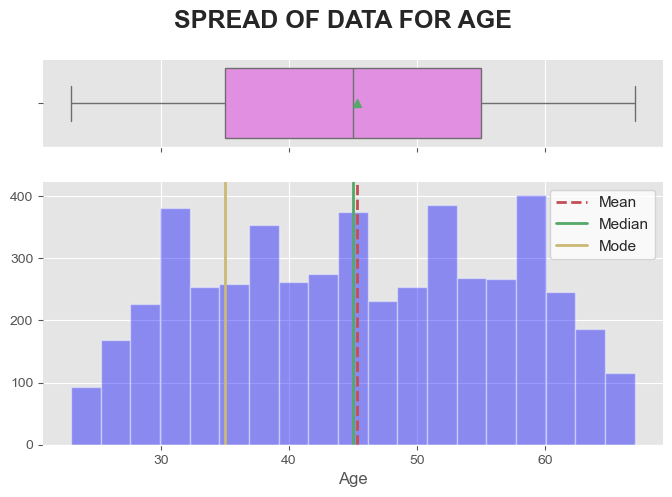

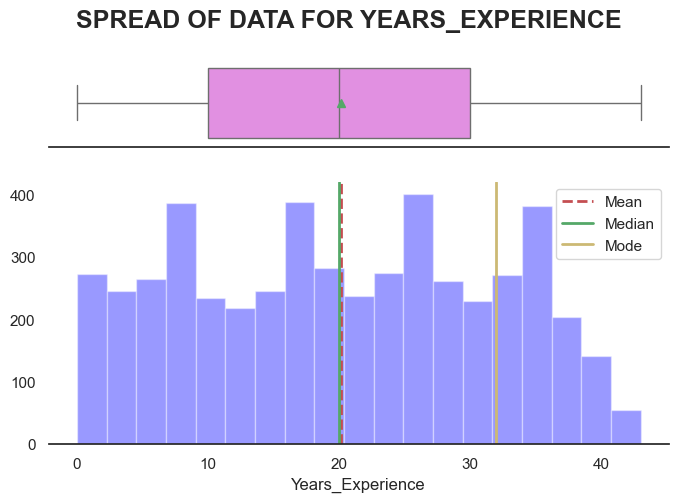

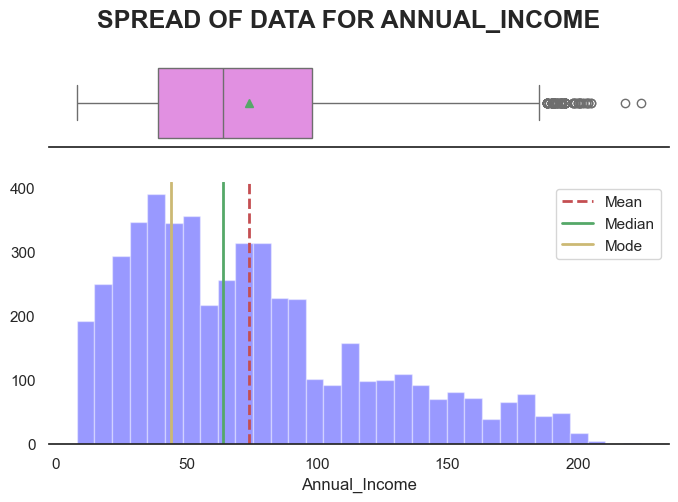

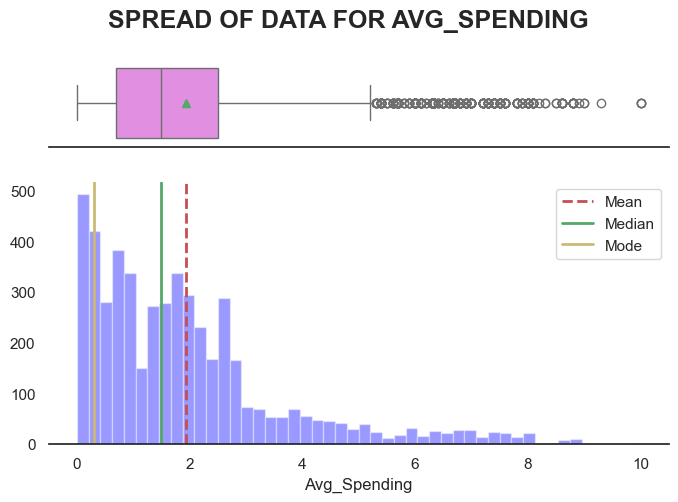

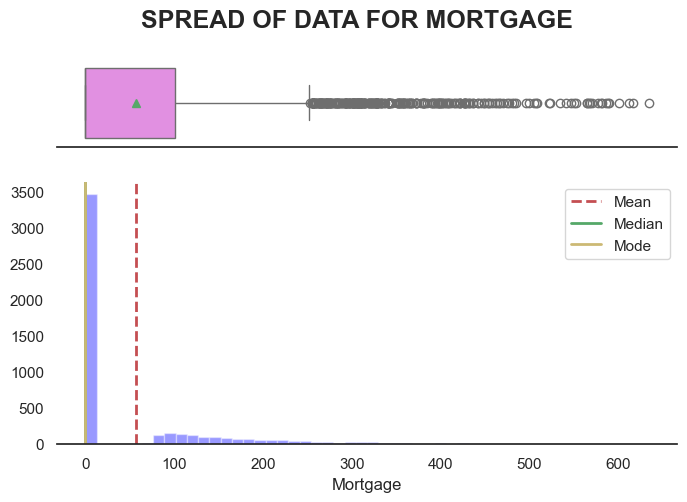

In [30]:
#select all quantitative columns for checking the spread
list_col=  ['Age','Years_Experience','Annual_Income','Avg_Spending','Mortgage']
for i in range(len(list_col)):
    dist_box(df_loan[list_col[i]])

### Observations:
- Age and Years_Years_Years_Years_Experience both has same distrubtion with spike at 5 points.
- Annual_Income is right skewed and has some outlier on higher side which can be clipped.
- Average montly credit is right skewed and has lot of outliers on higher side which can be clipped.
- Mortgage is mostly 0 . but is right skewed and has lot of outlier on higher side which can be clipped.

Age  
Age can be a vital factor in borrowinng loan, converting ages to bin to explore if there is any pattern

In [31]:
df_loan['Agebin'] = pd.cut(df_loan['Age'], bins = [0, 30, 40, 50, 60, 100], labels = ['18-30', '31-40', '41-50', '51-60', '60-100'])

Annual_Income:  

To understand customers segments derving new columns which will help us identify if customer belongs to Upper , middle or lower Annual_Income group


In [32]:
# Create a new variable - Annual_Income group

df_loan["Income_group"] = pd.cut(
    x=df["Annual_Income"],
    bins=[0, 50, 140, 224],
    labels=["Lower", "Middle", "High"],
)


Spending

To understand customers spending derving new columns which will say if customer belongs to Upper , middle or lower spending


In [33]:
df_loan.Avg_Spending.describe()

count   5000.00000
mean       1.93794
std        1.74766
min        0.00000
25%        0.70000
50%        1.50000
75%        2.50000
max       10.00000
Name: Avg_Spending, dtype: float64

In [34]:
df_loan["Spending_group"] = pd.cut( x=df_loan["Avg_Spending"], bins=[0.00000, 0.70000, 2.50000, 10.00000],
    labels=["Low", "Medium", "High"],include_lowest=True ,
)

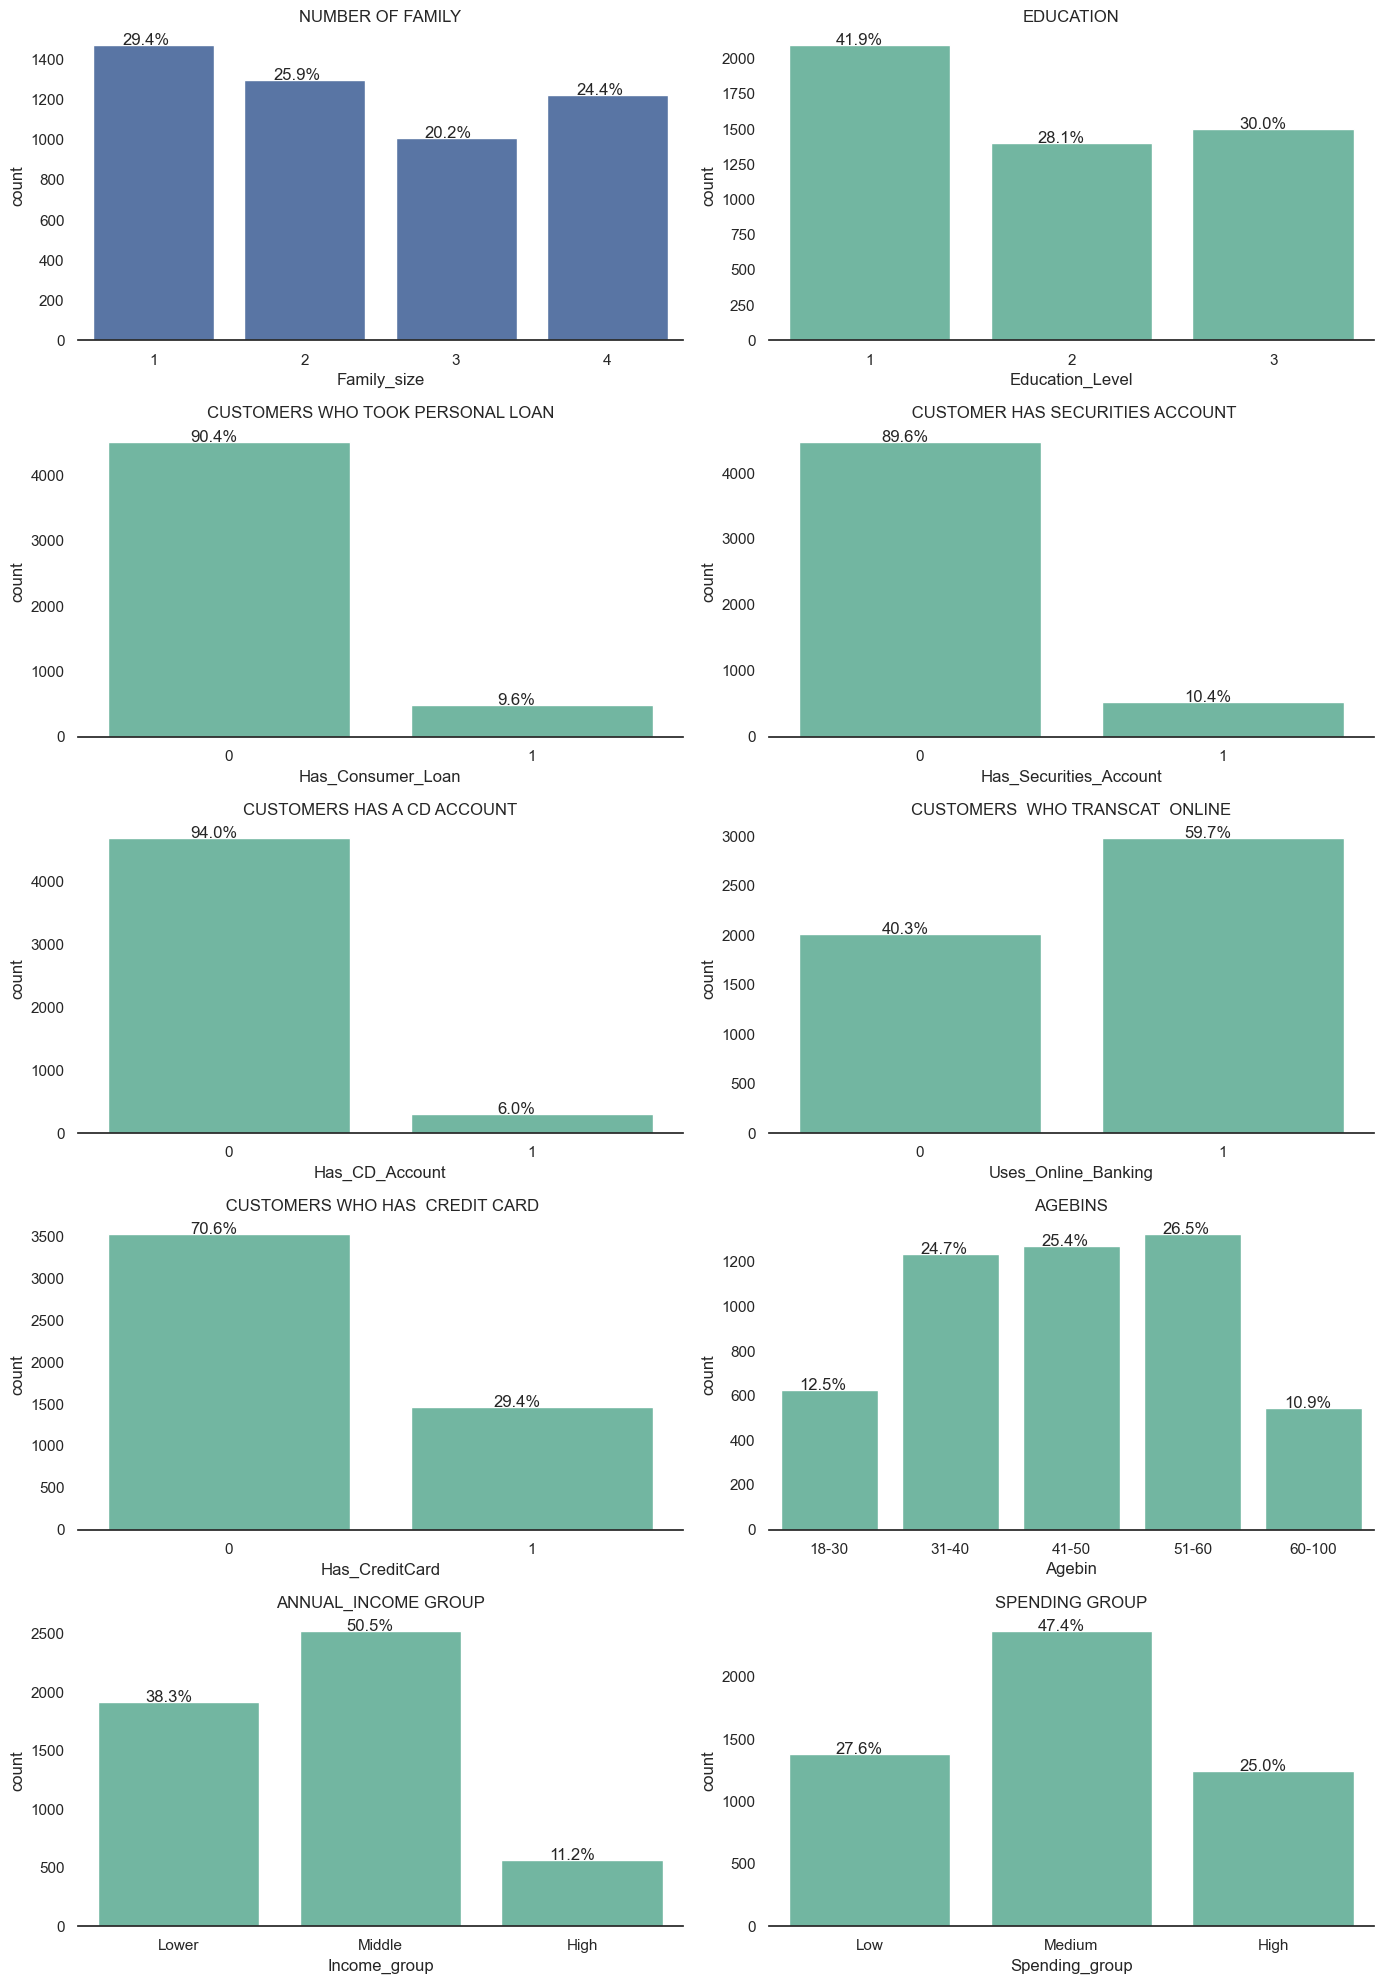

In [35]:
# Making a list of all categorical variables
cat_columns = ['Family_size','Education_Level','Has_Consumer_Loan','Has_Securities_Account',
               'Has_CD_Account','Uses_Online_Banking','Has_CreditCard','Agebin','Income_group','Spending_group']
title=['Number of Family','Education','Customers who took Personal Loan',
       ' Customer has Securities Account','Customers has a CD Account',
       'Customers  who transcat  Online',' Customers who has  Credit Card','Agebins',"Annual_Income group",'Spending group']
plt.figure(figsize=(14,20))

sns.set_theme(style="white") # just trying to make visualisation better. This will set background to white
#list_palette=['Blues_r','Greens_r','Purples_r','Reds_r','Blues_r','Greens_r','Purples_r','Reds_r','Blues_r']

for i, variable in enumerate(cat_columns):
                     plt.subplot(5,2,i+1)
                     order = df_loan[variable].value_counts(ascending=False).index   
                     #sns.set_palette(list_palette[i]) # to set the palette
                     sns.set_palette('Set2')
                     ax=sns.countplot(x=df_loan[variable], data=df_loan )
                     sns.despine(top=True,right=True,left=True) # to remove side line from graph
                     for p in ax.patches:
                           percentage = '{:.1f}%'.format(100 * p.get_height()/len(df_loan[variable]))
                           x = p.get_x() + p.get_width() / 2 - 0.05
                           y = p.get_y() + p.get_height()
                           plt.annotate(percentage, (x, y),ha='center')
                     plt.tight_layout()
                     plt.title(title[i].upper())
                                     

### 
Observation  

    ~29.4 % customers are single.
    ~41.9% customers are undergrad.
    ~9.6% bought a personal loan from the bank.
    10.4 % customers have a securities account with the bank
    6 % customer have a CD account.
    60% customers transact online.
    29.4% customers have credit cards.
    ~ 75 % of customers are in range of 31- 60.
    ~ 50 % Most of bank customers belong to middle Annual_Income group.
    ~48 % of customers has medium Avere spending



In [36]:
df_loan.groupby(['County','Has_Consumer_Loan'])['Has_Consumer_Loan'].agg({'size'}).unstack()

size     
Has_Consumer_Loan         0    1
County                          
9307                      1    0
96651                     6    0
Alameda County          456   44
Butte County             17    2
Contra Costa County      73   12
El Dorado County         16    1
Fresno County            24    2
Humboldt County          30    2
Imperial County           3    0
Kern County              47    7
Lake County               4    0
Los Angeles County      984  111
Marin County             48    6
Mendocino County          7    1
Merced County             4    0
Monterey County         113   15
Napa County               3    0
Orange County           333   33
Placer County            22    2
Riverside County         50    6
Sacramento County       169   15
San Benito County        14    0
San Bernardino County    98    3
San Diego County        509   59
San Francisco County    238   19
San Joaquin County       12    1
San Luis Obispo County   28    5
San Mateo County        192   12
Santa Barbara County    143   11
Santa Clara County      492   71
Santa Cruz County        60    8
Shasta County            15    3
Siskiyou County           7    0
Solano County            30    3
Sonoma County            22    6
Stanislaus County        14    1
Trinity County            4    0
Tuolumne County           7    0
Ventura County          103   11
Yolo County             122    8

<Axes: ylabel='County'>

<Figure size 1500x2400 with 0 Axes>

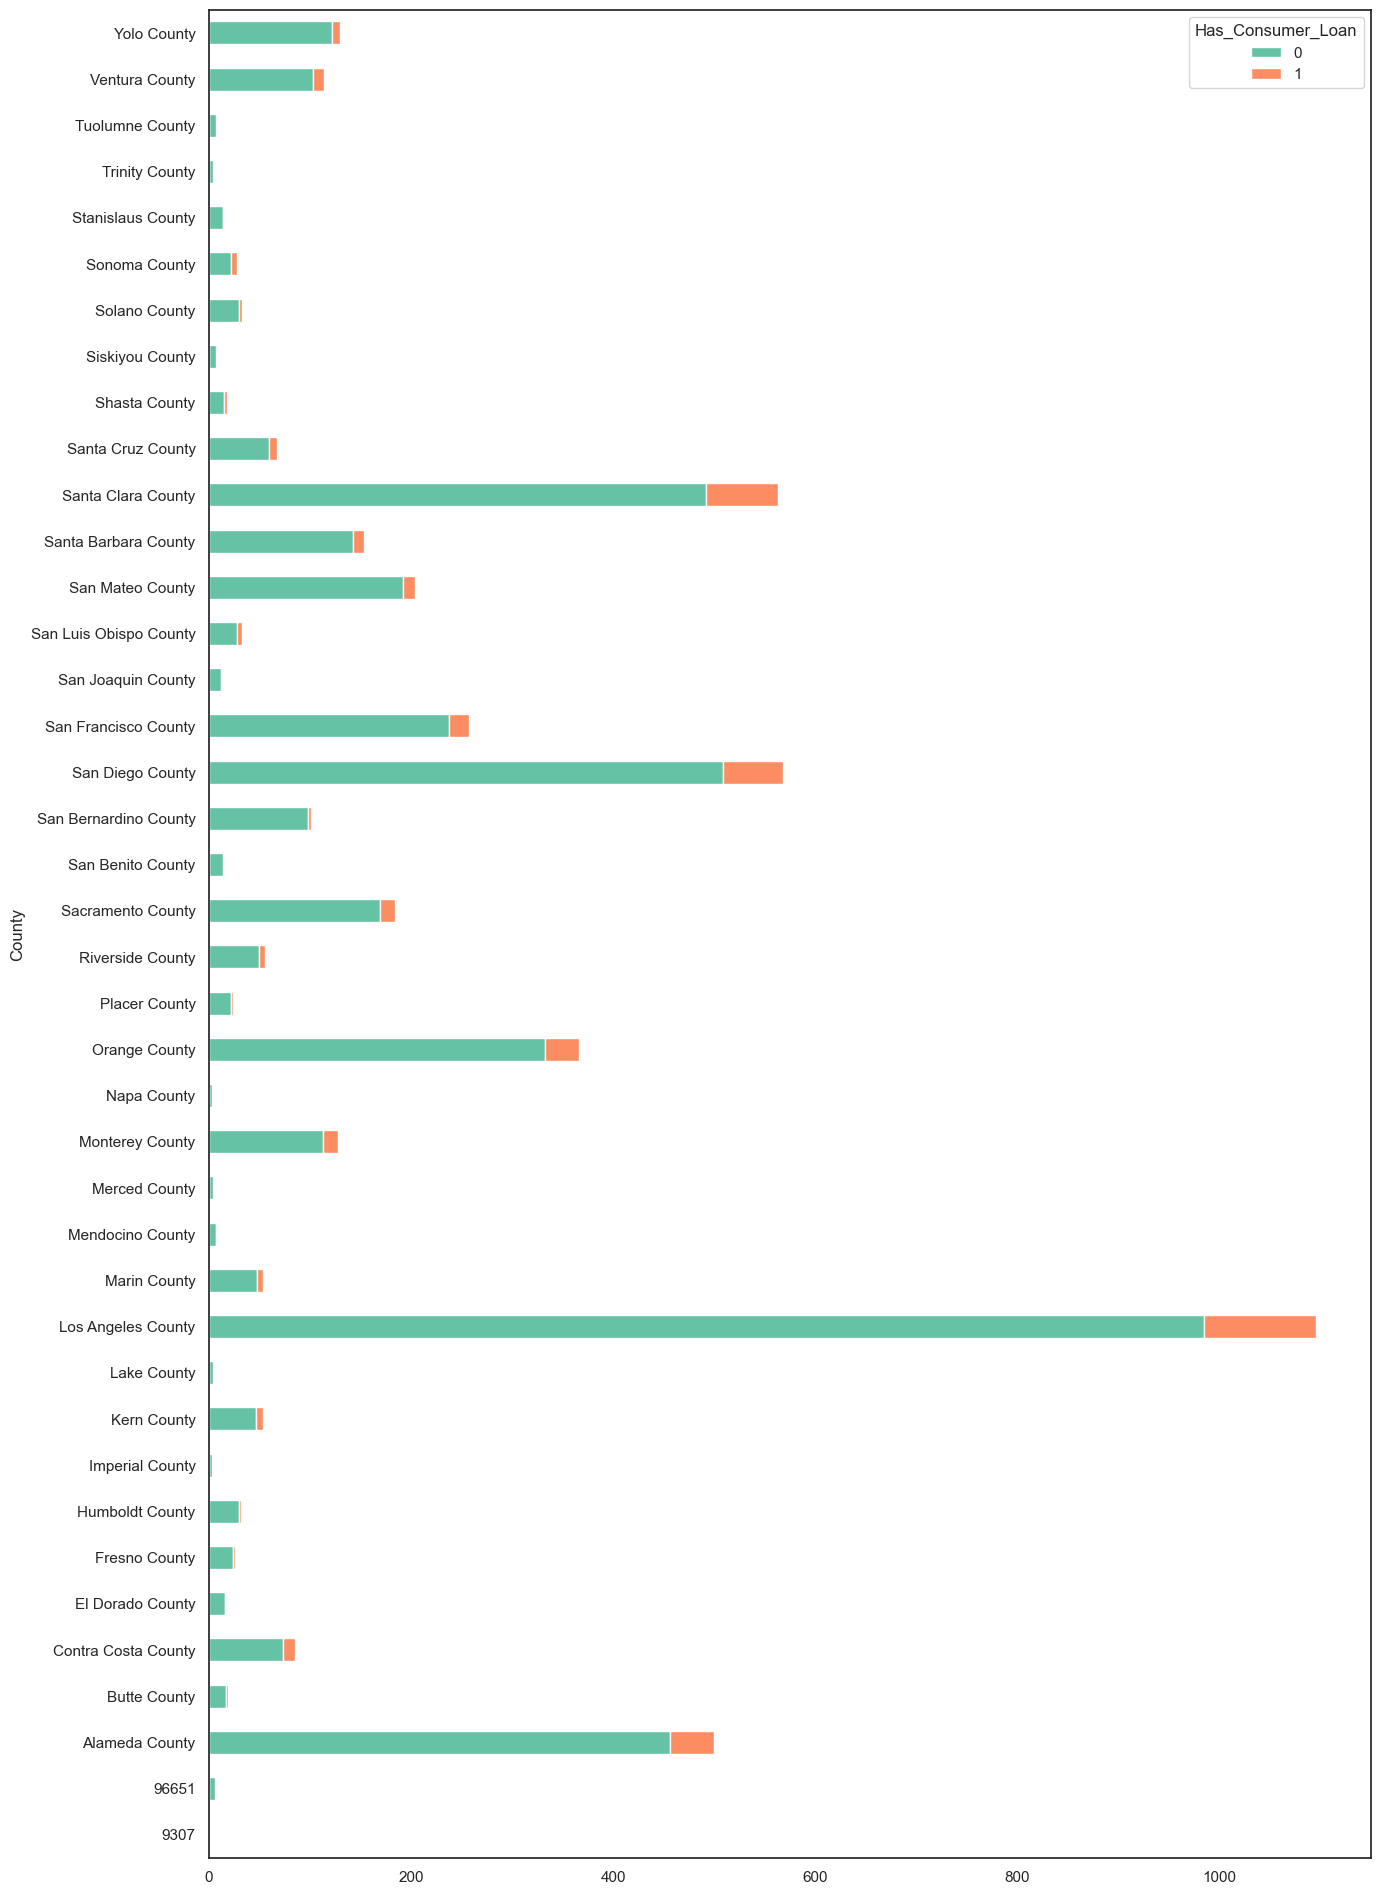

In [37]:
plt.figure(figsize=(15,24))

pd.crosstab(index=df_loan['County'],columns=df_loan['Has_Consumer_Loan'].sort_values(ascending=False)).plot(kind='barh',stacked=True,figsize=(15,24))


It can be seen the percentage of loan taken from various country differ.There are so many county converting them to regions will help in our model


In [38]:
counties = {
'Los Angeles County':'Los Angeles Region',
'San Diego County':'Southern',
'Santa Clara County':'Bay Area',
'Alameda County':'Bay Area',
'Orange County':'Southern',
'San Francisco County':'Bay Area',
'San Mateo County':'Bay Area',
'Sacramento County':'Central',
'Santa Barbara County':'Southern',
'Yolo County':'Central',
'Monterey County':'Bay Area',            
'Ventura County':'Southern',             
'San Bernardino County':'Southern',       
'Contra Costa County':'Bay Area',        
'Santa Cruz County':'Bay Area',           
'Riverside County':'Southern',            
'Kern County':'Southern',                 
'Marin County':'Bay Area',                
'San Luis Obispo County':'Southern',     
'Solano County':'Bay Area',              
'Humboldt County':'Superior',            
'Sonoma County':'Bay Area',                
'Fresno County':'Central',               
'Placer County':'Central',                
'Butte County':'Superior',               
'Shasta County':'Superior',                
'El Dorado County':'Central',             
'Stanislaus County':'Central',            
'San Benito County':'Bay Area',          
'San Joaquin County':'Central',           
'Mendocino County':'Superior',             
'Tuolumne County':'Central',                
'Siskiyou County':'Superior',              
'Trinity County':'Superior',                
'Merced County':'Central',                  
'Lake County':'Superior',                 
'Napa County':'Bay Area',                   
'Imperial County':'Southern',
93077:'Southern',
96651:'Bay Area'
}

In [39]:
#Converting the county to regions 
df_loan['Regions'] = df_loan['County'].map(counties)
df_loan['Regions'].unique()

array(['Los Angeles Region', 'Bay Area', 'Southern', 'Superior',
       'Central', nan], dtype=object)

In [40]:
df_loan.isnull().sum()

Age                       0
Years_Experience          0
Annual_Income             0
ZIP_Code                  0
Family_size               0
Avg_Spending              0
Education_Level           0
Mortgage                  0
Has_Consumer_Loan         0
Has_Securities_Account    0
Has_CD_Account            0
Uses_Online_Banking       0
Has_CreditCard            0
County                    0
Agebin                    0
Income_group              0
Spending_group            0
Regions                   1
dtype: int64

In [41]:
df_loan.dropna(inplace=True)

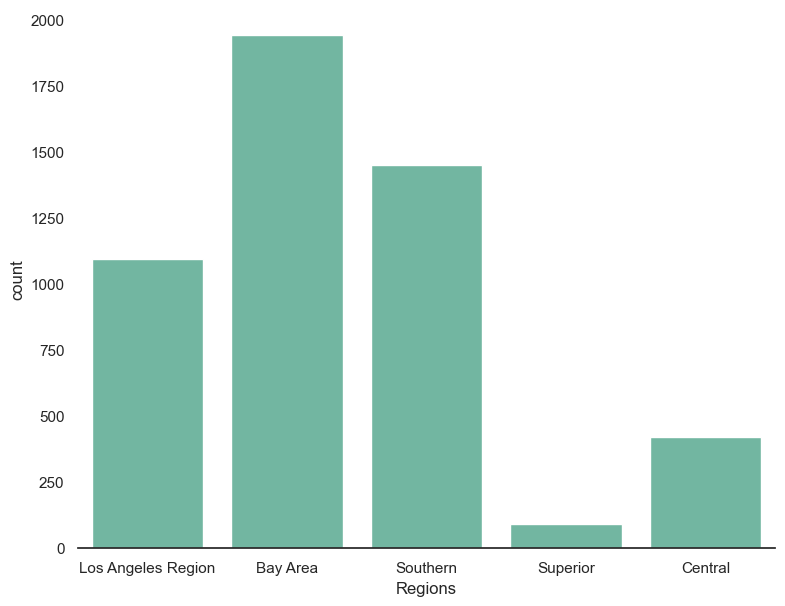

In [42]:
plt.figure(figsize=(9,7))
sns.countplot(data=df_loan,x=df_loan['Regions'])
# to remove side line from graph
sns.despine(top=True,right=True,left=True) 

Bivariate & Multivariate Analysis

In [43]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Age                     4999 non-null   int64   
 1   Years_Experience        4999 non-null   int64   
 2   Annual_Income           4999 non-null   int64   
 3   ZIP_Code                4999 non-null   category
 4   Family_size             4999 non-null   category
 5   Avg_Spending            4999 non-null   float64 
 6   Education_Level         4999 non-null   category
 7   Mortgage                4999 non-null   int64   
 8   Has_Consumer_Loan       4999 non-null   category
 9   Has_Securities_Account  4999 non-null   category
 10  Has_CD_Account          4999 non-null   category
 11  Uses_Online_Banking     4999 non-null   category
 12  Has_CreditCard          4999 non-null   category
 13  County                  4999 non-null   category
 14  Agebin                  4999 

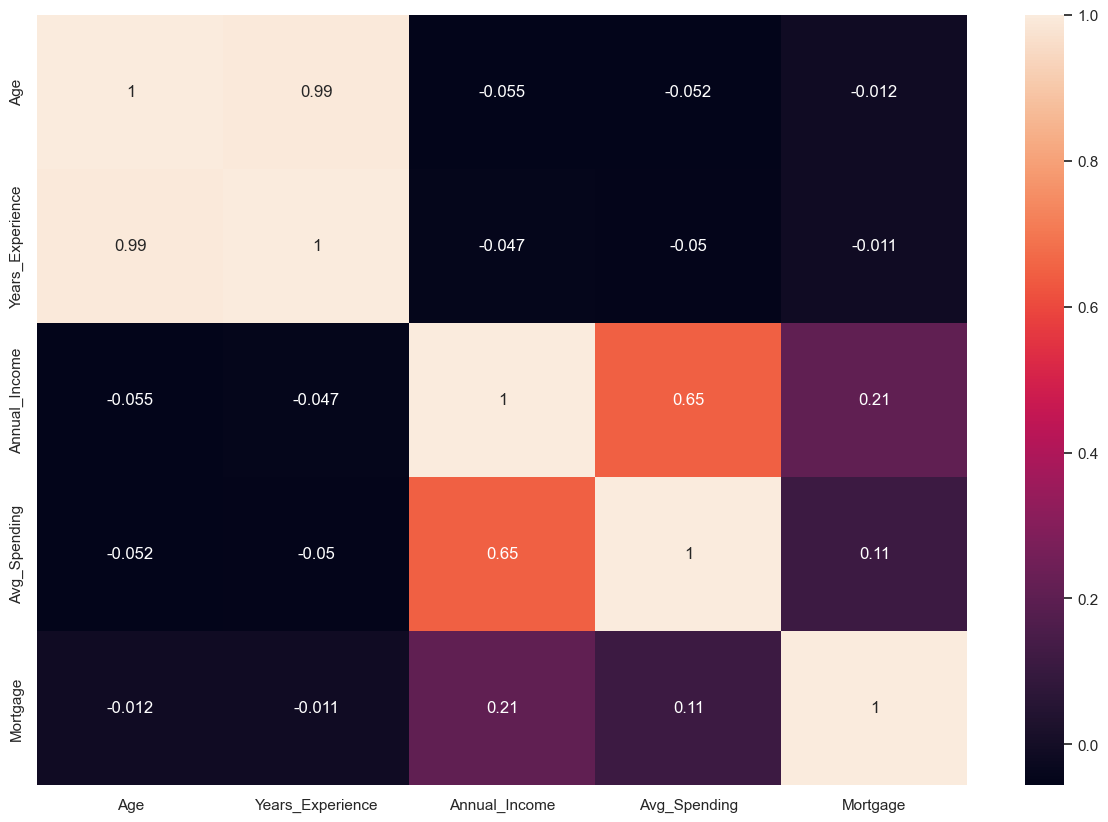

In [44]:
sns.set_palette(sns.color_palette("Set2", 8))
plt.figure(figsize=(15,10))
sns.heatmap(df_loan.corr(numeric_only=True),annot=True)
plt.show()

### 
Observations

    As expected Age ans_Years_Experience are highly correlated and one of them can be dropped.Since we had to handle 0, will drop Years_Years_Years_Years_Experience.
    Annual_Income and Average spending on credit card are positively corrleated.
    Mortgage has very little correlation with Annual_Income.



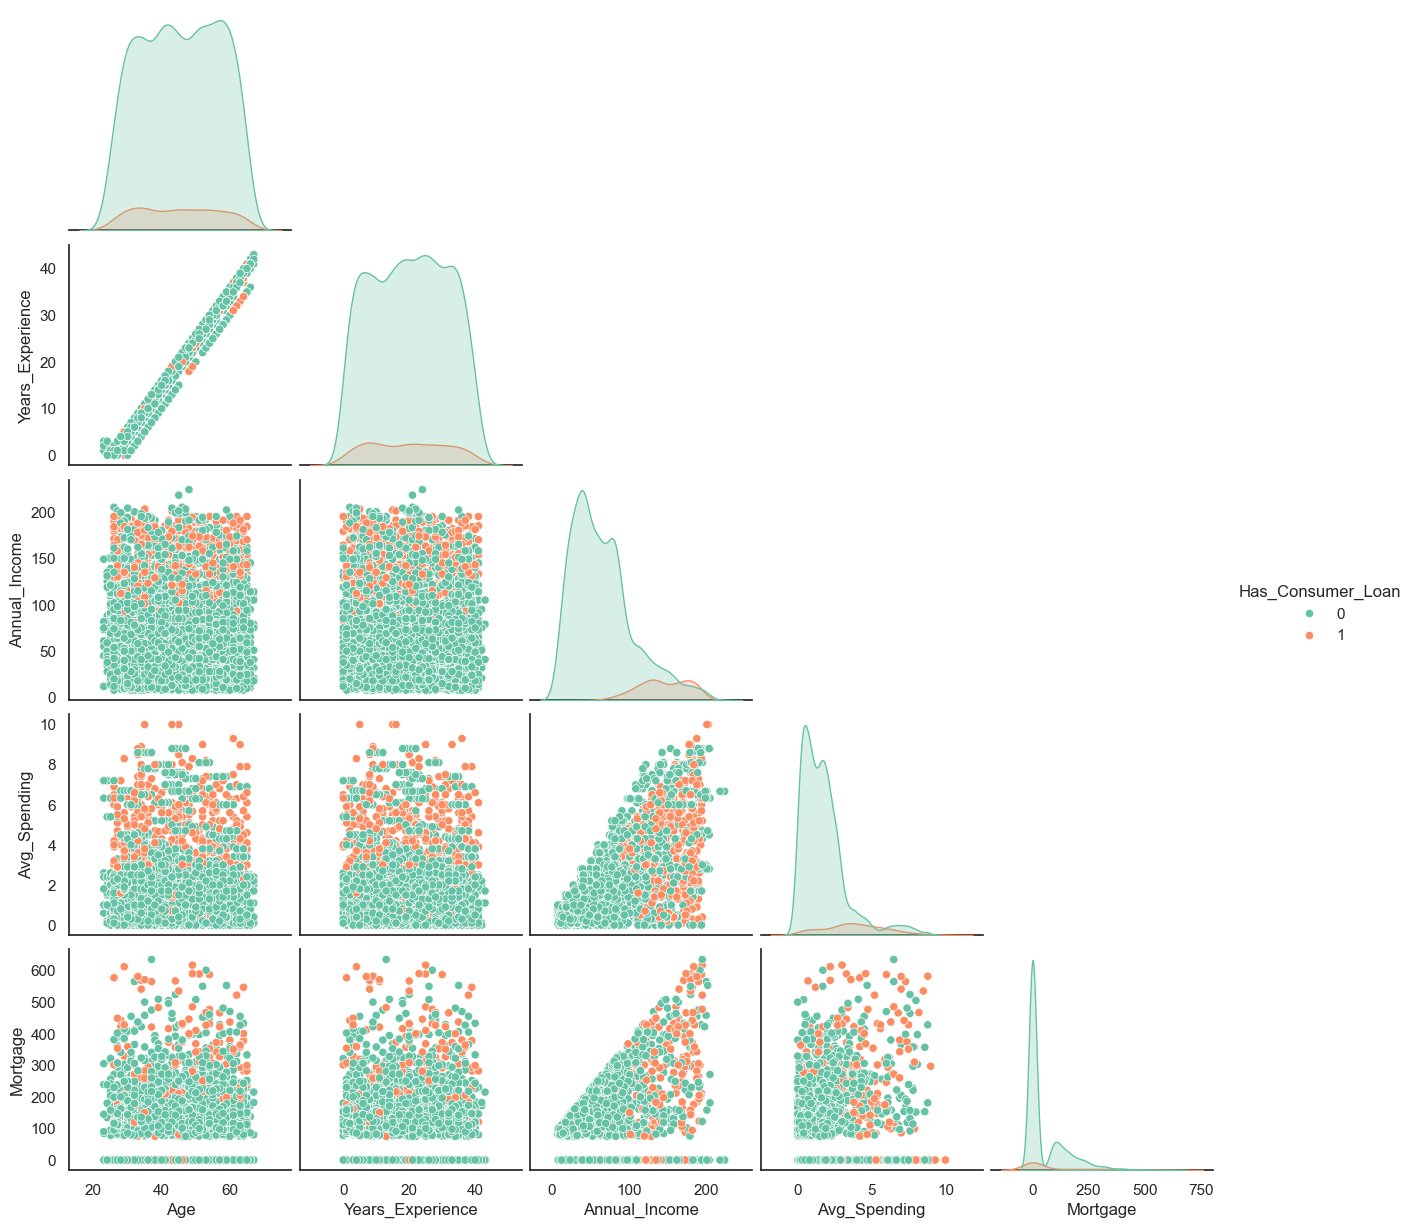

In [45]:
sns.set_palette(sns.color_palette("Set2", 8))
sns.pairplot(df_loan, hue="Has_Consumer_Loan",corner=True)
plt.show()

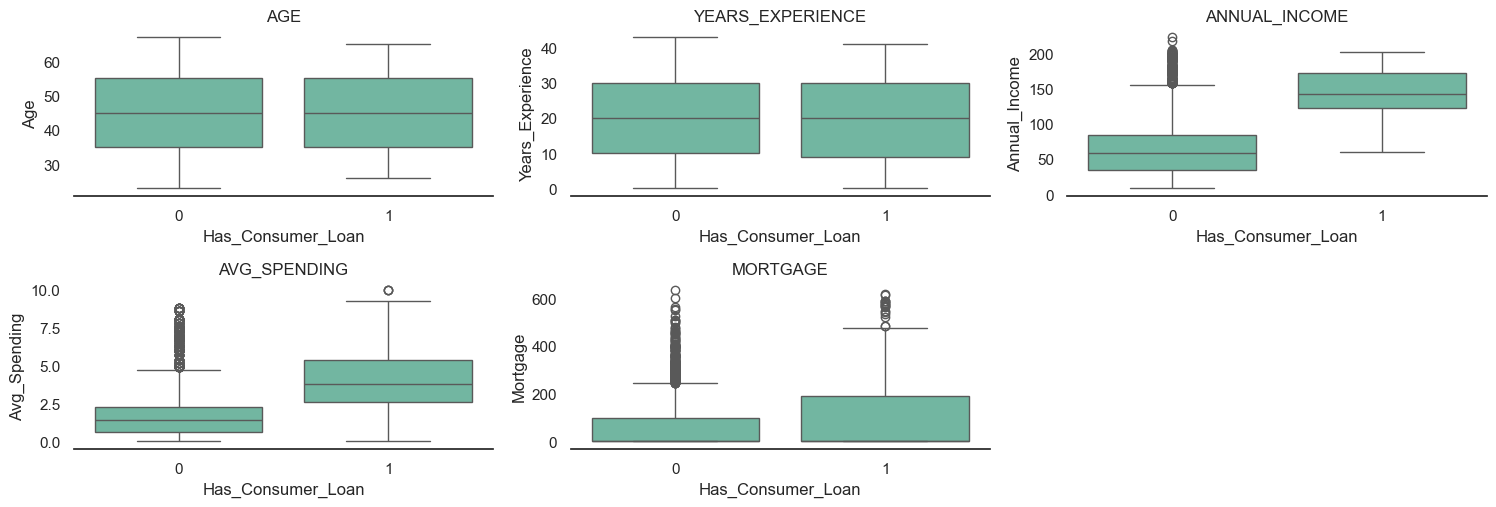

In [46]:
numeric_columns = ['Age','Years_Experience','Annual_Income','Avg_Spending','Mortgage']
plt.figure(figsize=(15,25))

sns.set_palette(sns.color_palette("Set2", 8))
for i, variable in enumerate(numeric_columns):
        plt.subplot(10,3,i+1)
        
        sns.boxplot(x='Has_Consumer_Loan',y= df_loan[variable], data=df_loan)     
        sns.despine(top=True,right=True,left=True) # to remove side line from graph
        plt.tight_layout()
        plt.title(variable.upper())

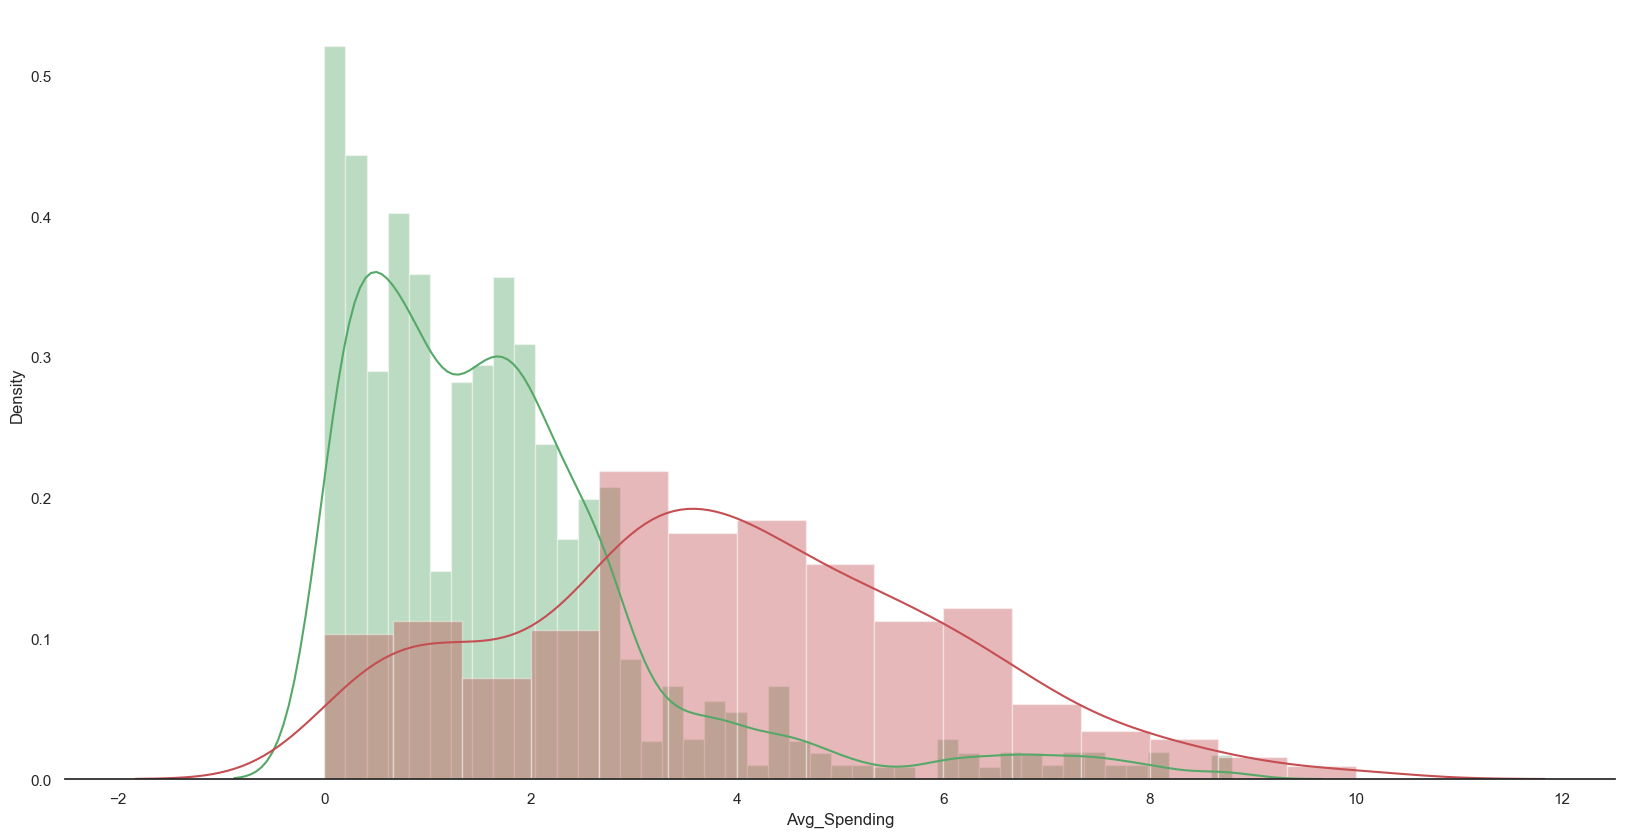

In [47]:
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 0]['Avg_Spending'], color = 'g')
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 1]['Avg_Spending'], color = 'r')
sns.despine(top=True,right=True,left=True) 

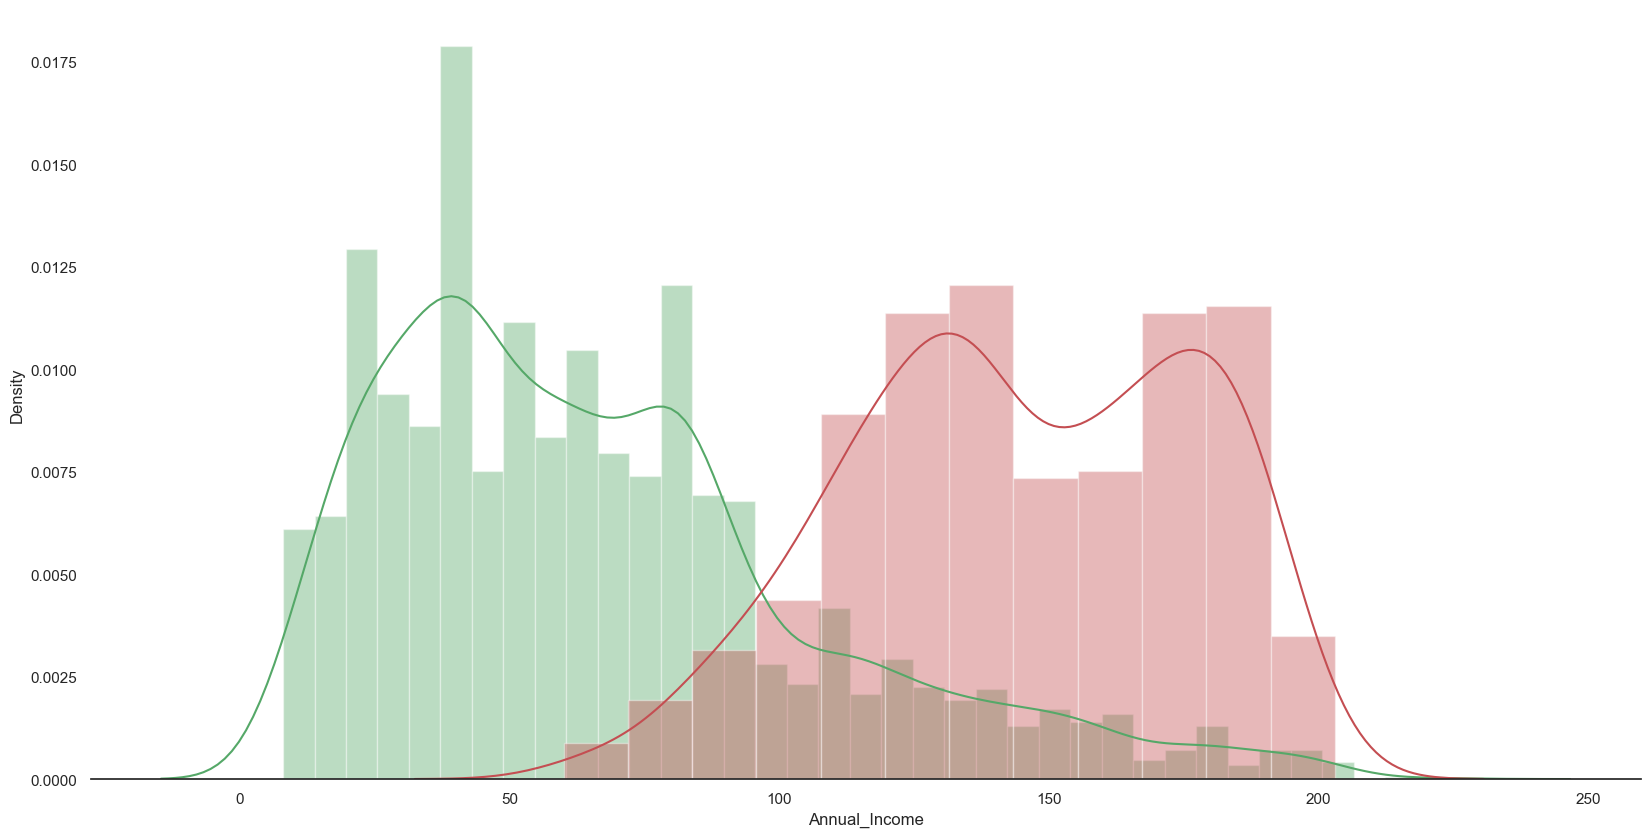

In [48]:
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 0]['Annual_Income'], color = 'g')
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 1]['Annual_Income'], color = 'r')
sns.despine(top=True,right=True,left=True) # to remove side line from graph

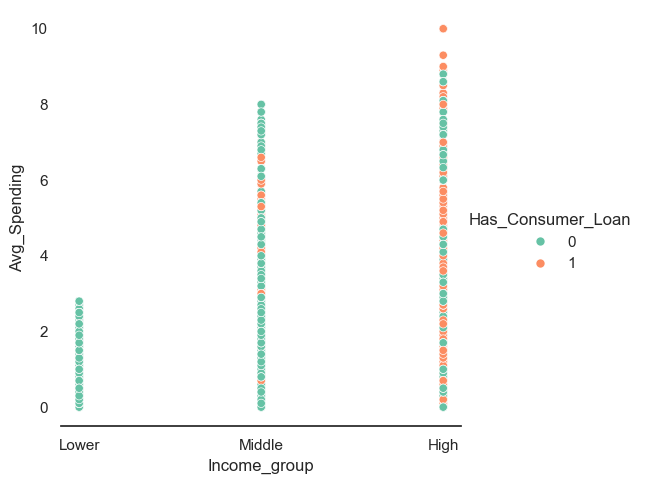

In [49]:
sns.relplot(x='Income_group',y='Avg_Spending',hue='Has_Consumer_Loan',data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph

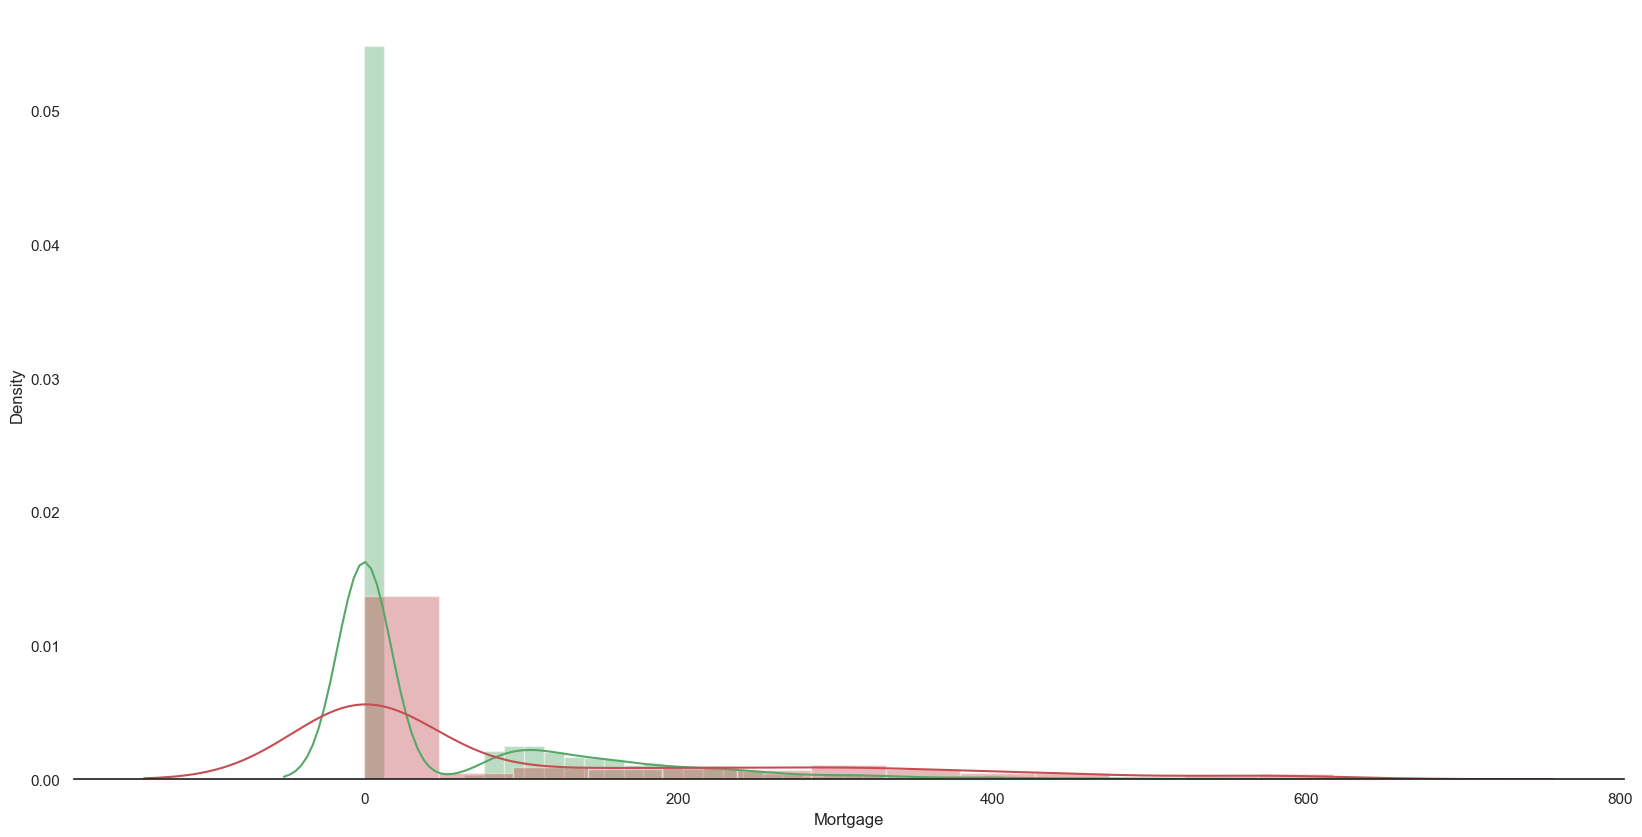

In [50]:
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 0]['Mortgage'], color = 'g')
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 1]['Mortgage'], color = 'r')
sns.despine(top=True,right=True,left=True) # to remove side line from graph

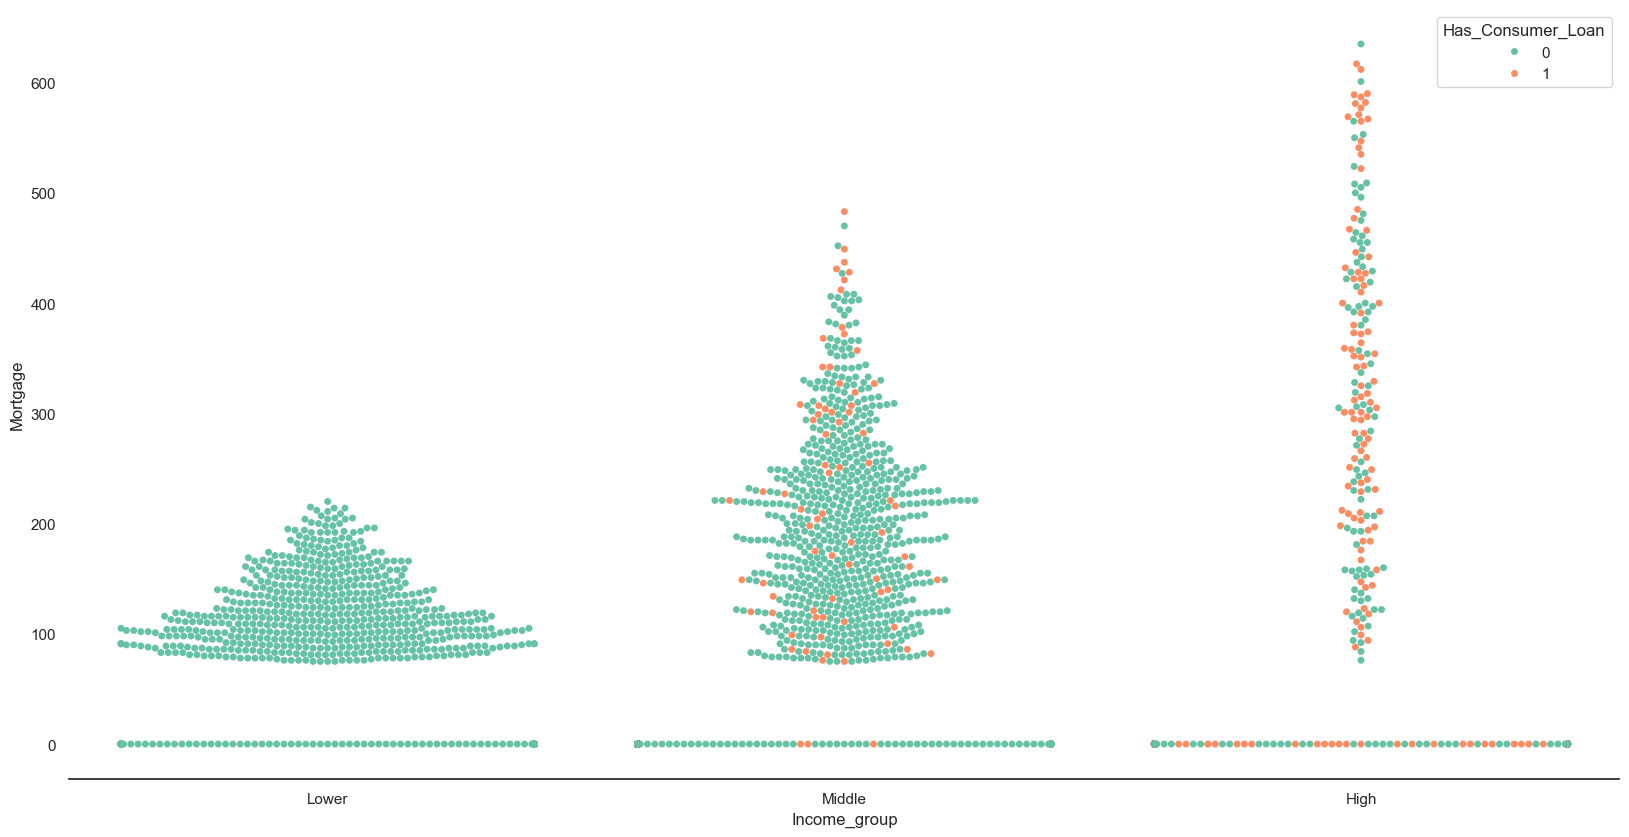

In [51]:
sns.swarmplot(x='Income_group',y='Mortgage',hue='Has_Consumer_Loan',data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph

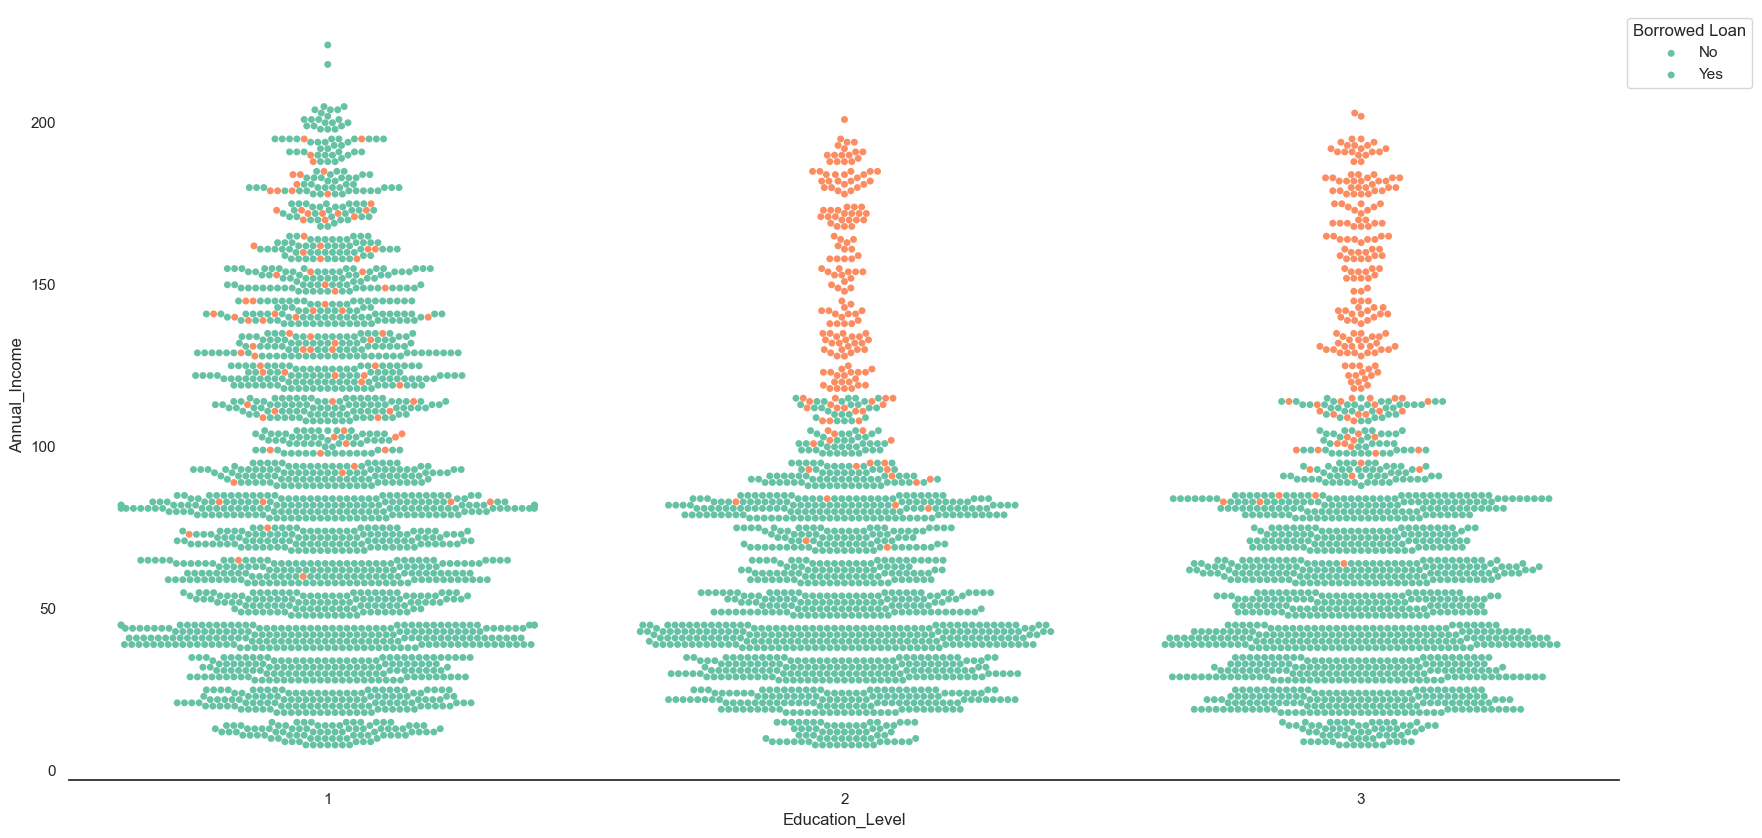

In [52]:
sns.swarmplot(x='Education_Level',y='Annual_Income',hue='Has_Consumer_Loan',data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph
labels=["No","Yes"]
plt.legend(loc='lower left', frameon=False,)
plt.legend(loc="upper left", labels=labels,title="Borrowed Loan",bbox_to_anchor=(1,1))

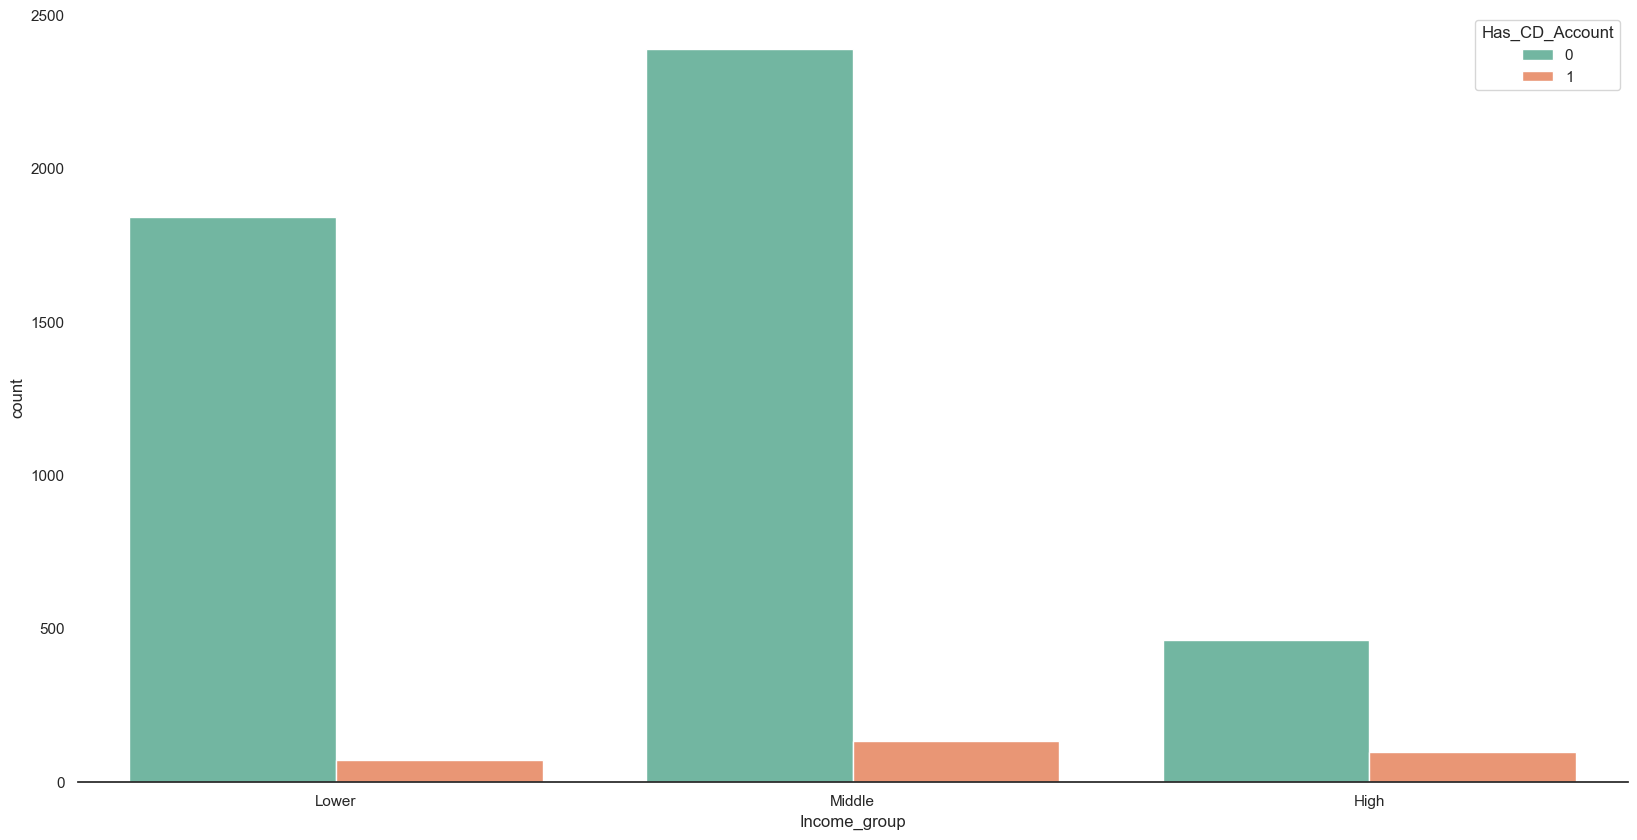

In [53]:
sns.countplot(x='Income_group',hue='Has_CD_Account',data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph

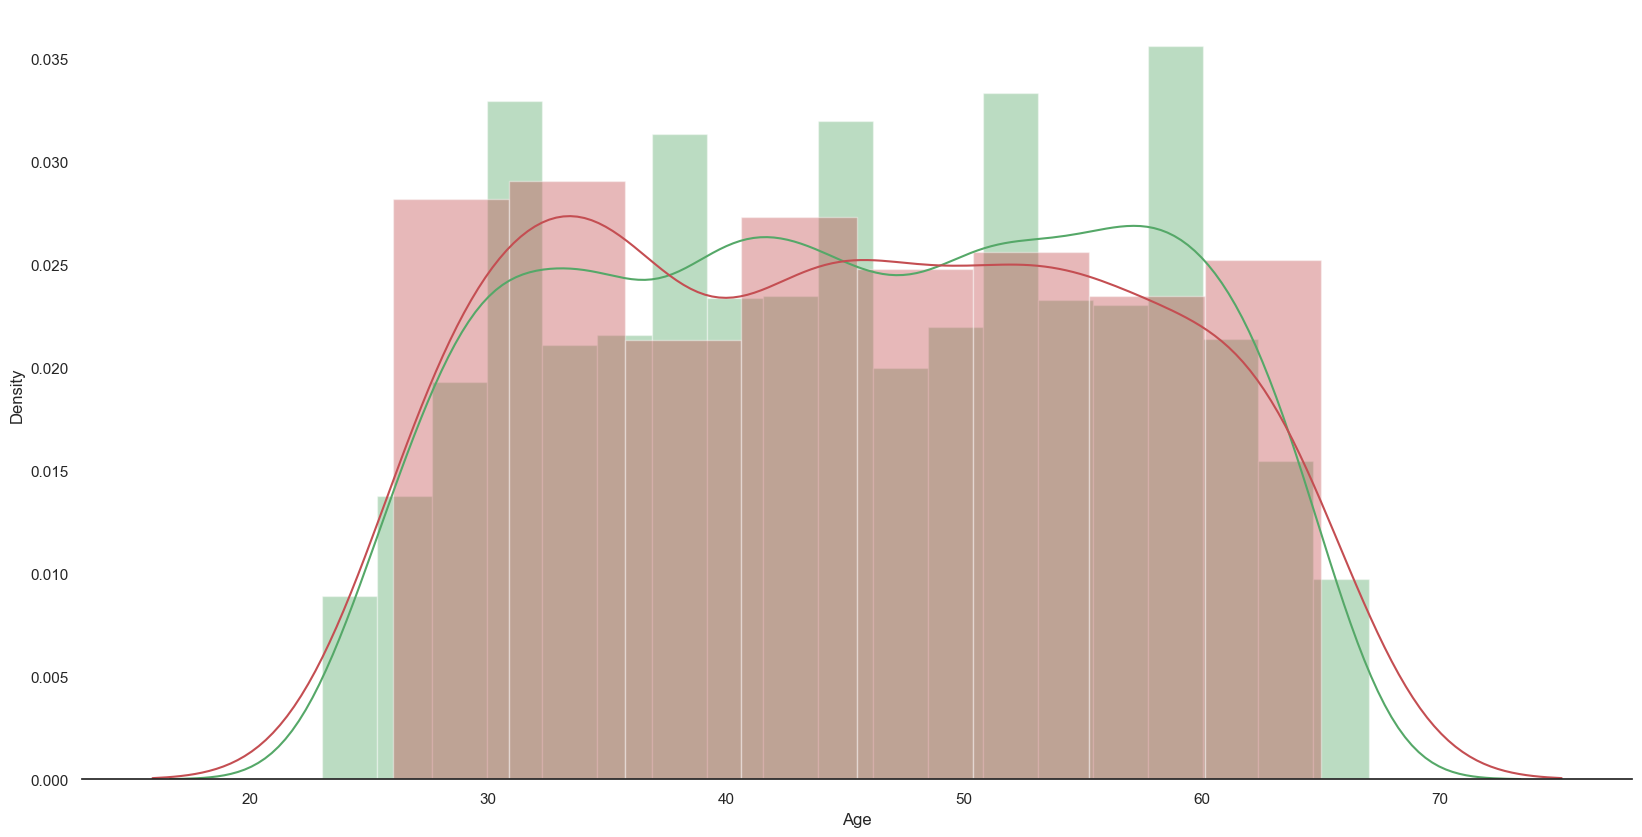

In [54]:
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 0]['Age'], color = 'g')
sns.distplot( df_loan[df_loan['Has_Consumer_Loan'] == 1]['Age'], color = 'r')
sns.despine(top=True,right=True,left=True) # to remove side line from graph

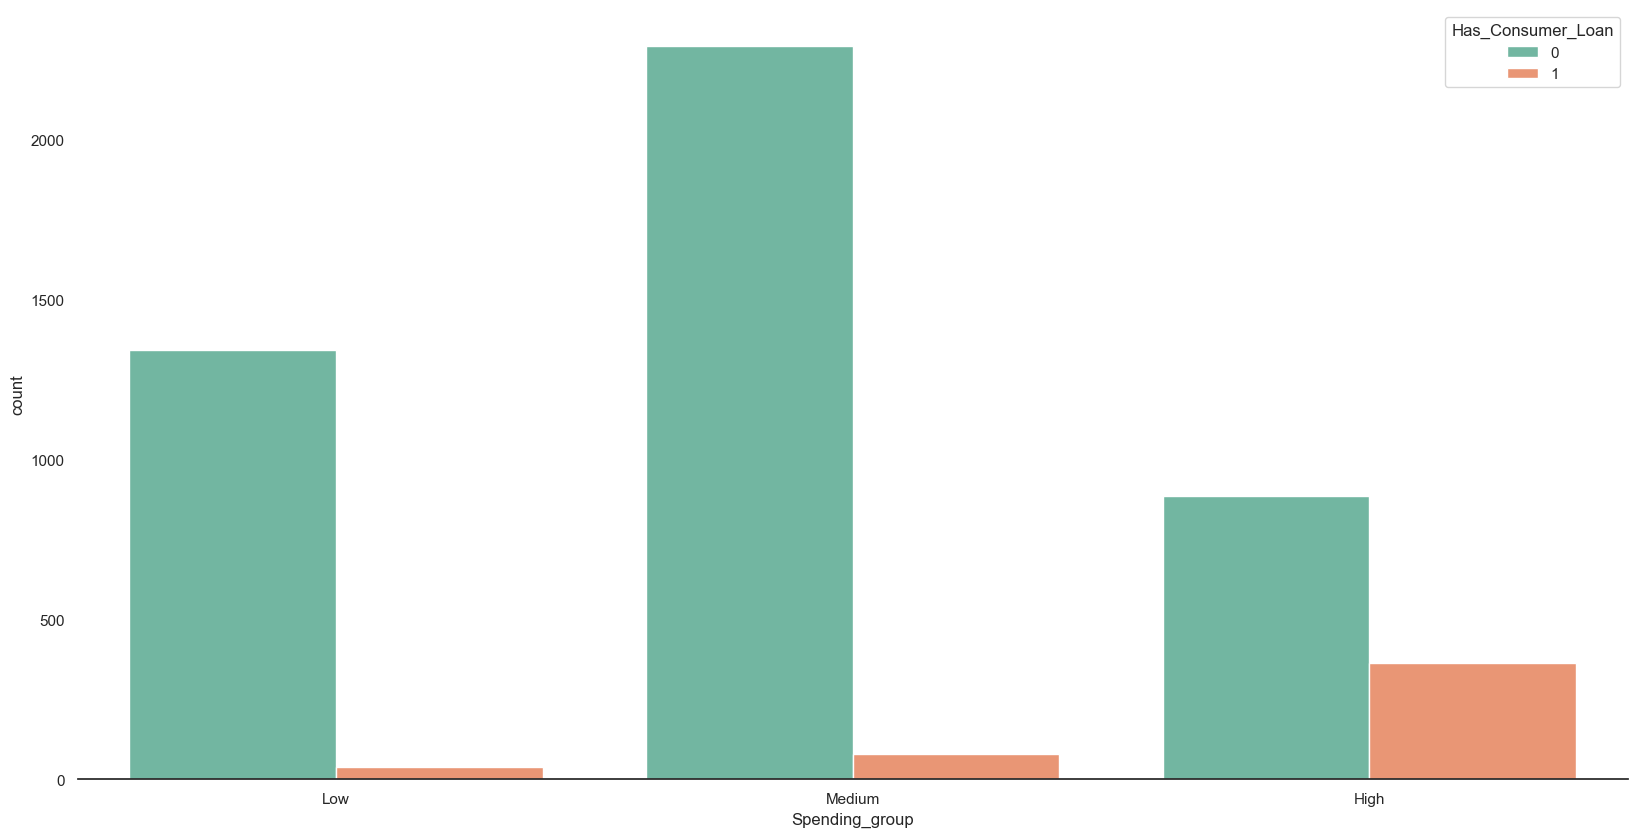

In [55]:
sns.countplot(x='Spending_group',hue='Has_Consumer_Loan',data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph

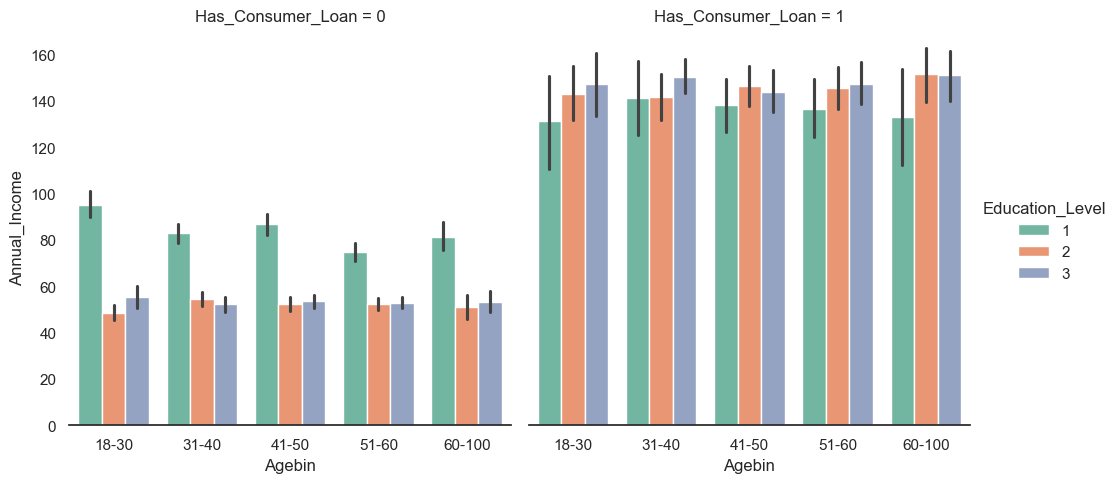

In [56]:
sns.catplot(y='Annual_Income',x='Agebin',hue='Education_Level',kind='bar',col="Has_Consumer_Loan", data=df_loan)
sns.despine(top=True,right=True,left=True) # to remove side line from graph

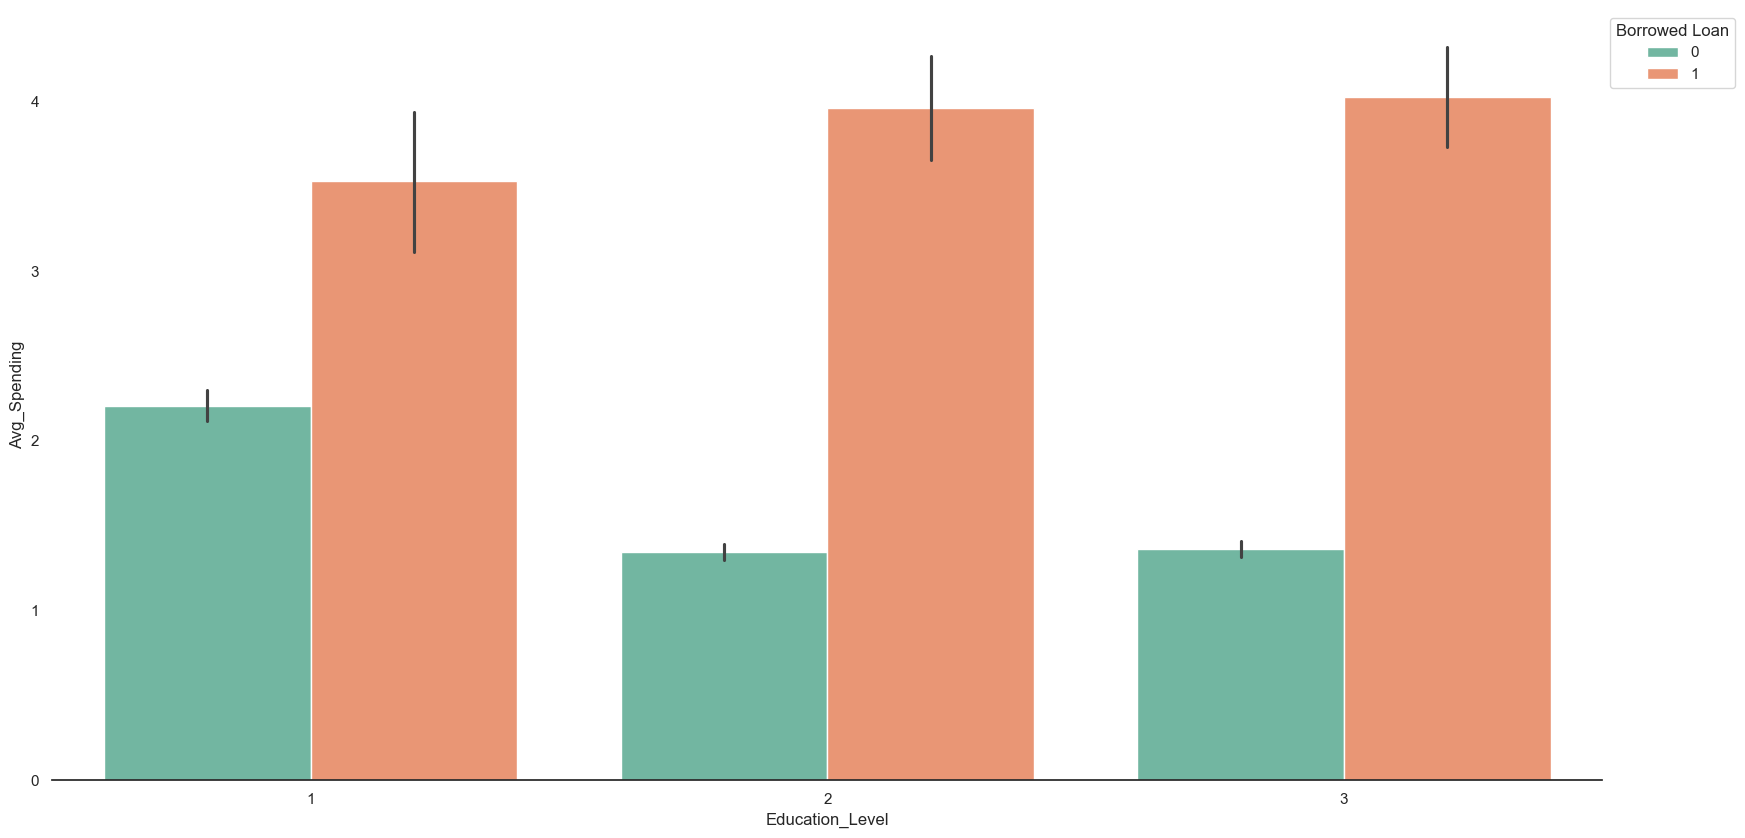

In [57]:
sns.set_palette(sns.color_palette("Set2", 8))
sns.barplot(y='Avg_Spending',x='Education_Level', hue='Has_Consumer_Loan',data=df_loan)
labels=["No","Yes"]
plt.legend(loc="upper left", title="Borrowed Loan",bbox_to_anchor=(1,1))
sns.despine(top=True,right=True,left=True) # to remove side line from graph

### Observations

    People with higher Annual_Income had opted for personal loan before.

    People with high mortgages opted for loan.

    Customers with higher average monthly credit usage have opted for loan.

    Customers with higher Annual_Income had higher average credit card usage and mortgage.

    Graduate and Advanced/Professional have higher monhtly credit card usage and have borrowed loans with the bank.

In [58]:
## Function to plot stacked bar chart
def stacked_plot(x):
    sns.set_palette(sns.color_palette("Set2", 8))
    tab1 = pd.crosstab(x,df_loan['Has_Consumer_Loan'],margins=True)
    print(tab1)
    print('-'*120)
    tab = pd.crosstab(x,df_loan['Has_Consumer_Loan'],normalize='index')
    tab.plot(kind='bar',stacked=True,figsize=(7,4))
    plt.xticks(rotation=360)
    labels=["No","Yes"]
    plt.legend(loc='lower left', frameon=False,)
    plt.legend(loc="upper left", labels=labels,title="Borrowed Loan",bbox_to_anchor=(1,1))
    sns.despine(top=True,right=True,left=True) # to remove side line from graph
    #plt.legend(labels)
    plt.show()

Has_Consumer_Loan     0    1   All
Family_size                       
1                  1365  107  1472
2                  1190  106  1296
3                   877  133  1010
4                  1087  134  1221
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


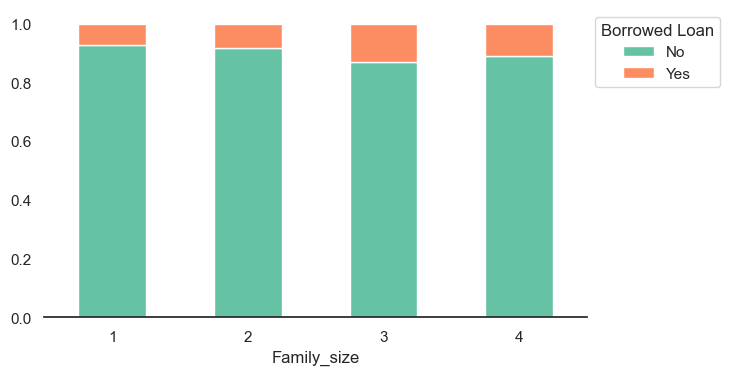

Has_Consumer_Loan     0    1   All
Education_Level                   
1                  2003   93  2096
2                  1221  182  1403
3                  1295  205  1500
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


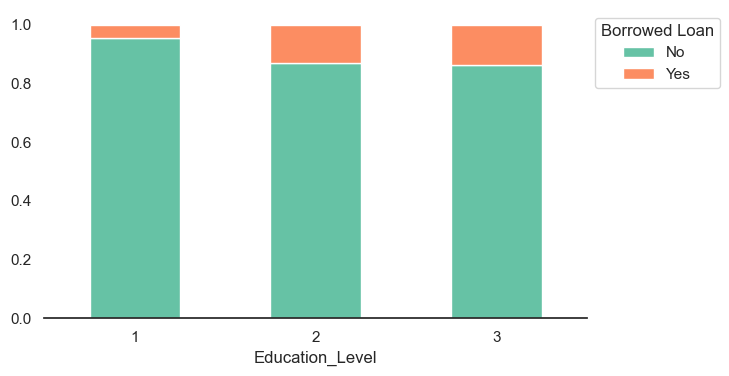

Has_Consumer_Loan          0    1   All
Has_Securities_Account                 
0                       4057  420  4477
1                        462   60   522
All                     4519  480  4999
------------------------------------------------------------------------------------------------------------------------


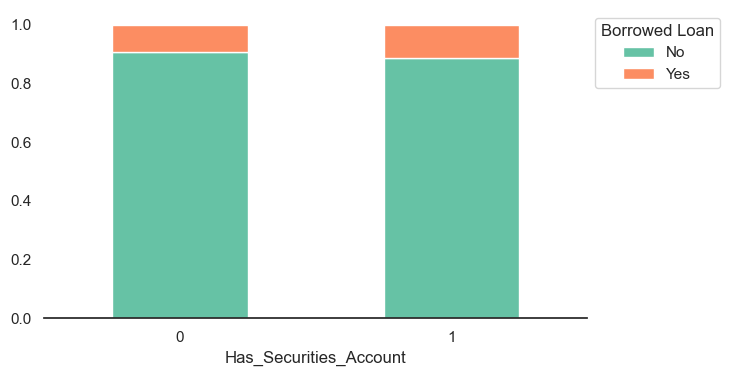

Has_Consumer_Loan     0    1   All
Has_CD_Account                    
0                  4357  340  4697
1                   162  140   302
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


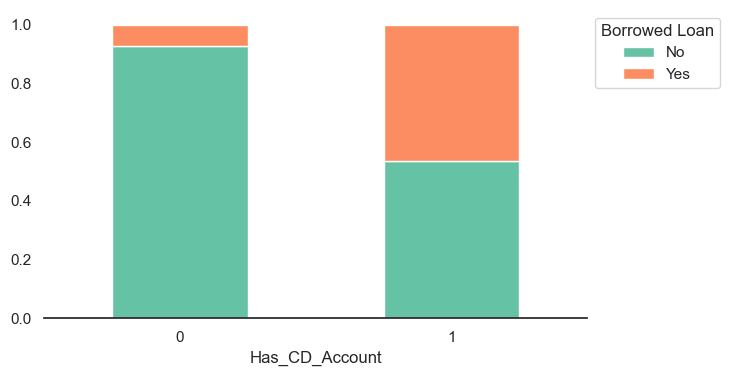

Has_Consumer_Loan     0    1   All
Has_CreditCard                    
0                  3193  337  3530
1                  1326  143  1469
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


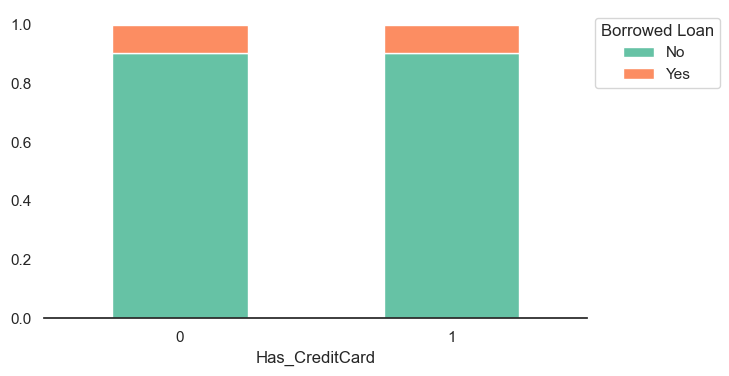

Has_Consumer_Loan       0    1   All
Uses_Online_Banking                 
0                    1827  189  2016
1                    2692  291  2983
All                  4519  480  4999
------------------------------------------------------------------------------------------------------------------------


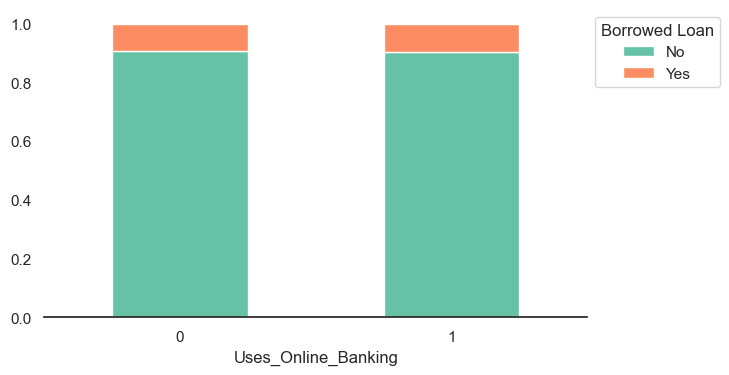

Has_Consumer_Loan      0    1   All
Regions                            
Bay Area            1747  196  1943
Central              390   30   420
Los Angeles Region   984  111  1095
Southern            1314  135  1449
Superior              84    8    92
All                 4519  480  4999
------------------------------------------------------------------------------------------------------------------------


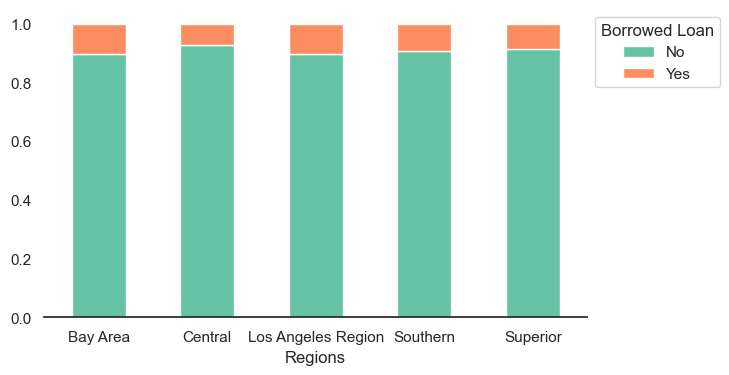

Has_Consumer_Loan     0    1   All
Agebin                            
18-30               558   66   624
31-40              1118  118  1236
41-50              1148  122  1270
51-60              1207  115  1322
60-100              488   59   547
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


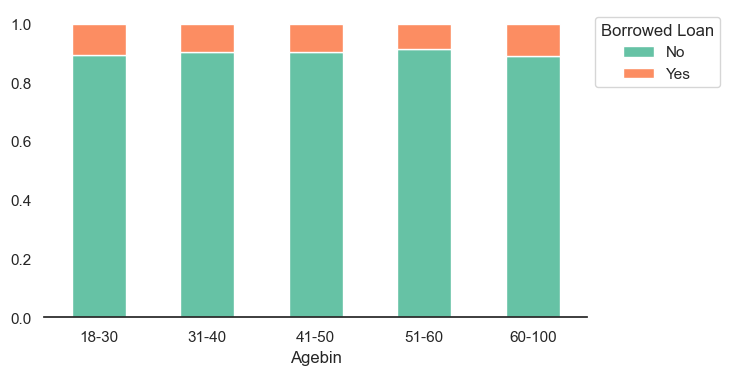

Has_Consumer_Loan     0    1   All
Income_group                      
Lower              1913    0  1913
Middle             2301  223  2524
High                305  257   562
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


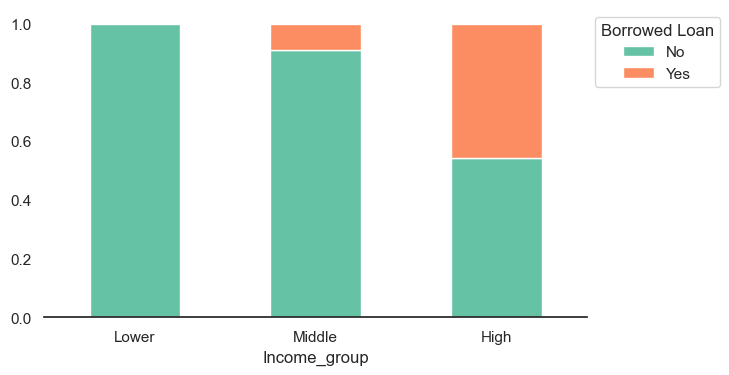

Has_Consumer_Loan     0    1   All
Spending_group                    
Low                1341   39  1380
Medium             2292   79  2371
High                886  362  1248
All                4519  480  4999
------------------------------------------------------------------------------------------------------------------------


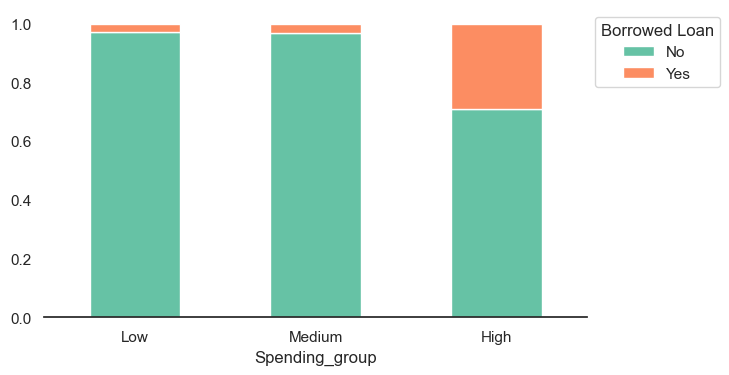

In [59]:
cat_columns=['Family_size','Education_Level','Has_Securities_Account','Has_CD_Account','Has_CreditCard','Uses_Online_Banking','Regions','Agebin','Income_group','Spending_group']
for i, variable in enumerate(cat_columns):
       stacked_plot(df_loan[variable])

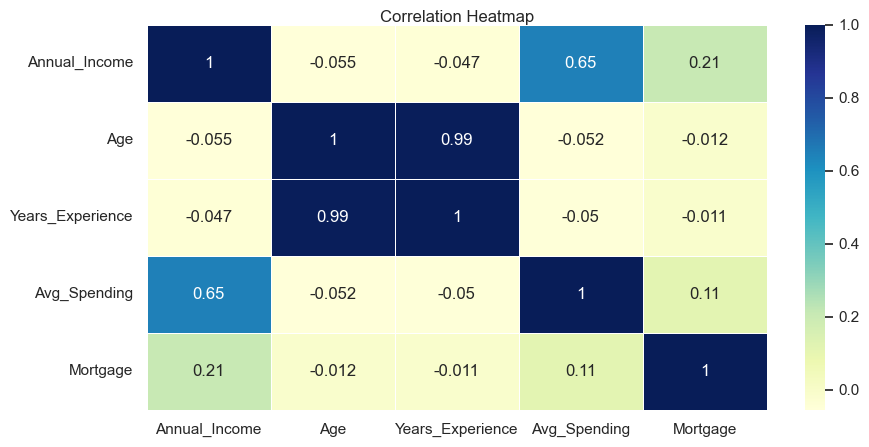

In [60]:
plt.figure(figsize=(10,5))
numerical=['Annual_Income','Age','Years_Experience','Avg_Spending','Mortgage']

# A better color to see the positive or negative correlation of each variable
heatmap = sns.heatmap(df_loan[numerical].corr(), annot=True, cmap='YlGnBu',linewidths=0.5)
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':12}, pad=2);

Check distrubution in target column

([<matplotlib.patches.Wedge at 0x18a01d2b710>,
 [Text(-1.0503312798154913, 0.3268091226406516, ''),
  Text(1.0503312721659712, -0.3268091472254298, '')],
 [Text(-0.5729079708084497, 0.1782595214403554, '90.4%'),
  Text(0.5729079666359843, -0.1782595348502344, '9.6%')])

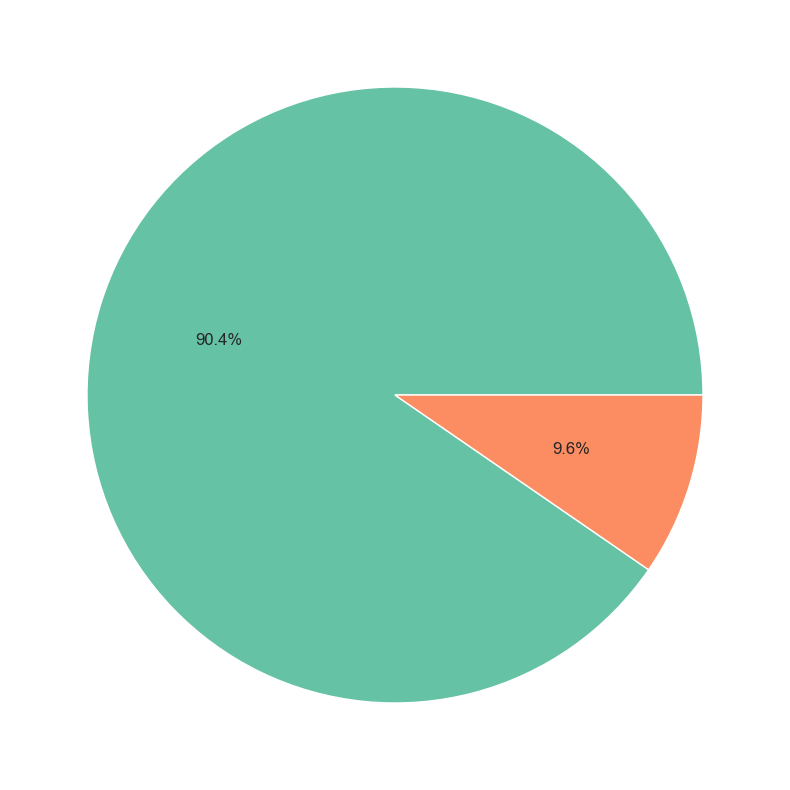

In [61]:
plt.pie(data=df_loan,x=df_loan["Has_Consumer_Loan"].value_counts(),autopct='%1.1f%%')

The target variable Has_Consumer_Loan is highly imbalanced where only 9.6% of the customers have previously opted for a personal loan in the dataset. This can be handled using weight or SMOTE.But for now we will carry on without SMOTE

In [62]:
df_loan.head()

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
0,25,1,49,91107,4,1.60000,1,0,0,1,0,0,0,Los Angeles County,18-30,Lower,Medium,Los Angeles Region
1,45,19,34,90089,3,1.50000,1,0,0,1,0,0,0,Los Angeles County,41-50,Lower,Medium,Los Angeles Region
2,39,15,11,94720,1,1.00000,1,0,0,0,0,0,0,Alameda County,31-40,Lower,Medium,Bay Area
3,35,9,100,94112,1,2.70000,2,0,0,0,0,0,0,San Francisco County,31-40,Middle,High,Bay Area
4,35,8,45,91330,4,1.00000,2,0,0,0,0,0,1,Los Angeles County,31-40,Lower,Medium,Los Angeles Region


In [63]:
# Saving dataset before treating outliers for logistic regression.
df_Decision = df_loan.copy()

#### 4.1 Insights based on EDA
Summary of EDA                   

Data Description:

    Dependent variable is the Personal_loan which is of categorical data type.
    Age, Years_Experience, Annual_Income,mortage ,Avg_Spending are of integer type while other variables are of categorical type
    There were no missing values in the dataset.

Data Cleaning:

    We observed that some observations where Years_Experience = -ve but since there was a strong correlation with age , we dropped Years_Experience.
    There are 450 unique zipcode, we mapped it to counties. They were further mapped to regions to reduce the dimension of data and we now have only 5 distinct values in the data.
    We also created Age bin ,Spending group and Incomegroup to analyse in there is any pattern in buying loan based on these.

Observations from EDA:

    People with higher Annual_Income had opted for personal loan before.
    People with high mortgages opted for loan.
    Customers will higher average monthly credit usage have opted for loan.
    Customers with Family of 3 members had borrowed the loans with the bank.
    Education level 2: Graduate and 3: Advanced/Professional have borrowed loans with the bank.
    Customers who had certificate of deposit with the bank had previously borrowed loan
    Majority of customers who did have Personal loan with the bank used Online facilities.
    Majority customers who had take personal loan before are from LosAngeles region.
    Ratio of borrowing loan is high in 30 and below and 60 and above customers.
    The more Annual_Income you get the more you spend and have a "large than life" lifestyle.

Customer segmentation for borrowing loan based on EDA

    Customer with Higher Annual_Income have higher mortages and higher monthly average spending.They also have certificate of deposit with the bank.They are our high profile clients.
    Few Customer in medium Annual_Income group don't have higher mortages and have less average monthly credit card spending .They are average profile clients.
    Customer in lower Annual_Income group have less mortages( few outliers are there) ,less monthly spending. They are our low profile clients.

Actions for data pre-processing:

    Many variables have outliers that need to be treated.
    We can drop Years_Experience, Country,Zipcode and Agebin,Income_group,Spending_group.



#### 4.2 Outliers detection

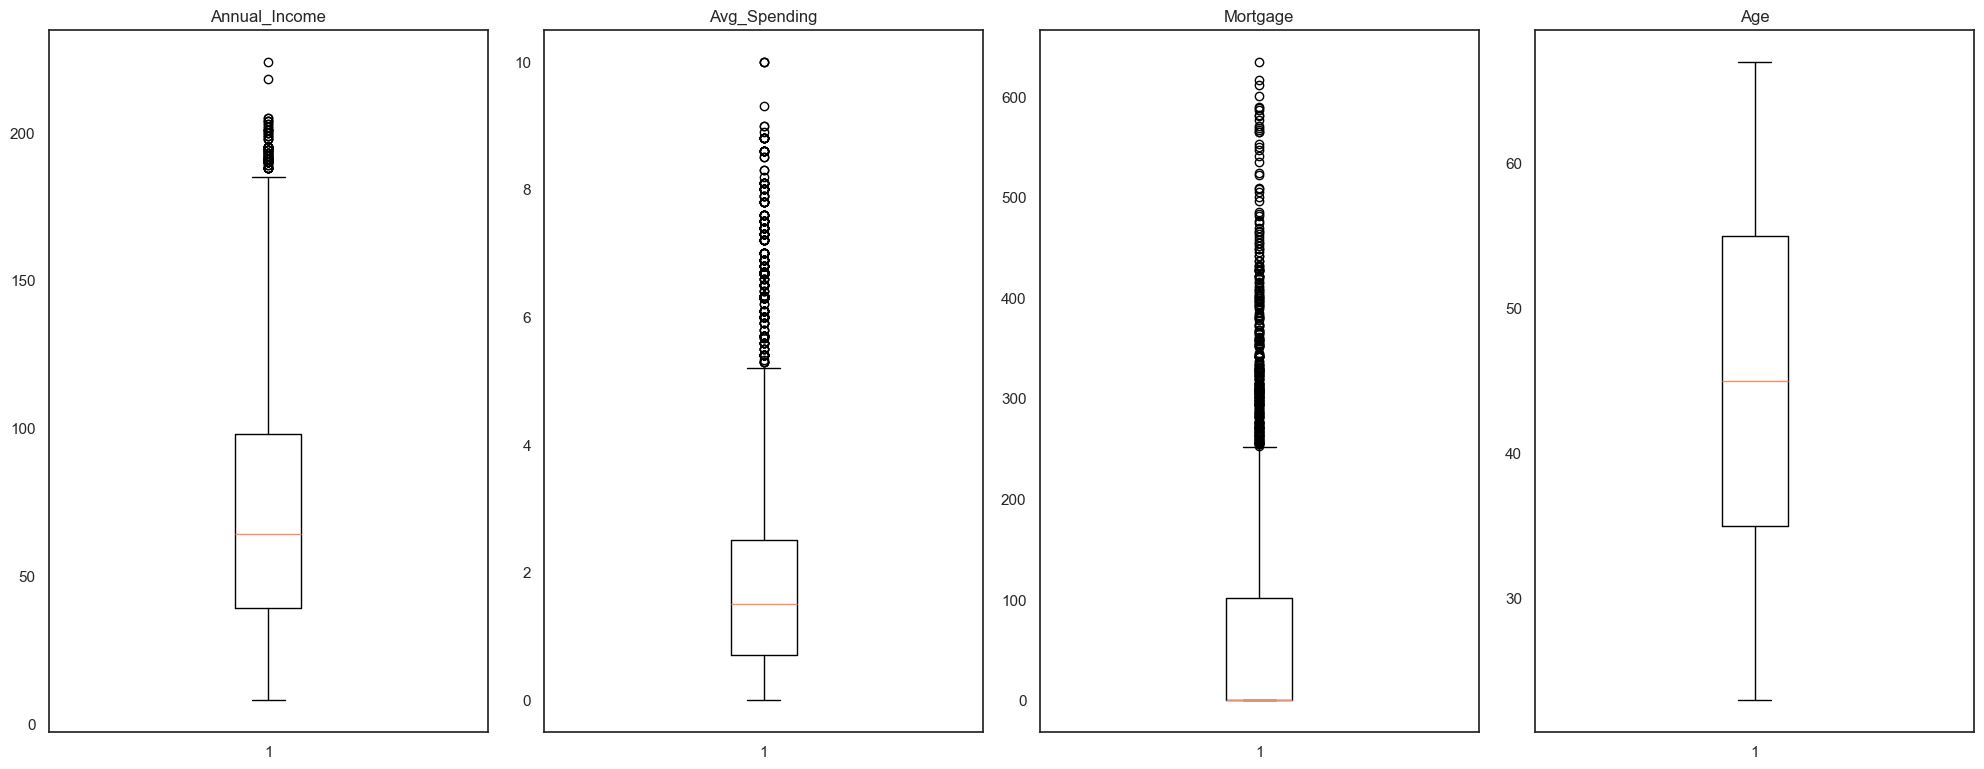

In [64]:
numeric_columns =['Annual_Income','Avg_Spending','Mortgage','Age']
# outlier detection using boxplot
plt.figure(figsize=(20,30))

for i, variable in enumerate(numeric_columns):
                     plt.subplot(4,4,i+1)
                     plt.boxplot(df_loan[variable],whis=1.5)
                     plt.tight_layout()
                     plt.title(variable)

plt.show()

In [65]:
# Check Annual_Income extreme values
df_loan.sort_values(by=["Annual_Income"],ascending = False).head(5)

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
3896,48,24,224,93940,2,6.67000,1,0,0,0,1,1,1,Monterey County,41-50,High,High,Bay Area
4993,45,21,218,91801,2,6.67000,1,0,0,0,0,1,0,Los Angeles County,41-50,High,High,Los Angeles Region
526,26,2,205,93106,1,6.33000,1,271,0,0,0,0,1,Santa Barbara County,18-30,High,High,Southern
2988,46,21,205,95762,2,8.80000,1,181,0,1,0,1,0,El Dorado County,41-50,High,High,Central
677,46,21,204,92780,2,2.80000,1,0,0,0,0,1,0,Orange County,41-50,High,High,Southern


In [66]:
df_loan.loc[(df_loan['Age']==48) & (df_loan['Years_Experience']==24)].sort_values(by=['Annual_Income'],ascending=False).head(5)

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
3896,48,24,224,93940,2,6.67000,1,0,0,0,1,1,1,Monterey County,41-50,High,High,Bay Area
196,48,24,165,93407,1,5.00000,1,0,0,0,0,0,1,San Luis Obispo County,41-50,High,High,Southern
2217,48,24,162,91355,4,3.30000,2,446,1,0,1,1,0,Los Angeles County,41-50,High,High,Los Angeles Region
4629,48,24,148,91311,2,3.30000,1,0,0,0,1,1,1,Los Angeles County,41-50,High,High,Los Angeles Region
4167,48,24,144,94025,4,3.50000,2,0,1,0,0,0,0,San Mateo County,41-50,High,High,Bay Area


In [67]:
# Check Mortgage extreme values
df_loan.sort_values(by=["Mortgage"],ascending = False).head(5)

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
2934,37,13,195,91763,2,6.50000,1,635,0,0,0,1,0,San Bernardino County,31-40,High,High,Southern
303,49,25,195,95605,4,3.00000,1,617,1,0,0,0,0,Yolo County,41-50,High,High,Central
4812,29,4,184,92126,4,2.20000,3,612,1,0,0,1,0,San Diego County,18-30,High,Medium,Southern
1783,53,27,192,94720,1,1.70000,1,601,0,0,0,1,0,Alameda County,51-60,High,Medium,Bay Area
4842,49,23,174,95449,3,4.60000,2,590,1,0,0,0,0,Mendocino County,41-50,High,High,Superior


In [68]:
# Check Avg_Spending extreme values
df_loan.sort_values(by=["Avg_Spending"],ascending = False).head(5)

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
2101,35,5,203,95032,1,10.00000,3,0,1,0,0,0,0,Santa Clara County,31-40,High,High,Bay Area
2337,43,16,201,95054,1,10.00000,2,0,1,0,0,0,1,Santa Clara County,41-50,High,High,Bay Area
787,45,15,202,91380,3,10.00000,3,0,1,0,0,0,0,Los Angeles County,41-50,High,High,Los Angeles Region
3943,61,36,188,91360,1,9.30000,2,0,1,0,0,0,0,Ventura County,60-100,High,High,Southern
1339,52,25,180,94545,2,9.00000,2,297,1,0,0,1,0,Alameda County,51-60,High,High,Bay Area


This is some really extreme values in Annual_Income 224K USD compared to same age group and Years_Experience. Values for Credit card and Mortages looks fine.After identifying outliers, we can decide whether to remove/treat them or not. It depends,here I am not going to treat them as there will be outliers in real case scenario (in Annual_Income, Mortgage value, Average spending on the credit card, etc) and we would want our model to learn the underlying pattern for such customers.

In [69]:
df_loan

,Age,Years_Experience,Annual_Income,ZIP_Code,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,County,Agebin,Income_group,Spending_group,Regions
0,25,1,49,91107,4,1.60000,1,0,0,1,0,0,0,Los Angeles County,18-30,Lower,Medium,Los Angeles Region
1,45,19,34,90089,3,1.50000,1,0,0,1,0,0,0,Los Angeles County,41-50,Lower,Medium,Los Angeles Region
2,39,15,11,94720,1,1.00000,1,0,0,0,0,0,0,Alameda County,31-40,Lower,Medium,Bay Area
3,35,9,100,94112,1,2.70000,2,0,0,0,0,0,0,San Francisco County,31-40,Middle,High,Bay Area
4,35,8,45,91330,4,1.00000,2,0,0,0,0,0,1,Los Angeles County,31-40,Lower,Medium,Los Angeles Region
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,29,3,40,92697,1,1.90000,3,0,0,0,0,1,0,Orange County,18-30,Lower,Medium,Southern
4996,30,4,15,92037,4,0.40000,1,85,0,0,0,1,0,San Diego County,18-30,Lower,Low,Southern
4997,63,39,24,93023,2,0.30000,3,0,0,0,0,0,0,Ventura County,60-100,Lower,Low,Southern
4998,65,40,49,90034,3,0.50000,2,0,0,0,0,1,0,Los Angeles County,60-100,Lower,Low,Los Angeles Region


In [70]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Age                     4999 non-null   int64   
 1   Years_Experience        4999 non-null   int64   
 2   Annual_Income           4999 non-null   int64   
 3   ZIP_Code                4999 non-null   category
 4   Family_size             4999 non-null   category
 5   Avg_Spending            4999 non-null   float64 
 6   Education_Level         4999 non-null   category
 7   Mortgage                4999 non-null   int64   
 8   Has_Consumer_Loan       4999 non-null   category
 9   Has_Securities_Account  4999 non-null   category
 10  Has_CD_Account          4999 non-null   category
 11  Uses_Online_Banking     4999 non-null   category
 12  Has_CreditCard          4999 non-null   category
 13  County                  4999 non-null   category
 14  Agebin                  4999 

In [71]:
#drop column which we don't need for modelling
df_loan.drop(columns=["Agebin", "ZIP_Code","County",'Years_Experience','Income_group','Spending_group'], inplace=True)

In [72]:
df_loan.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4999 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Age                     4999 non-null   int64   
 1   Annual_Income           4999 non-null   int64   
 2   Family_size             4999 non-null   category
 3   Avg_Spending            4999 non-null   float64 
 4   Education_Level         4999 non-null   category
 5   Mortgage                4999 non-null   int64   
 6   Has_Consumer_Loan       4999 non-null   category
 7   Has_Securities_Account  4999 non-null   category
 8   Has_CD_Account          4999 non-null   category
 9   Uses_Online_Banking     4999 non-null   category
 10  Has_CreditCard          4999 non-null   category
 11  Regions                 4999 non-null   object  
dtypes: category(7), float64(1), int64(3), object(1)
memory usage: 269.4+ KB



We have 6 categorical independent variables but 4 of them are binary, so we'll have the same results with them even after creating dummies So we will only make dummies for Regions and Education.


In [73]:
X = df_loan.drop(['Has_Consumer_Loan'], axis=1)
Y = df_loan['Has_Consumer_Loan']

oneHotCols=['Regions','Education_Level']
X=pd.get_dummies(X,columns=oneHotCols,drop_first=True)

In [74]:
#Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.20, random_state = 1,stratify=Y)

In [75]:
from sklearn.preprocessing import StandardScaler
# Creating StandardScaler instance
scaler = StandardScaler()

# Fitting Standard Scaller
X_scaler = scaler.fit(X_train)

# Scaling data
X_train_scaled = X_scaler.transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled,columns=X_test.columns)


X_train_scaled_df.index=np.arange(len(X_train_scaled_df))
X_test_scaled_df.index=np.arange(len(X_test_scaled_df))
y_train.index=np.arange(len(y_train))
y_test.index=np.arange(len(y_test))

## 5. Model building

### 5.1 Logistic Regression 

In [76]:
LRclassifier = LogisticRegression(solver='saga', max_iter=500, random_state=1)
LRclassifier.fit(X_train, y_train)

y_pred = LRclassifier.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import accuracy_score
LRAcc = accuracy_score(y_pred,y_test)
print('LR accuracy: {:.2f}%'.format(LRAcc*100))

              precision    recall  f1-score   support

           0       0.92      0.97      0.94       904
           1       0.43      0.21      0.28        96

    accuracy                           0.90      1000
   macro avg       0.67      0.59      0.61      1000
weighted avg       0.87      0.90      0.88      1000

[[877  27]
 [ 76  20]]
LR accuracy: 89.70%


### 5.2 Decision Tree  


Model building Decision Tree

    Data preparation
    Partition the data into train and test set.
    Built a CART model on the train data.
    Tune the model and prune the tree, if required.
    Test the data on test set.



In [77]:
#drop column which we don't need for modelling
df_Decision.drop(columns=["Agebin", "ZIP_Code","County",'Years_Experience','Income_group','Spending_group'], inplace=True)

In [78]:
X_dt = df_Decision.drop('Has_Consumer_Loan', axis=1)
y_dt = df_Decision['Has_Consumer_Loan']

In [79]:
def make_confusion_matrix(y_actual,y_predict,title):
    fig, ax = plt.subplots(1, 1)
    
    cm = confusion_matrix(y_actual, y_predict, labels=[0,1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["No","Yes"])
    disp.plot(cmap='Greens',colorbar=True,ax=ax)
    ax.set_title(title)
    plt.tick_params(axis=u'both', which=u'both',length=0)
    plt.grid(axis='both',which='both',visible=False)
    plt.show()

In [80]:
#oneHotCols=['Regions']
oneHotCols=X_dt.select_dtypes(exclude='number').columns.to_list()
X_dt=pd.get_dummies(X_dt,columns=oneHotCols,drop_first=True)
# Spliting data set
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X_dt, y_dt, test_size=0.2, random_state=1, stratify=y_dt)


Build Model¶

    We are using 'gini' criteria to split.

    If the frequency of class A is 10% and the frequency of class B is 90%, then class B will become the dominant class and the decision tree will become biased toward the dominant classes.

    To handle this imbalanced data set,we can pass a dictionary {0:0.15,1:0.85} to the model to specify the weight of each class and the decision tree will give more weightage to class 1.

    class_weight is a hyperparameter for the decision tree classifier.
    Since not being able to identify a potential customer is the biggest loss as mentioned earlier with logistic regression. Hence, recall is the right metric to check the performance of the model.



In [81]:
##  Function to calculate recall score
def get_recall_score(model):
    '''
    model : classifier to predict values of X

    '''
    ytrain_predict = model.predict(X_train_dt)
    ytest_predict = model.predict(X_test_dt)
    # accuracy on training set
    print("\x1b[0;30;47m \033[1mAccuracy : Train :\033[0m", 
          model.score(X_train_dt,y_train_dt),
          "\x1b[0;30;47m \033[1mTest:\033[0m", 
          model.score(X_test_dt,y_test_dt))
# accuracy on training set
    print("\x1b[0;30;47m \033[1mRecall   : Train :\033[0m", 
          metrics.recall_score(y_train_dt,ytrain_predict),
          "\x1b[0;30;47m \033[1mTest:\033[0m", 
          metrics.recall_score(y_test_dt,ytest_predict))
    make_confusion_matrix(y_train_dt,ytrain_predict,"Confusion Matric on Train Data")
    make_confusion_matrix(y_test_dt,ytest_predict,"Confusion Matric on Test Data")

 Accuracy : Train : 1.0  Test: 0.983
 Recall   : Train : 1.0  Test: 0.8958333333333334


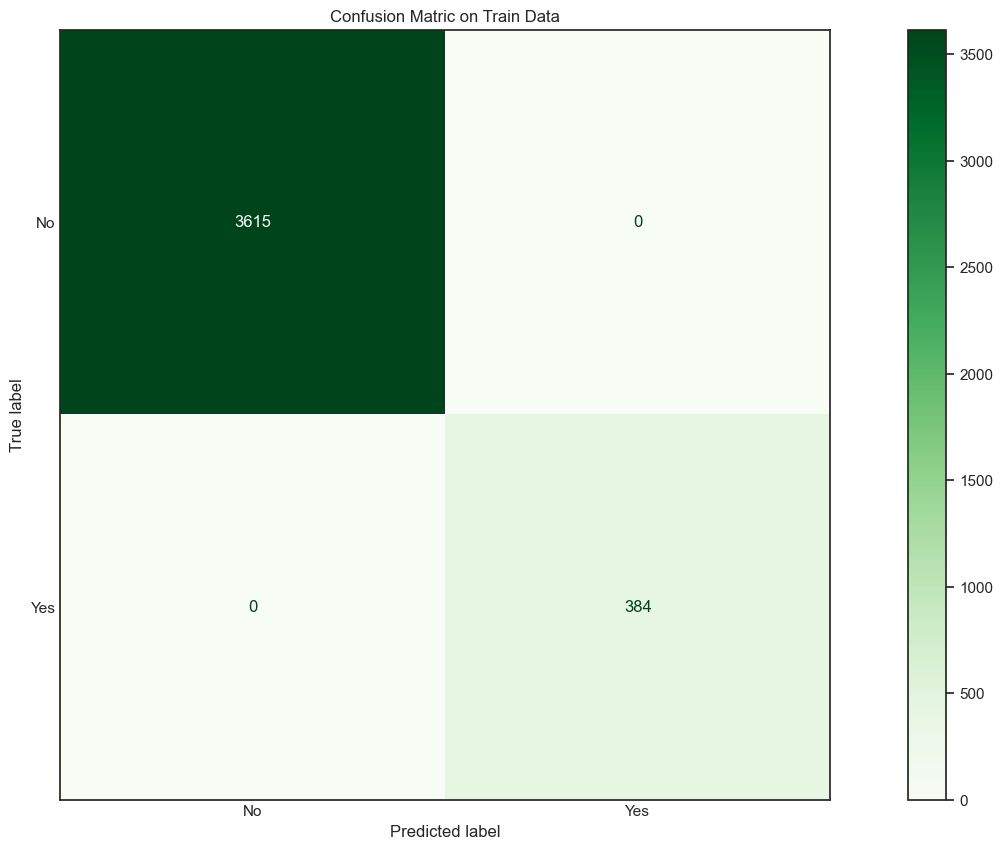

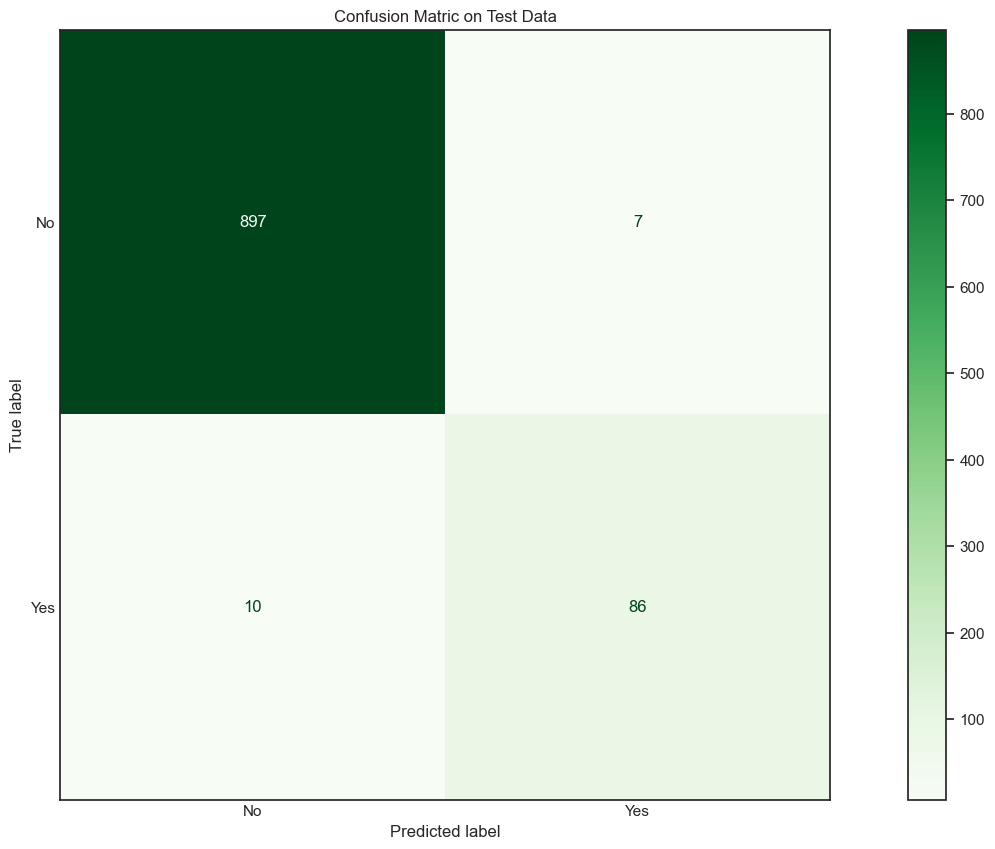

In [82]:
#since data is imbalanced adding weights
model = DecisionTreeClassifier(criterion = 'gini',class_weight={0:0.15,1:0.85}, random_state=1)
model.fit(X_train_dt, y_train_dt)
get_recall_score(model)

Visualizing the Decision Tree

In [83]:
column_names = list(X_dt.columns)
feature_names = column_names
print(feature_names)

['Age', 'Annual_Income', 'Avg_Spending', 'Mortgage', 'Family_size_2', 'Family_size_3', 'Family_size_4', 'Education_Level_2', 'Education_Level_3', 'Has_Securities_Account_1', 'Has_CD_Account_1', 'Uses_Online_Banking_1', 'Has_CreditCard_1', 'Regions_Central', 'Regions_Los Angeles Region', 'Regions_Southern', 'Regions_Superior']


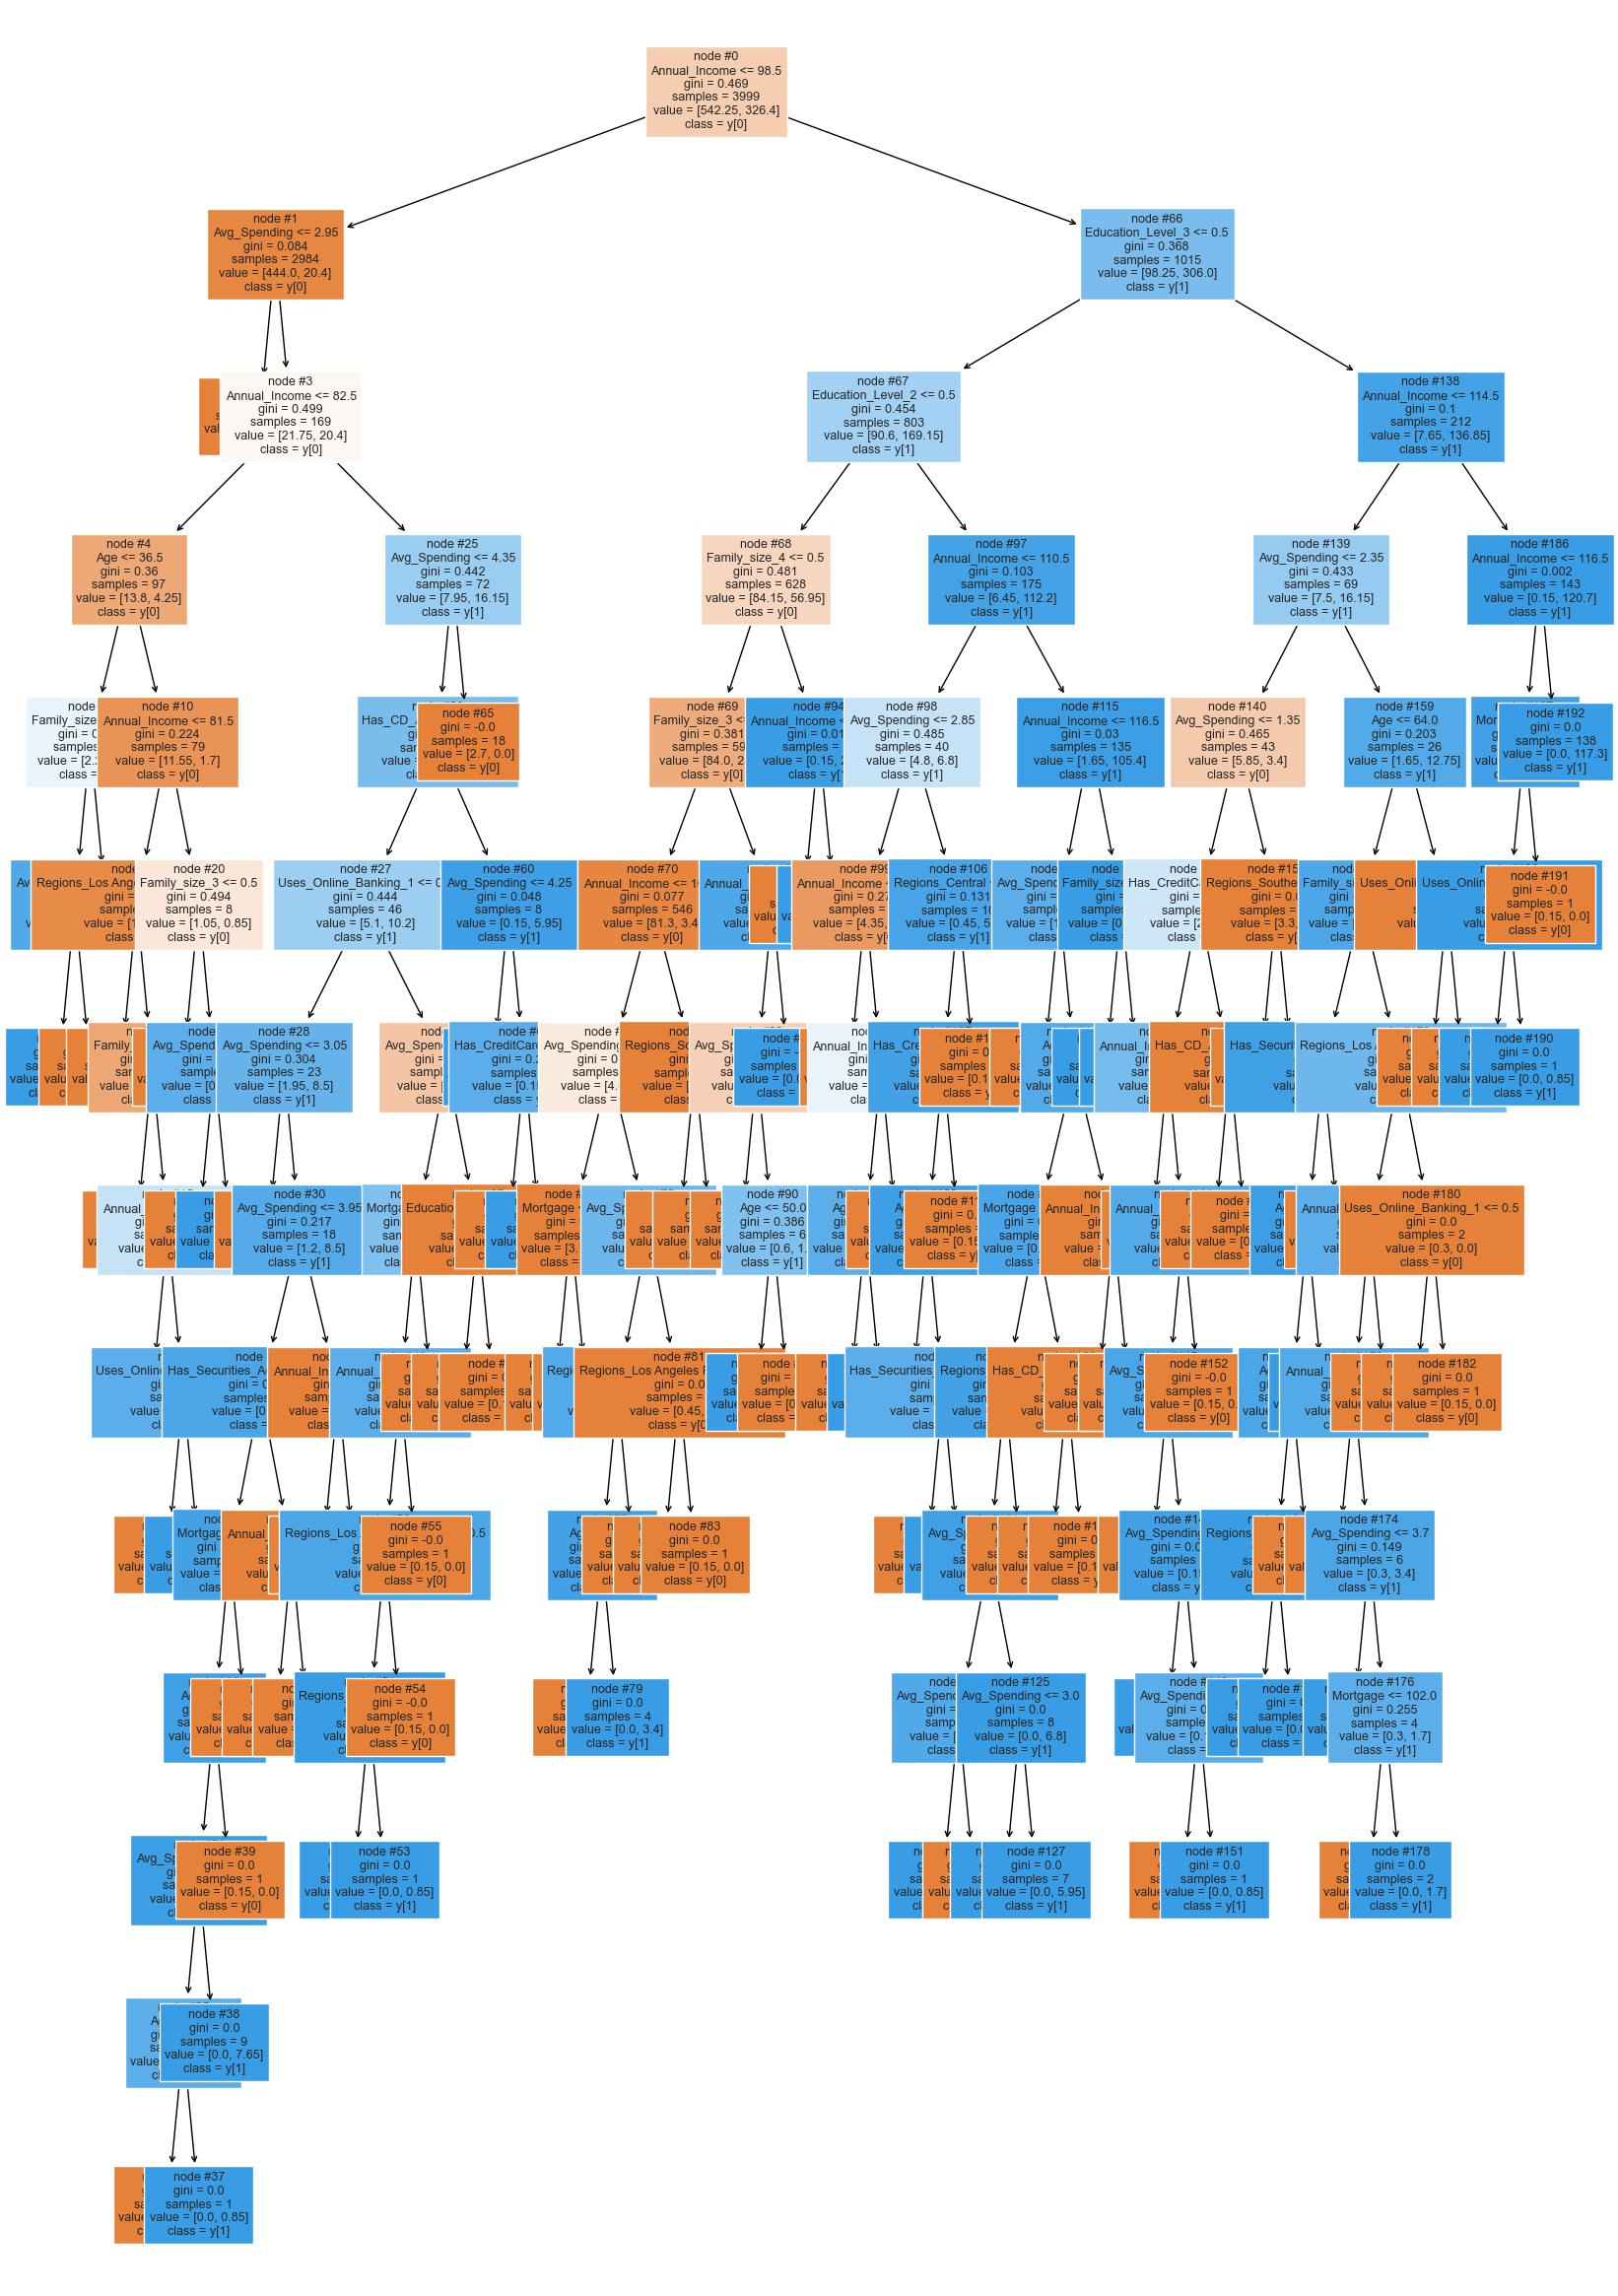

In [84]:
plt.figure(figsize=(20,30))
from sklearn import tree
from sklearn.model_selection import GridSearchCV
out = tree.plot_tree(model,feature_names=feature_names,filled=True,fontsize=9,node_ids=True,class_names=True)
for o in out:
     arrow = o.arrow_patch
     if arrow is not None:
        arrow.set_edgecolor('black')
        arrow.set_linewidth(1)
plt.show()

In [85]:
# Text report showing the rules of a decision tree -

print(tree.export_text(model,feature_names=feature_names,show_weights=True))

|--- Annual_Income <= 98.50
|   |--- Avg_Spending <= 2.95
|   |   |--- weights: [422.25, 0.00] class: 0
|   |--- Avg_Spending >  2.95
|   |   |--- Annual_Income <= 82.50
|   |   |   |--- Age <= 36.50
|   |   |   |   |--- Family_size_4 <= 0.50
|   |   |   |   |   |--- Avg_Spending <= 3.50
|   |   |   |   |   |   |--- weights: [0.00, 2.55] class: 1
|   |   |   |   |   |--- Avg_Spending >  3.50
|   |   |   |   |   |   |--- weights: [0.30, 0.00] class: 0
|   |   |   |   |--- Family_size_4 >  0.50
|   |   |   |   |   |--- weights: [1.95, 0.00] class: 0
|   |   |   |--- Age >  36.50
|   |   |   |   |--- Annual_Income <= 81.50
|   |   |   |   |   |--- Regions_Los Angeles Region <= 0.50
|   |   |   |   |   |   |--- weights: [7.65, 0.00] class: 0
|   |   |   |   |   |--- Regions_Los Angeles Region >  0.50
|   |   |   |   |   |   |--- Family_size_2 <= 0.50
|   |   |   |   |   |   |   |--- weights: [2.25, 0.00] class: 0
|   |   |   |   |   |   |--- Family_size_2 >  0.50
|   |   |   |   |   |   | 

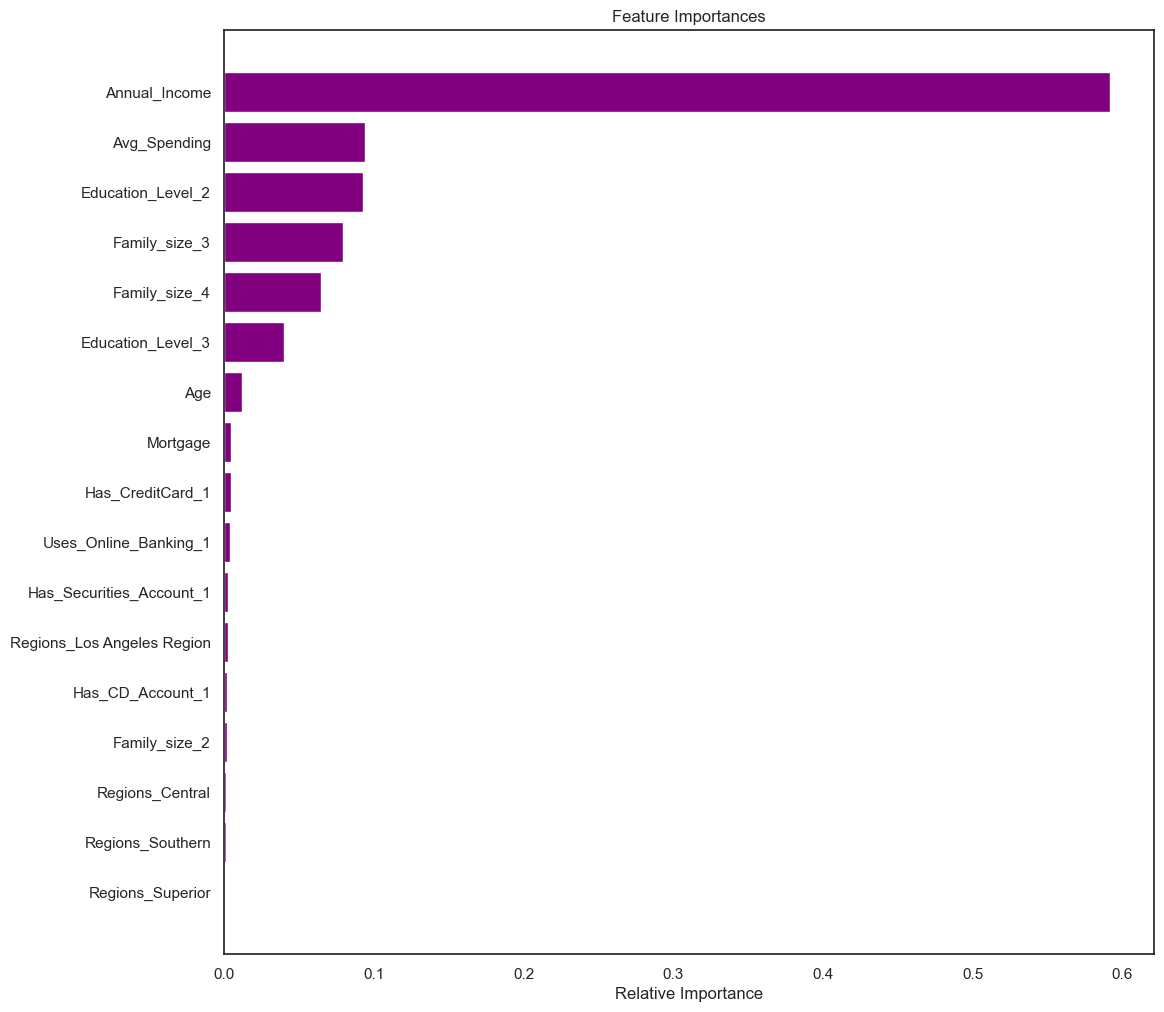

In [86]:
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='purple', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


Using GridSearch for Hyperparameter tuning of our tree model¶

    Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.
    It is an exhaustive search that is performed on a the specific parameter values of a model.
    The parameters of the estimator/model used to apply these methods are optimized by cross-validated grid-search over a parameter grid.
    Let's see if we can improve our model performance even more.



In [87]:
# Choose the type of classifier. 
estimator = DecisionTreeClassifier(random_state=1)

# Grid of parameters to choose from

parameters = {'max_depth': np.arange(1,10), 
              'min_samples_leaf': [1, 2, 5, 7, 10,15,20],
              'max_leaf_nodes' : [5, 10,15,20,25,30],
              }

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search
grid_obj = GridSearchCV(estimator, parameters, scoring=acc_scorer,cv=5)
grid_obj = grid_obj.fit(X_train_dt, y_train_dt)

# Set the clf to the best combination of parameters
estimator = grid_obj.best_estimator_
estimator

DecisionTreeClassifier(max_depth=8, max_leaf_nodes=25, min_samples_leaf=5,
                       random_state=1)

In [88]:
# Fit the best algorithm to the data. 
estimator.fit(X_train_dt, y_train_dt)
ytrain_predict=estimator.predict(X_train_dt)
ytest_predict=estimator.predict(X_test_dt)

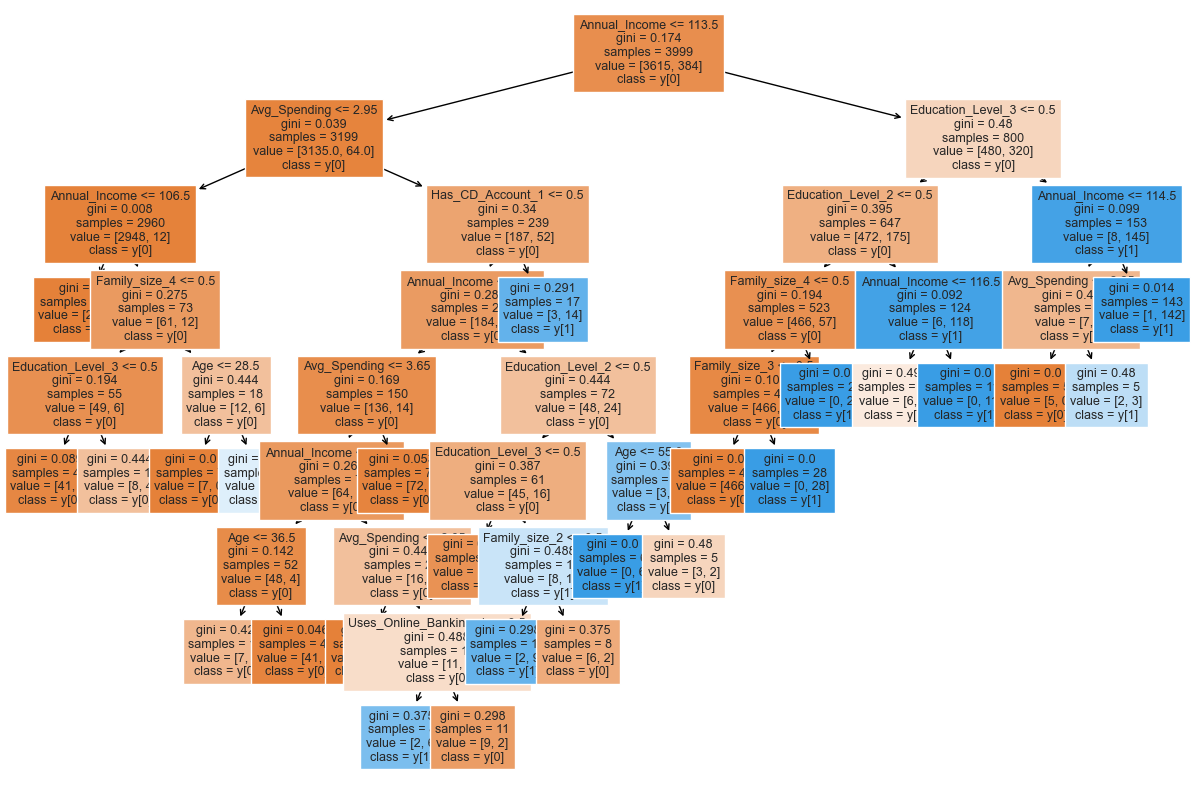

In [89]:
plt.figure(figsize=(15,10))

out = tree.plot_tree(estimator,feature_names=feature_names,filled=True,fontsize=9,node_ids=False,class_names=True)
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black')
        arrow.set_linewidth(1)
plt.show()

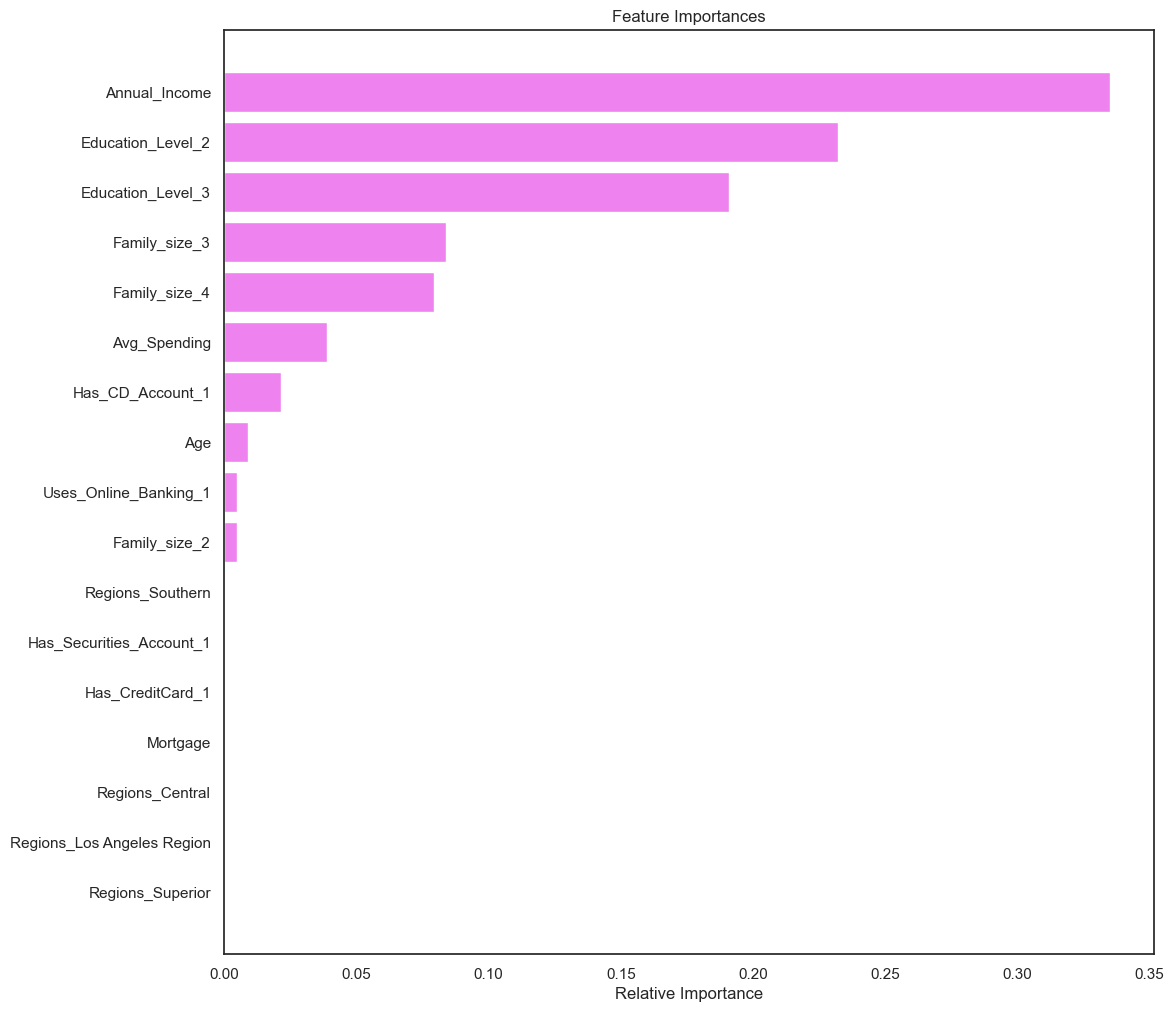

In [90]:
importances = estimator.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

 Accuracy : Train : 0.989247311827957  Test: 0.984
 Recall   : Train : 0.9270833333333334  Test: 0.90625


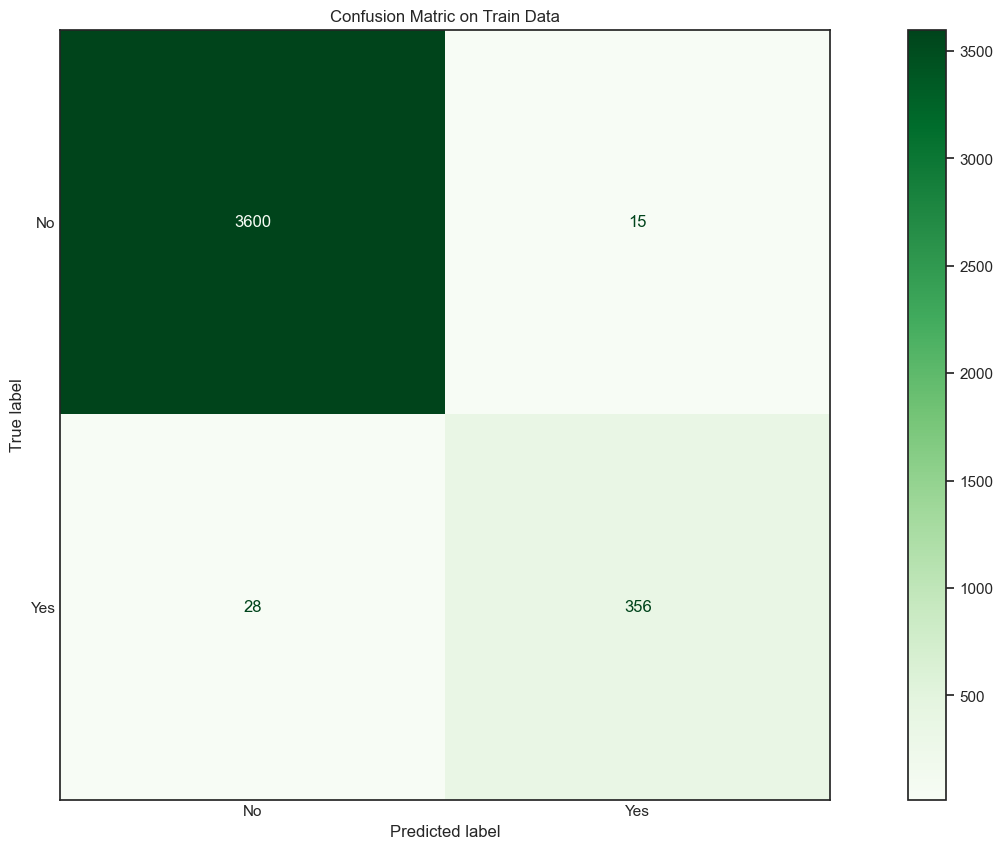

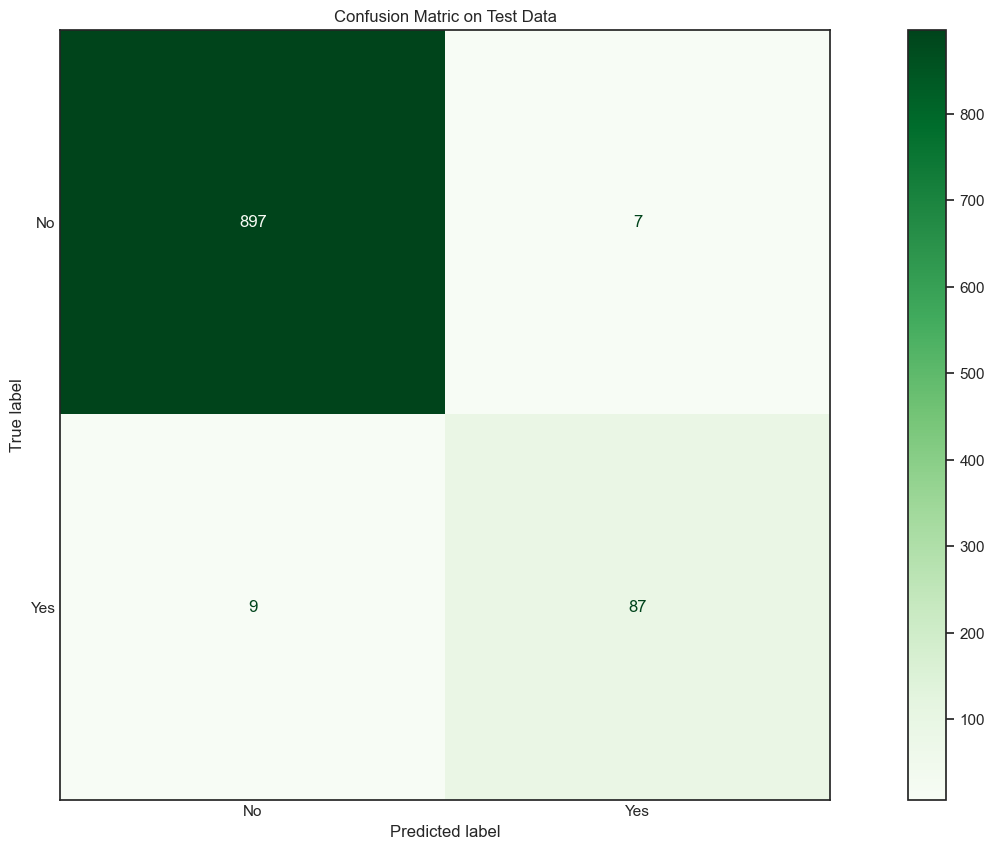

In [91]:


get_recall_score(estimator)





    With HyperParameter max_depth=6, max_leaf_nodes=20, min_samples_leaf=7 the overfitting on train has reduced, but the recall for test has not improved.
    Important features are Annual_Income,Education 2 and Education 3, Family 4, Family 3, Avg_Spending & Age.
    But the recall metric is still 91 and false negatives are 12.We don't want to loose opportunity in predicting this customers. so Let see if instead of pre pruning , post pruning helps in reducing false negative.



Cost Complexity Pruning

In [92]:
clf = DecisionTreeClassifier(random_state=1)
path = clf.cost_complexity_pruning_path(X_train_dt, y_train_dt)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

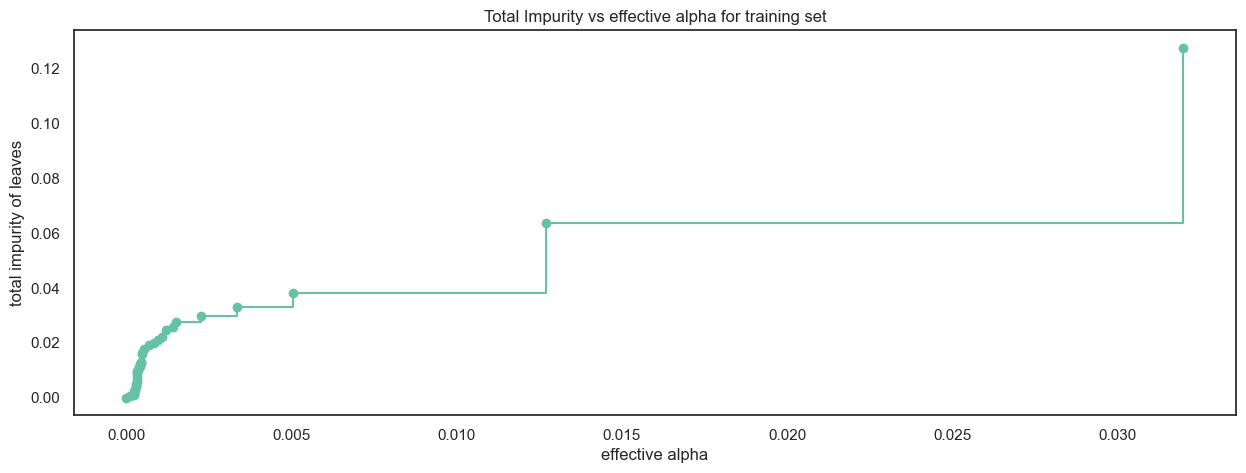

In [93]:
fig, ax = plt.subplots(figsize=(15,5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker='o', drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

Next, we train a decision tree using the effective alphas. We will set these values of alpha and pass it to the ccp_alpha parameter of our DecisionTreeClassifier. By looping over the alphas array, we will find the accuracy on both Train and Test parts of our dataset.

In [94]:
clfs = []
accuracy_train=[]
accuracy_test=[]
recall_train=[]
recall_test=[]
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=1, ccp_alpha=ccp_alpha,class_weight = {0:0.15,1:0.85})
    clf.fit(X_train_dt, y_train_dt)
    y_train_pred=clf.predict(X_train_dt)
    y_test_pred=clf.predict(X_test_dt)
    accuracy_train.append(clf.score(X_train_dt,y_train_dt))
    accuracy_test.append(clf.score(X_test_dt,y_test_dt))
    recall_train.append(metrics.recall_score(y_train_dt,y_train_pred))
    recall_test.append(metrics.recall_score(y_test_dt,y_test_pred))
    clfs.append(clf)
    

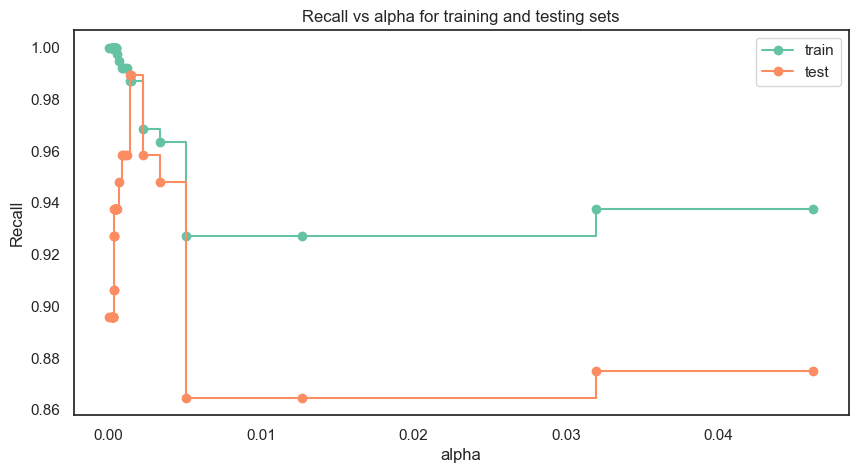

In [95]:
fig, ax = plt.subplots(figsize=(10,5))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(ccp_alphas, recall_train, marker='o', label="train",
        drawstyle="steps-post")
ax.plot(ccp_alphas, recall_test, marker='o', label="test",
        drawstyle="steps-post")
ax.legend()
plt.show()
   



We are gettingt a higher recall on test data between 0.002 to 0.005. Will choose alpha as 0.002.


Creating model with 0.002 ccp_alpha

In [96]:
best_model = DecisionTreeClassifier(ccp_alpha=0.002,
                       class_weight={0: 0.15, 1: 0.85}, random_state=1)
best_model.fit(X_train_dt, y_train_dt)

DecisionTreeClassifier(ccp_alpha=0.002, class_weight={0: 0.15, 1: 0.85},
                       random_state=1)

 Accuracy : Train : 0.9799949987496874  Test: 0.977
 Recall   : Train : 0.96875  Test: 0.9583333333333334


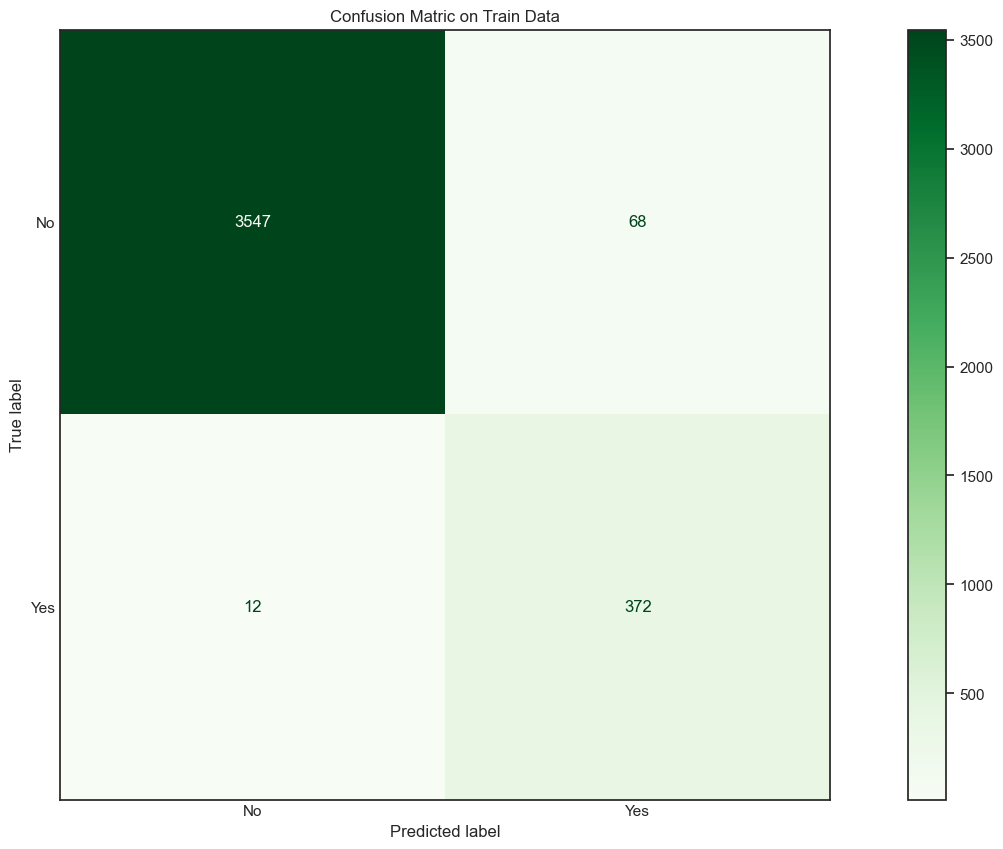

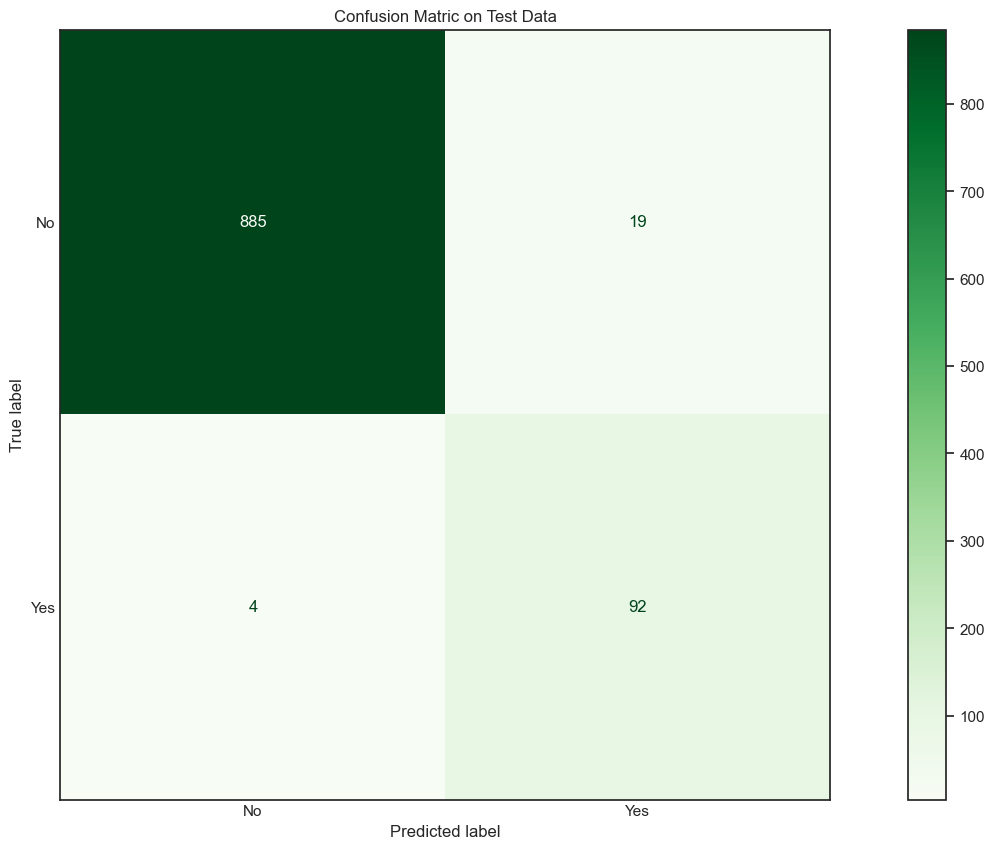

In [97]:
get_recall_score(best_model)



The Recall on train and test indicate we have created a generalized model. with 96 % accuracy and reduced False negatives.


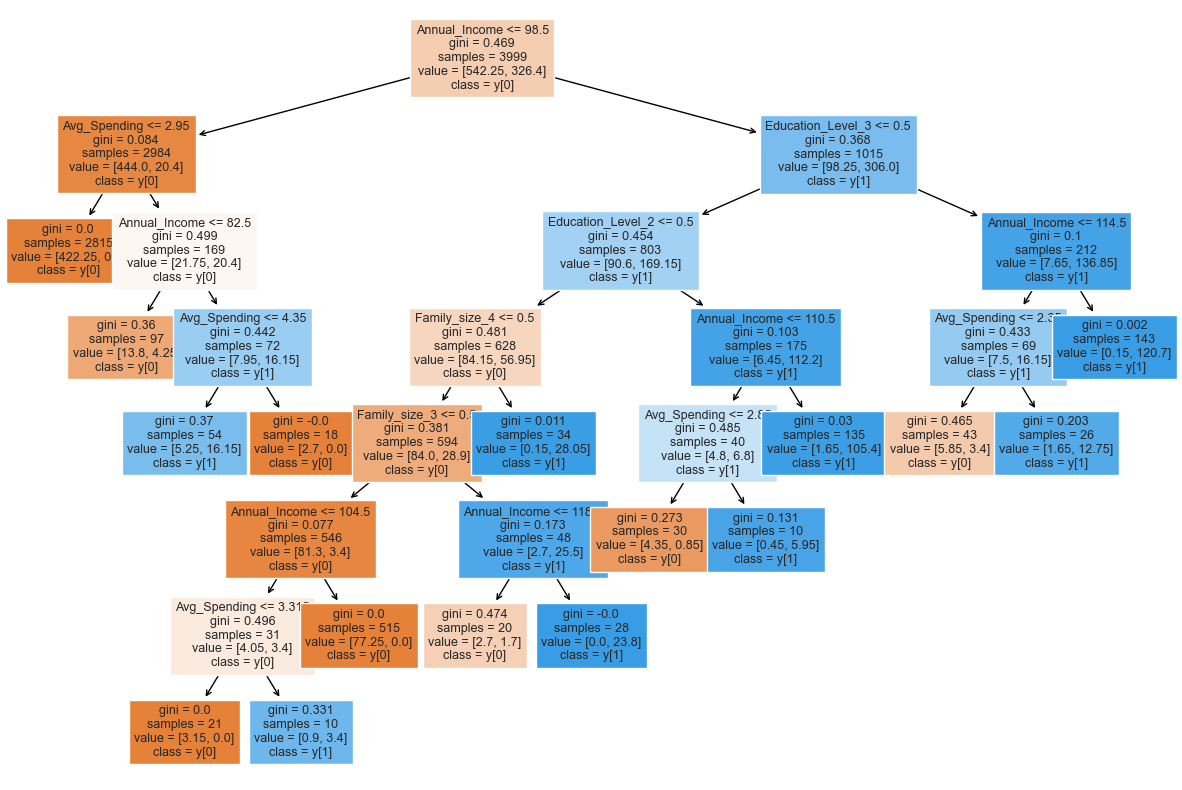

In [98]:
plt.figure(figsize=(15,10))

out = tree.plot_tree(best_model,feature_names=feature_names,filled=True,fontsize=9,node_ids=False,class_names=True)
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black')
        arrow.set_linewidth(1)
plt.show()

In [99]:
# Text report showing the rules of a decision tree -

print(tree.export_text(best_model,feature_names=feature_names,show_weights=True))

|--- Annual_Income <= 98.50
|   |--- Avg_Spending <= 2.95
|   |   |--- weights: [422.25, 0.00] class: 0
|   |--- Avg_Spending >  2.95
|   |   |--- Annual_Income <= 82.50
|   |   |   |--- weights: [13.80, 4.25] class: 0
|   |   |--- Annual_Income >  82.50
|   |   |   |--- Avg_Spending <= 4.35
|   |   |   |   |--- weights: [5.25, 16.15] class: 1
|   |   |   |--- Avg_Spending >  4.35
|   |   |   |   |--- weights: [2.70, 0.00] class: 0
|--- Annual_Income >  98.50
|   |--- Education_Level_3 <= 0.50
|   |   |--- Education_Level_2 <= 0.50
|   |   |   |--- Family_size_4 <= 0.50
|   |   |   |   |--- Family_size_3 <= 0.50
|   |   |   |   |   |--- Annual_Income <= 104.50
|   |   |   |   |   |   |--- Avg_Spending <= 3.31
|   |   |   |   |   |   |   |--- weights: [3.15, 0.00] class: 0
|   |   |   |   |   |   |--- Avg_Spending >  3.31
|   |   |   |   |   |   |   |--- weights: [0.90, 3.40] class: 1
|   |   |   |   |   |--- Annual_Income >  104.50
|   |   |   |   |   |   |--- weights: [77.25, 0.00] cl

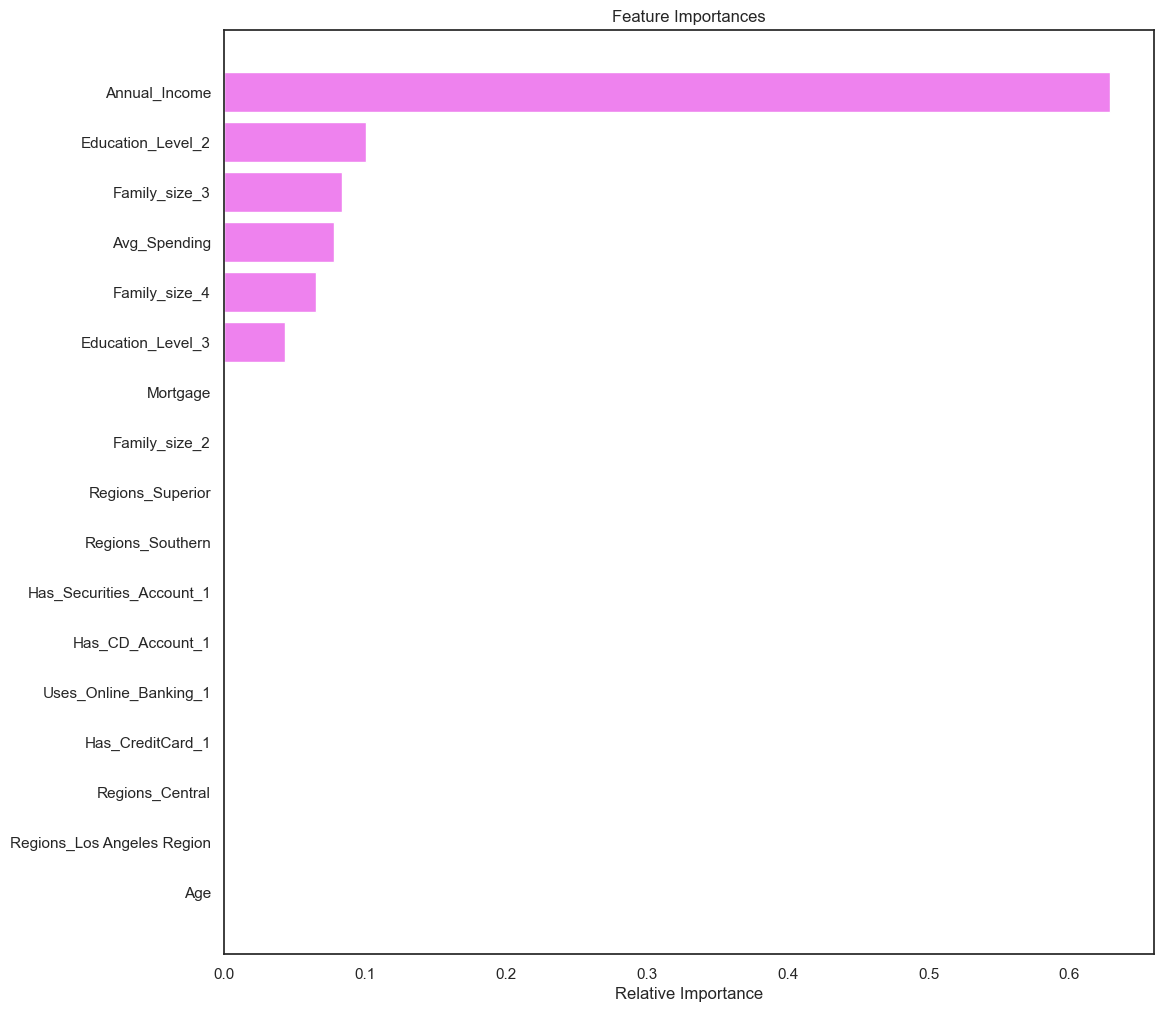

In [100]:
importances = best_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()



    We are getting a higher recall on test data between 0.002 to 0.005. Will choosed alpha as 0.002.
    The Recall on train and test indicate we have created a generalized model. with 96 % accuracy and reduced False negatives.
    Important features : Annual_Income, Graduate education, Family member 3 and 4, Avg_Spending, Advanced education, Age.
    This is the best model as false negative is only 6 on Testdata.



Comparing all the models based on Model Performance

In [101]:
comparison_frame = pd.DataFrame({'Model':['Logisitic Regression with Optimal Threshold 0.104',
                                          'Initial decision tree model',
                                          'Decision treee with hyperparameter tuning',
                                          'Decision tree with post-pruning'], 
                                          'Train_accuracy':[0.92,1,0.99,0.98],
                                          'Test_accuracy':[0.91,0.98,0.98,0.97],
                                          'Train_Recall':[0.90,1,0.92,0.98], 
                                          'Test_Recall':[0.88,0.86,0.84,0.96]})  

comparison_frame

,Model,Train_accuracy,Test_accuracy,Train_Recall,Test_Recall
0,Logisitic Regression with Optimal Threshold 0.104,0.92000,0.91000,0.90000,0.88000
1,Initial decision tree model,1.00000,0.98000,1.00000,0.86000
2,Decision treee with hyperparameter tuning,0.99000,0.98000,0.92000,0.84000
3,Decision tree with post-pruning,0.98000,0.97000,0.98000,0.96000




Decision tree model post pruning has given us best recall scores on data with 97% accuracy . Exploratory data analysis also suggested Annual_Income and education were important features in deciding if person will borrow personal loan. so choosing Decision Tree with post-pruning for our prediction.


In [102]:
best_model = DecisionTreeClassifier(ccp_alpha=0.002,
                       class_weight={0: 0.15, 1: 0.85}, random_state=1)
best_model.fit(X_train_dt, y_train_dt)

DecisionTreeClassifier(ccp_alpha=0.002, class_weight={0: 0.15, 1: 0.85},
                       random_state=1)

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       904
           1       0.83      0.96      0.89        96

    accuracy                           0.98      1000
   macro avg       0.91      0.97      0.94      1000
weighted avg       0.98      0.98      0.98      1000



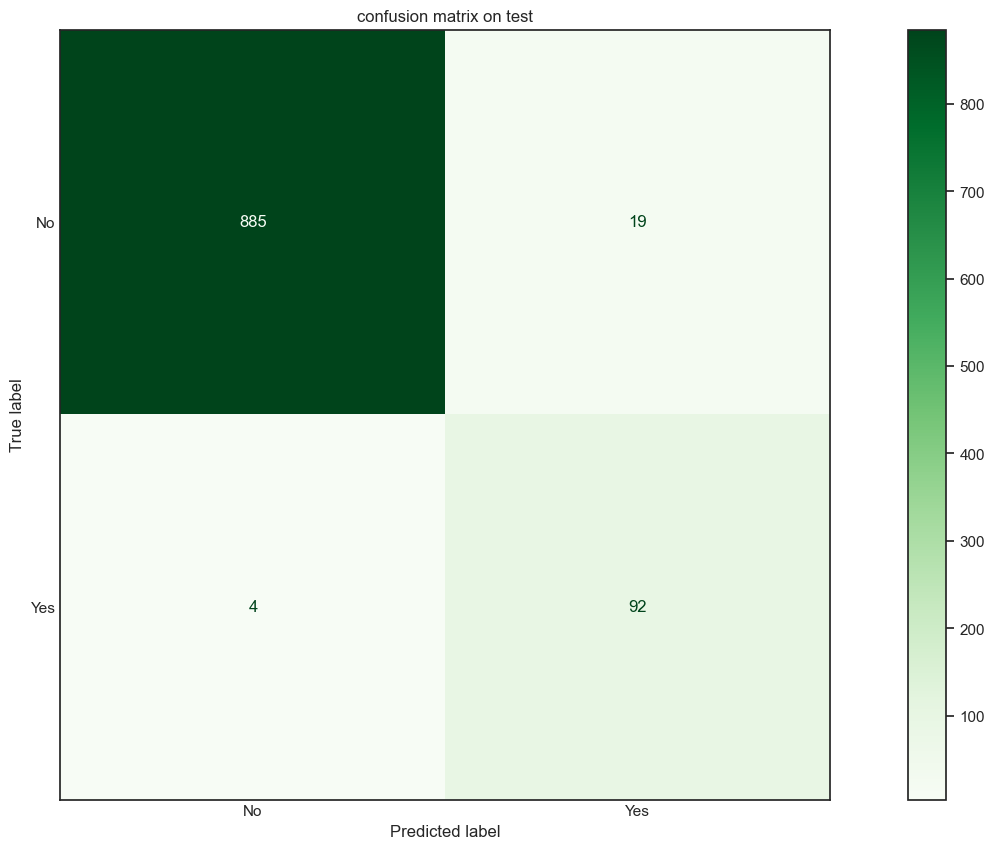

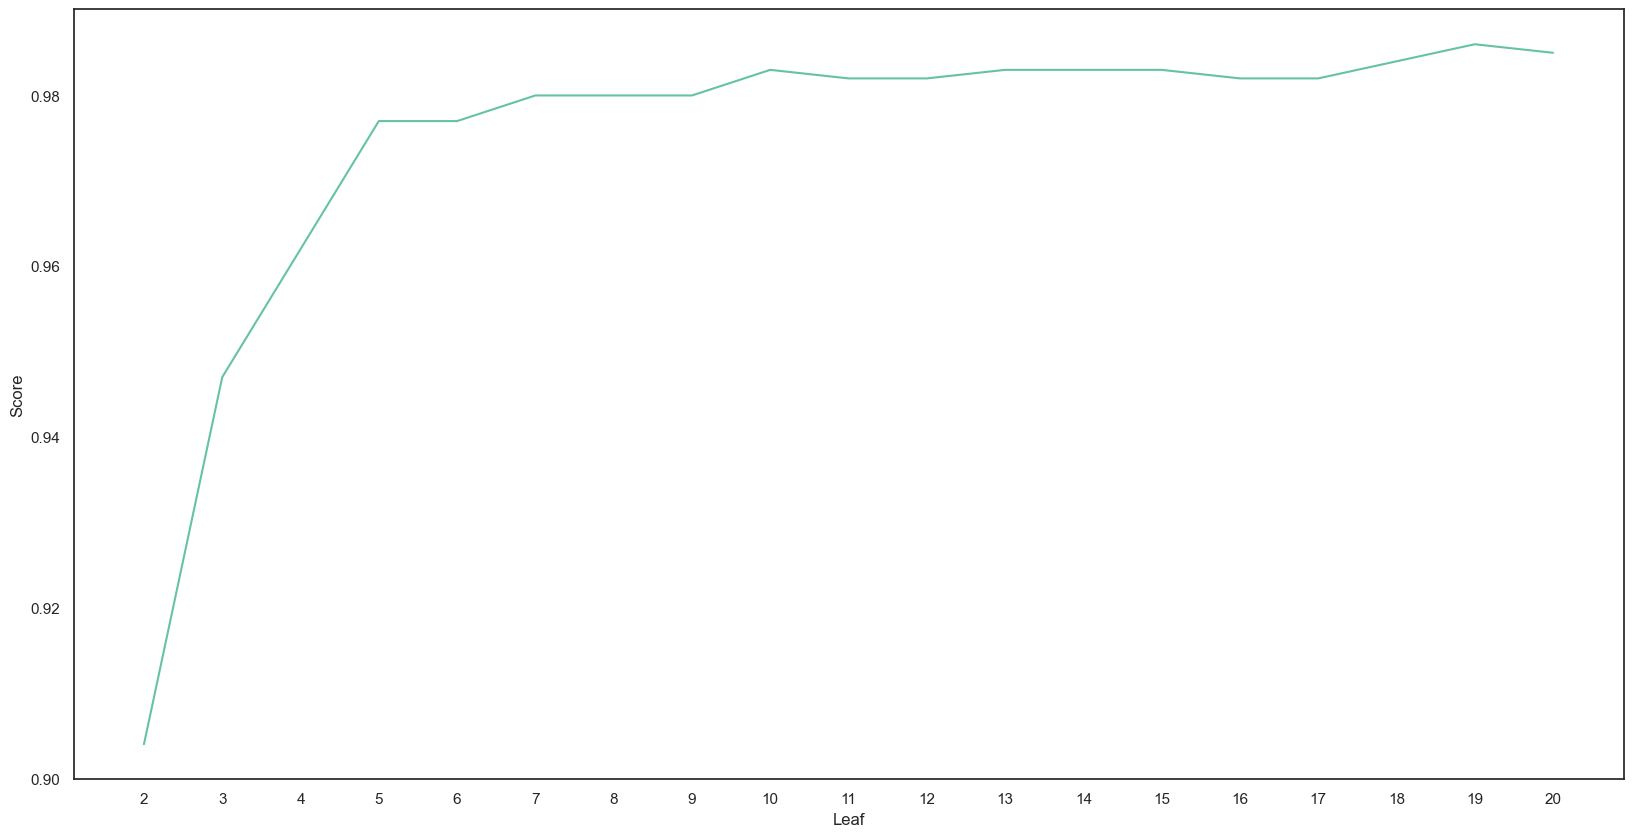

Decision Tree Accuracy: 98.60%


In [103]:
y_pred = best_model.predict(X_test_dt)
print(classification_report(y_test_dt,y_pred))
make_confusion_matrix(y_test,y_pred,"confusion matrix on test")

scoreListDT = []
for i in range(2,21):
    DTclassifier = DecisionTreeClassifier(max_leaf_nodes=i)
    DTclassifier.fit(X_train, y_train)
    scoreListDT.append(DTclassifier.score(X_test, y_test))
    
plt.plot(range(2,21), scoreListDT)
plt.xticks(np.arange(2,21,1))
plt.xlabel("Leaf")
plt.ylabel("Score")
plt.show()
DTAcc = max(scoreListDT)
print("Decision Tree Accuracy: {:.2f}%".format(DTAcc*100))



Observation

    After Post Pruning ,the false negative has reduced to 6.The accuracy on test data is 97% & Recall is 97% after choosing optimal cc-alpha.




Conclusion¶

    We analyzed the Personal Loan campaign data using EDA and by using different models like Logistic Regression and Decision Tree Classifier to build a likelihood of Customer buying Loan.
    First we built model using Logistic Regression and performance metric used was Recall. The most important features for classification were Annual_Income,Education, CD account ,Family and Avg_Spending .
    Coefficient of Annual_Income, Graduate and Advanced Education, Family_3,Family 4,Avg_Spending,CD account,Age, are positive , ie a one unit increase in these will lead to increase in chances of a person borrowing loan
    Coefficient of Securities account,online ,Family_2 credit card are negative increase in these will lead to decrease in chances of a person borrowing a loan.
    We also improved the performance using ROC-AUC curve and optimal threshold .This was best model with high recall and accuracy .
    Decision tree can easily overfit. They require less datapreprocessing compared to logistic Regression and are easy to understand.
    We used decision trees with prepruning and post pruning. The Post pruning model gave 96 % recall with 97% accuracy.
    Annual_Income, Customers with graduate degree, customers having 3 family members are some of the most important variables in predicting if the customers will purchase a personal loan.



### Actionable Insights & Recommendations

Misclassification Analysis

In [104]:
misclass_df = X_test_dt.copy()

In [105]:
misclass_df['Actual']=y_test_dt
misclass_df['Predicted'] = y_pred

([<matplotlib.patches.Wedge at 0x18a0342aea0>,
 [Text(-1.050350983068654, 0.3267457916587637, ''),
  Text(1.0503509677725784, -0.32674584082924163, '')],
 [Text(-0.5729187180374475, 0.17822497726841657, '90.4%'),
  Text(0.5729187096941336, -0.17822500408867725, '9.6%')])

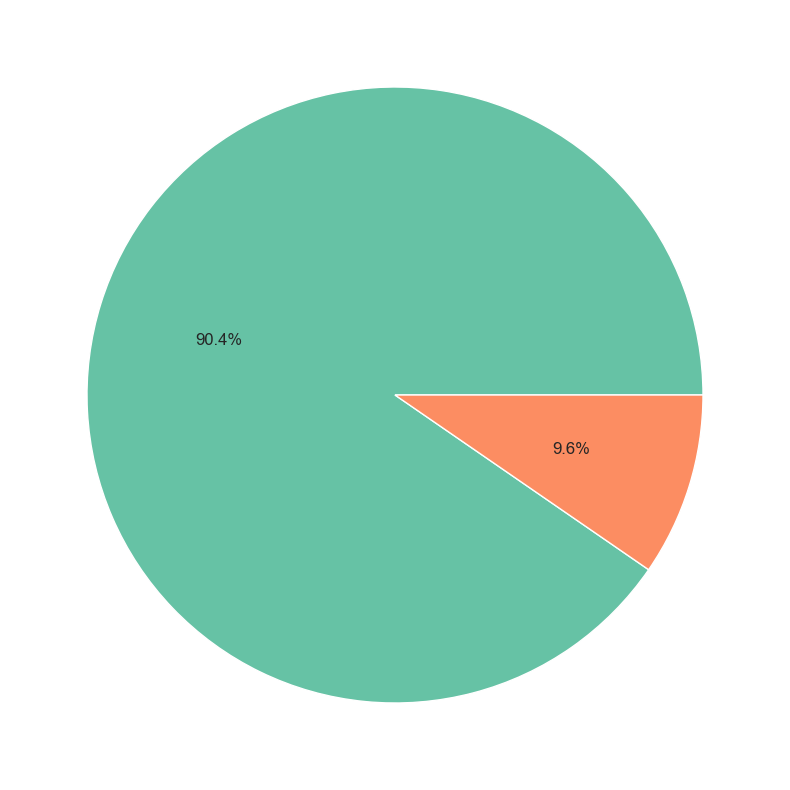

In [106]:
plt.pie(data=misclass_df,x=misclass_df["Actual"].value_counts(),autopct='%1.1f%%')

([<matplotlib.patches.Wedge at 0x18a03277980>,
 [Text(-1.033793144505799, 0.37586132332658534, ''),
  Text(1.033793144505799, -0.3758613233265859, '')],
 [Text(-0.5638871697304358, 0.20501526726904654, '88.9%'),
  Text(0.5638871697304357, -0.2050152672690468, '11.1%')])

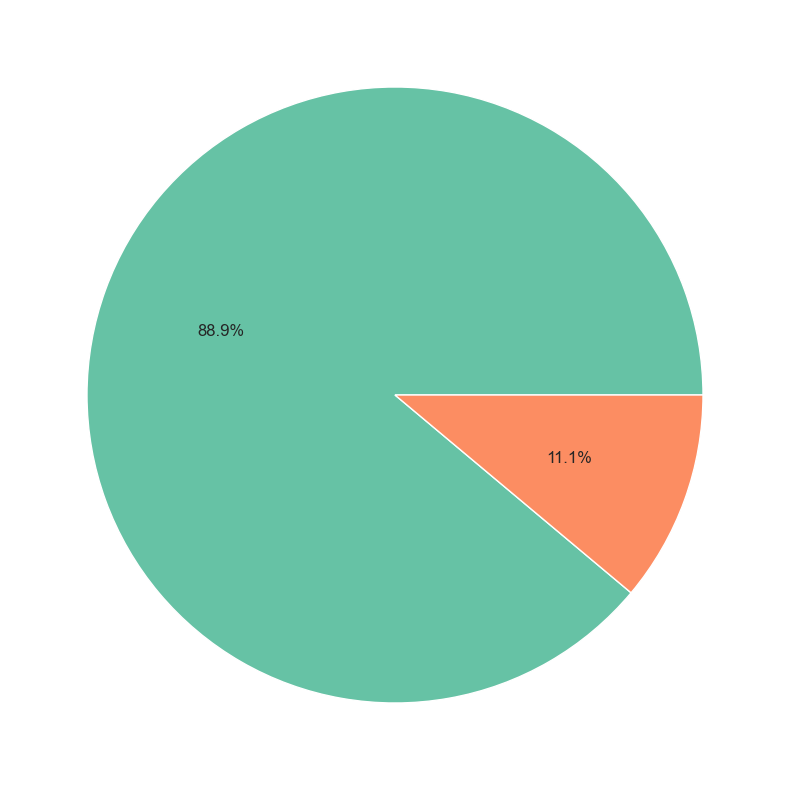

In [107]:
plt.pie(data=misclass_df,x=misclass_df["Predicted"].value_counts(),autopct='%1.1f%%')

Percentage of value predicted by our model has been very close to the actual values. Lets find out False Negative and False Positive observations

In [108]:
pd.crosstab(misclass_df['Predicted'],misclass_df['Actual'],margins=True)

Actual,0,1,All
Predicted,,,
0,885,4,889
1,19,92,111
All,904,96,1000


<Axes: xlabel='Predicted'>

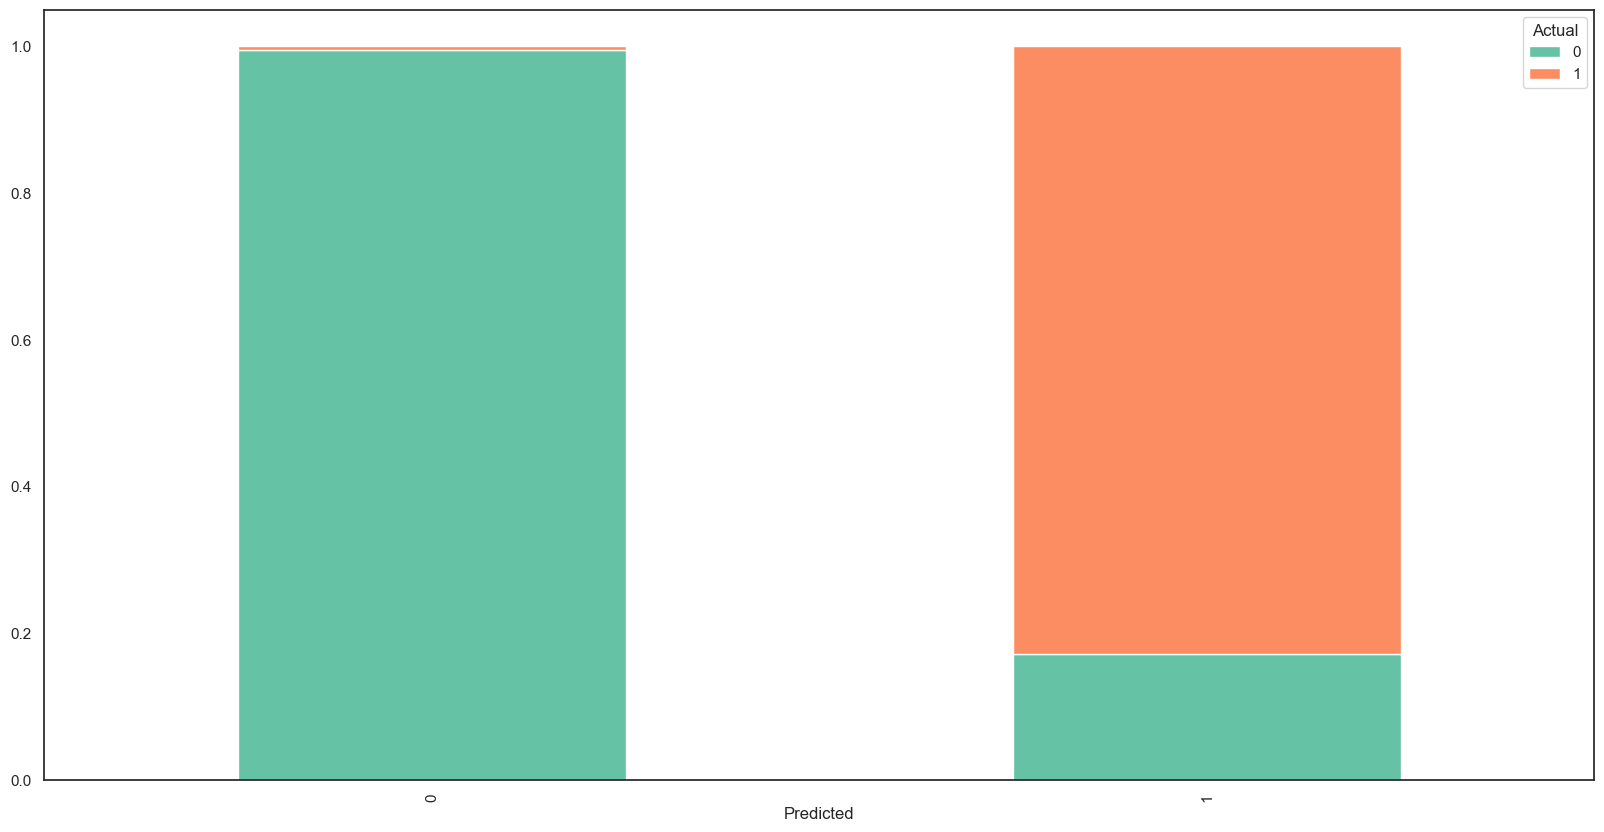

In [109]:
pd.crosstab(misclass_df['Predicted'],misclass_df['Actual'],normalize='index').plot(kind='bar',stacked=True)

In [110]:
# Rows that were classified as Negative when they were actually positive
fn_rows = misclass_df[(misclass_df['Actual'] == 1) & (misclass_df['Predicted'] == 0)]

In [111]:
False_negative= df_Decision[df_Decision.index.isin(fn_rows.index.values)].copy()
False_negative

,Age,Annual_Income,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,Regions
1129,30,73,3,3.30000,1,0,1,0,1,1,1,Bay Area
1177,28,71,1,3.30000,2,149,1,1,1,1,0,Los Angeles Region
1518,43,64,4,3.00000,3,221,1,0,0,1,0,Bay Area
1577,34,65,1,3.00000,1,227,1,0,0,1,0,Southern




Our model predicted 6 customers wrongly. On analyzing the Annual_Income , Education,Family , we can see the Annual_Income is not in range of High Annual_Income group and education is undergrad for most of them and there average spending is also low. These cases are some exceptions.


In [112]:
# Rows that were classified as postive when they were actually negative
fp_rows = misclass_df[(misclass_df['Actual'] == 0) & (misclass_df['Predicted'] == 1)]
fp_rows
False_Positive= df_Decision[df_Decision.index.isin(fp_rows.index.values)].copy()
False_Positive

,Age,Annual_Income,Family_size,Avg_Spending,Education_Level,Mortgage,Has_Consumer_Loan,Has_Securities_Account,Has_CD_Account,Uses_Online_Banking,Has_CreditCard,Regions
185,39,115,1,1.00000,3,0,0,0,0,1,0,Southern
621,41,114,2,1.80000,2,0,0,0,0,1,0,Los Angeles Region
640,43,85,1,3.70000,3,327,0,1,0,1,0,Bay Area
746,62,85,4,3.40000,2,0,0,0,0,1,0,Bay Area
932,51,112,3,1.80000,2,0,0,1,1,1,1,Bay Area
973,43,85,1,4.00000,3,287,0,0,0,1,0,Southern
1263,35,85,4,4.00000,3,0,0,0,0,1,0,Southern
1303,29,112,2,2.00000,2,382,0,1,0,0,0,Bay Area
1401,40,84,1,3.70000,3,0,0,0,0,1,0,Bay Area
1910,43,83,2,3.80000,3,112,0,0,0,0,0,Central




On analyzing the Education , we can see most of them have education as Advance or Graduate . These cases are some exceptions.


**Recommendation**

    Decision trees doesn't require to much data preparation or handling of outliers like logistic regression. They are easy to understand. Decision tress can easily overfit , so we have to be careful using decision tree.
    Based on EDA, logistic Regression , Decision tree , Annual_Income ,Educatoin,Family,Avg_Spending are most important factor.
    Customers who have Annual_Income above 98k dollars , Advance/graduate level education, a family of more than 2, such customers have higher chances of taking personal loans.
    So for this campaign we can have different profiles for customers.
    High Profile Clients :-Higher Annual_Income,Advanced/Graduate level education, 3 /4 Family members,high spending
    Average Profile :- Medium Annual_Income group,Graduate level education.3/4Family members,medium spending
    Low Profile:-Lower Annual_Income group,undergrads ,3/4Family Member,low spending
    Customer Average Spending and Mortages can also be looked upon as based on EDA and logistic Regression this parameters also play some role in likelihood of buy loan.
    We can 1st target high profile customers , by providing them with a personal relationship managers who can address there concerns and can pursue them to buy loan from the bank with completive interest rates.
    Prequalifying for Loan can also attract more customers.
    Our 2nd target would be Medium profile customers.
    The model cannot identify well if there are some exceptional cases when low profile customer is ready to buy a personal loan.

### 5.3 Random Forest

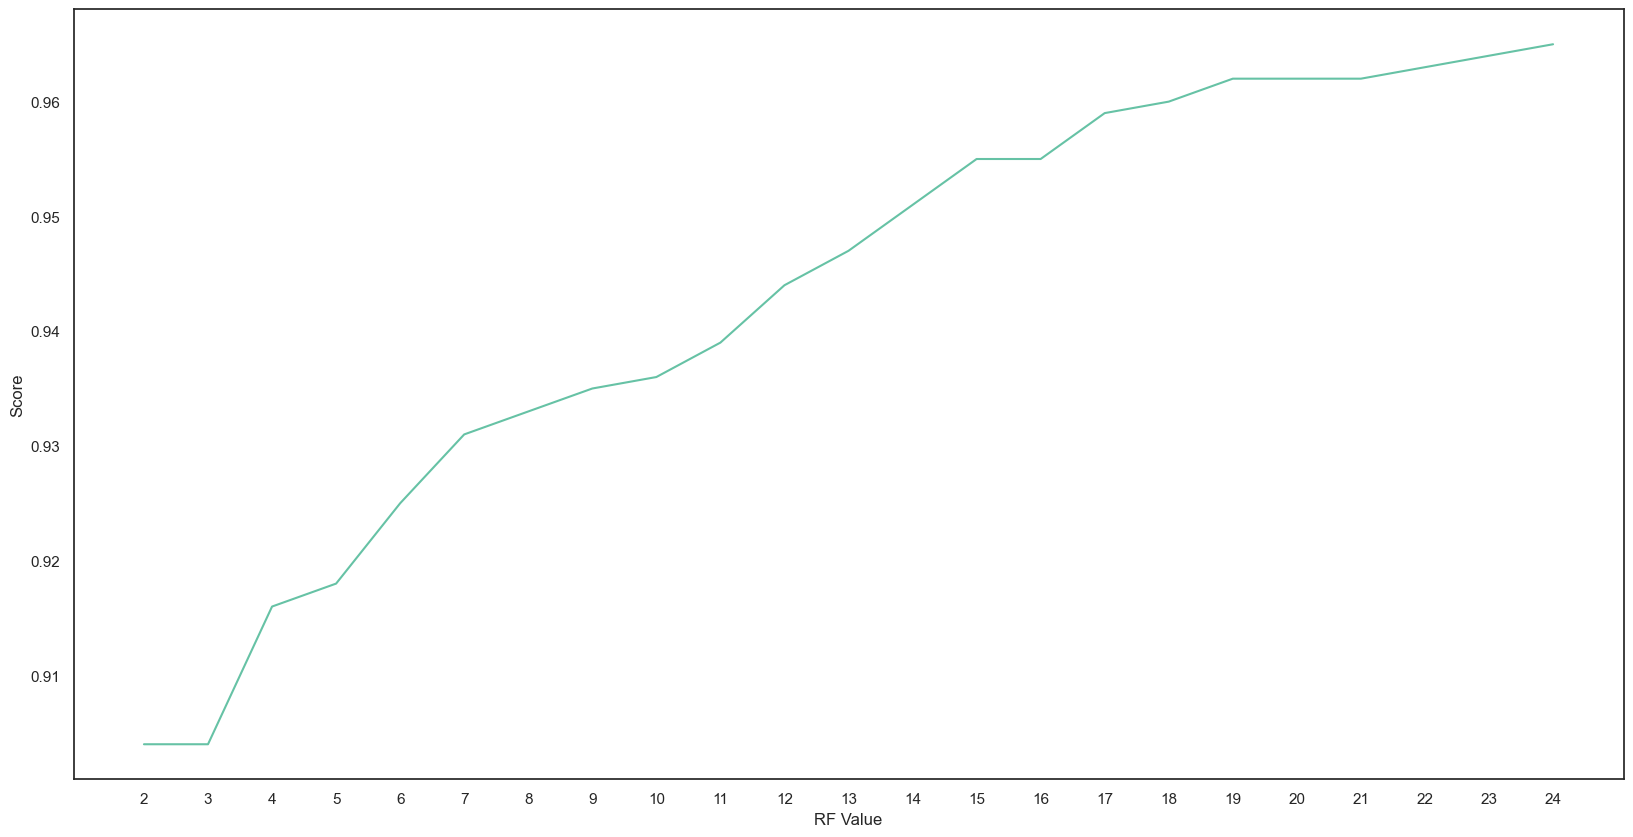

Random Forest Accuracy:  96.50%


In [113]:
scoreListRF = []
for i in range(2,25):
    RFclassifier = RandomForestClassifier(n_estimators = 1000, random_state = 1, max_leaf_nodes=i)
    RFclassifier.fit(X_train, y_train)
    scoreListRF.append(RFclassifier.score(X_test, y_test))
    
plt.plot(range(2,25), scoreListRF)
plt.xticks(np.arange(2,25,1))
plt.xlabel("RF Value")
plt.ylabel("Score")
plt.show()
RFAcc = max(scoreListRF)
print("Random Forest Accuracy:  {:.2f}%".format(RFAcc*100))

### 5.4 K-Nearest Neighbors (K-NN)

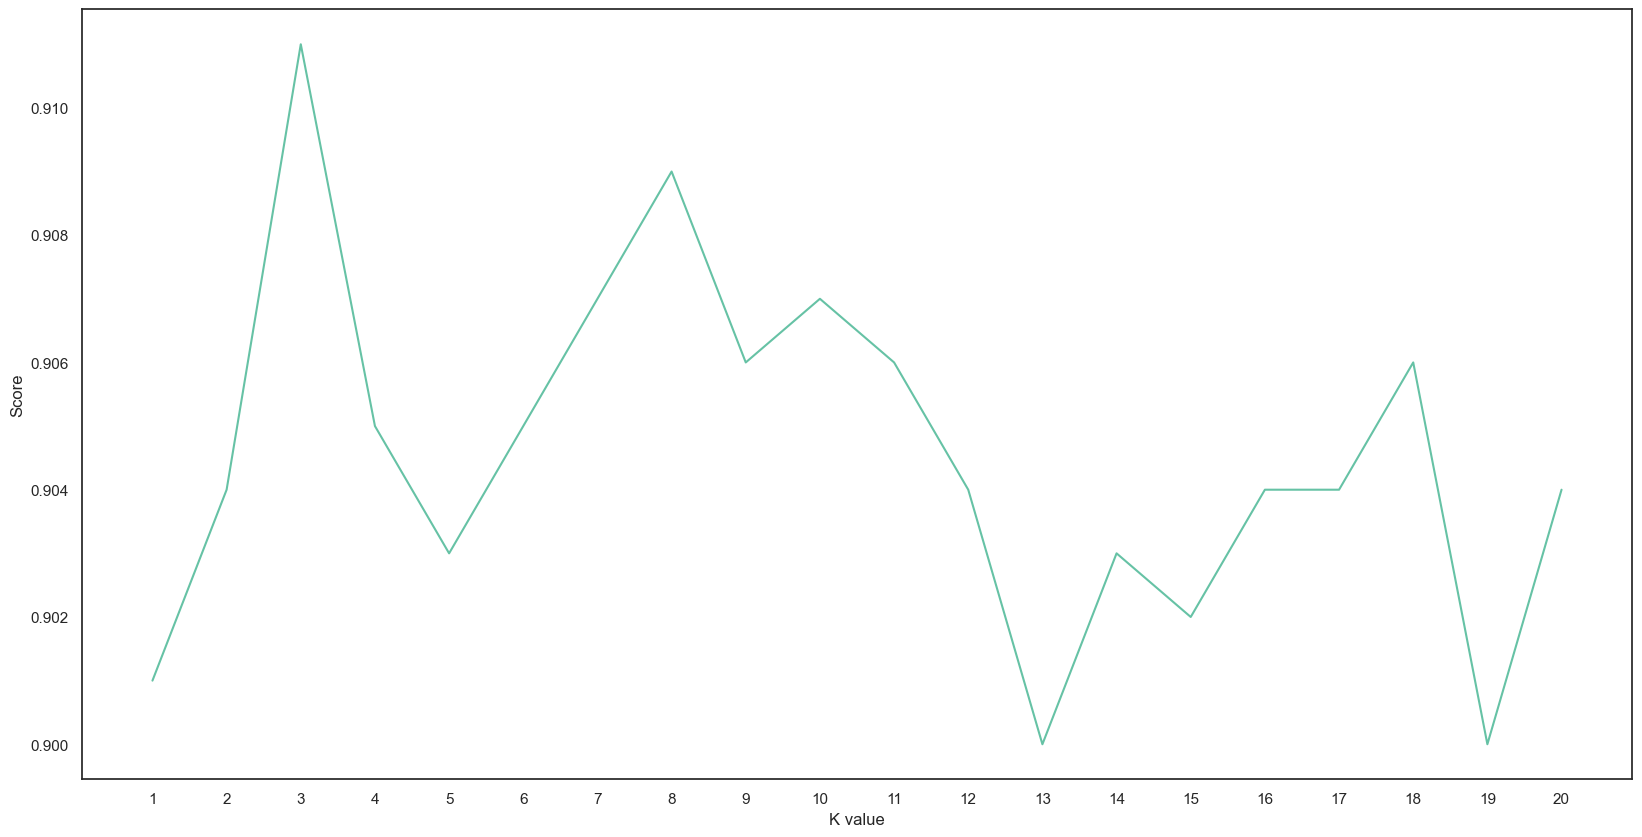

KNN best accuracy: 91.10%


In [114]:
scoreListknn = []
for i in range(1,21):
    KNclassifier = KNeighborsClassifier(n_neighbors = i)
    KNclassifier.fit(X_train, y_train)
    scoreListknn.append(KNclassifier.score(X_test, y_test))
    
plt.plot(range(1,21), scoreListknn)
plt.xticks(np.arange(1,21,1))
plt.xlabel("K value")
plt.ylabel("Score")
plt.show()
KNAcc = max(scoreListknn)
print("KNN best accuracy: {:.2f}%".format(KNAcc*100))

### 5.5 Naive Bayes

In [115]:
NBclassifier1 = CategoricalNB()
NBclassifier1.fit(X_train, y_train)

y_pred = NBclassifier1.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import accuracy_score
NBAcc1 = accuracy_score(y_pred,y_test)
print('Categorical Naive Bayes accuracy: {:.2f}%'.format(NBAcc1*100))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96       904
           1       0.70      0.51      0.59        96

    accuracy                           0.93      1000
   macro avg       0.82      0.74      0.78      1000
weighted avg       0.93      0.93      0.93      1000

[[883  21]
 [ 47  49]]
Categorical Naive Bayes accuracy: 93.20%


### 5.6 Adaboost

In [116]:
# Initialize the AdaBoost classifier
adaboost_classifier = AdaBoostClassifier(n_estimators=100, random_state=42)

# Train the classifier
adaboost_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = adaboost_classifier.predict(X_test)

# Evaluate the classifier
ADAcc = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

# Print the results
print(f"Accuracy: {ADAcc:.2f}")
print("Classification Report:")
print(report)

Accuracy: 0.98
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       904
           1       0.93      0.82      0.87        96

    accuracy                           0.98      1000
   macro avg       0.96      0.91      0.93      1000
weighted avg       0.98      0.98      0.98      1000



# 7. Model Selection 

In [117]:
compare = pd.DataFrame({'Model': ['Logistic Regression', 'K Neighbors', 
                                  'Gaussian NB', 'Decision Tree', 
                                  'Random Forest', 'Adaboost'], 
                        'Accuracy': [LRAcc*100, KNAcc*100,NBAcc1*100, DTAcc*100, 
                                     RFAcc*100, ADAcc*100]})
compare.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
3,Decision Tree,98.60000
5,Adaboost,97.70000
4,Random Forest,96.50000
2,Gaussian NB,93.20000
1,K Neighbors,91.10000
0,Logistic Regression,89.70000


#### Comparison and Analysis

Based on the Accuracy comparision Decision Tree Model is 98.4%.   
<b>As a result we can select Decision Tree Model to build a predictive model to identify depositors with a high probability of purchasing a consumer loan.!<b>